# DNAffinity: Data Exploration and Preprocessing Preparation

## 1. Introduction

This notebook explores the DNA structural and physicochemical descriptors and the selected HT-SELEX datasets used in DNAffinity. The aim is to understand data quality, feature distributions, relationships and dimensionality before building the sequence-level modelling dataset.

The analysis covers tetramer and hexamer descriptors (AVG, FCE, electrostatic and ion-related features) and 10-mer HT-SELEX data from 11 transcription factors. Sequence-level feature mapping and model-ready preprocessing will be addressed after the exploratory analysis.

## 2. Setup and imports

Import the libraries used for data handling, numerical analysis and visualisation, and define the repository root for file access.

All figures generated in this notebook are saved automatically in the `plots_EDA/` directory at the repository root.

In [71]:
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Repository root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Repository:", ROOT)


# SELEX data directory
SELEX_DIR = ROOT / "data" / "selex"


# Save all EDA figures in a dedicated directory
PLOT_DIR = ROOT / "notebooks" / "plots_EDA"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print("EDA plots directory:", PLOT_DIR)

Repository: /home/oscar/DNAffinity
EDA plots directory: /home/oscar/DNAffinity/notebooks/plots_EDA


## 3. Data loading

We load the combined tetramer and hexamer feature tables, together with the selected HT-SELEX cycle for each transcription factor. The combined DNA tables contain the sequence and its structural and physicochemical descriptors.

In [72]:
# Define directories
TETRAMER_DIR = SELEX_DIR / "tetramer"
HEXAMER_DIR = SELEX_DIR / "hexamer"

# Load tetramer datasets
avg_tetramer = pd.read_csv(TETRAMER_DIR / "avg_tetramer.dat", sep=r"\s+")
fce_tetramer = pd.read_csv(TETRAMER_DIR / "fce_tetramer.dat", sep=r"\s+")
electrostatic_tetramer = pd.read_csv(TETRAMER_DIR / "electrostatic_tetramer.dat", sep=r"\s+")
ion_vec_tetramer = pd.read_csv(TETRAMER_DIR / "ion_vec_tetramer.dat", sep=r"\s+")

# Load hexamer datasets
avg_hexamer = pd.read_csv(HEXAMER_DIR / "avg_hexamer.dat", sep=r"\s+")
fce_hexamer = pd.read_csv(HEXAMER_DIR / "fce_hexamer.dat", sep=r"\s+")
electrostatic_hexamer = pd.read_csv(HEXAMER_DIR / "electrostatic_hexamer.dat", sep=r"\s+")
ion_vec_hexamer = pd.read_csv(HEXAMER_DIR / "ion_vec_hexamer.dat", sep=r"\s+")

In [73]:
# Selected SELEX cycle for each transcription factor
selex_cycles = {
    "Gata4": 4,
    "Zfp24": 5,
    "arid3": 6,
    "hoxd1": 3,
    "nkx3": 6,
    "pax3-like": 5,
    "six1": 5,
    "tbx15": 5,
    "telf": 5,
    "uncxb": 5,
    "xbpc": 5
}

# Load SELEX datasets
selex_data = {}

for protein, cycle in selex_cycles.items():
    path = SELEX_DIR / "transcription_factors" / protein / f"{cycle}.txt"
    selex_data[protein] = pd.read_csv(path, sep="\t")

print(f"Loaded {len(selex_data)} transcription factor datasets.")

Loaded 11 transcription factor datasets.


In [74]:
print("Tetramer datasets:")
for name, df in {
    "Average": avg_tetramer,
    "Stiffness": fce_tetramer,
    "Electrostatic": electrostatic_tetramer,
    "Ion vector": ion_vec_tetramer
}.items():
    print(f"{name}: {df.shape}")

print("\nHexamer datasets:")
for name, df in {
    "Average": avg_hexamer,
    "Stiffness": fce_hexamer,
    "Electrostatic": electrostatic_hexamer,
    "Ion vector": ion_vec_hexamer
}.items():
    print(f"{name}: {df.shape}")

print("\nSELEX datasets:")
for protein, df in selex_data.items():
    print(f"{protein}: {df.shape}")

Tetramer datasets:
Average: (256, 7)
Stiffness: (256, 36)
Electrostatic: (255, 6)
Ion vector: (256, 7)

Hexamer datasets:
Average: (4096, 7)
Stiffness: (4096, 36)
Electrostatic: (4096, 6)
Ion vector: (4096, 11)

SELEX datasets:
Gata4: (126624, 6)
Zfp24: (406165, 6)
arid3: (273249, 6)
hoxd1: (887634, 7)
nkx3: (963575, 6)
pax3-like: (427916, 6)
six1: (944350, 6)
tbx15: (25991, 6)
telf: (691492, 6)
uncxb: (234129, 6)
xbpc: (463571, 6)


### 3.1. DNA feature groups

The combined tables contain four groups of descriptors:

- **AVG:** six equilibrium helical parameters (SHIFT, SLIDE, RISE, TILT, ROLL and TWIST), describing the relative position and orientation of neighbouring base pairs.
- **FCE:** a 6 × 6 stiffness matrix describing resistance to deformation and coupling between the six degrees of freedom. The matrix is symmetric, so it contains 21 unique elements (six diagonal and 15 off-diagonal values).
- **Electrostatic:** five discrete descriptors (`e1`–`e5`).
- **Ion-related:** six descriptors for tetramers (`m1`–`m3`, `j1`–`j3`) and ten for hexamers (`m0`–`m4`, `j0`–`j4`). Their precise physical meaning is not documented in the repository, so they are treated descriptively.

In [75]:
# Load combined tetramer and hexamer feature tables
#is it necessary to load all the features 
input_tetramer = pd.read_csv(
    TETRAMER_DIR / "input_tetramer.dat",
    sep=r"\s+"
)

input_hexamer = pd.read_csv(
    HEXAMER_DIR / "input_hexamer.dat",
    sep=r"\s+"
)

In [76]:
print("Tetramer dataset:")
print("Dimensions:", input_tetramer.shape)
print("Number of unique sequences:", input_tetramer["SEQUENCE"].nunique())
print("Number of features:", input_tetramer.shape[1] - 1)

print("\nHexamer dataset:")
print("Dimensions:", input_hexamer.shape)
print("Number of unique sequences:", input_hexamer["SEQUENCE"].nunique())
print("Number of features:", input_hexamer.shape[1] - 1)

Tetramer dataset:
Dimensions: (256, 54)
Number of unique sequences: 256
Number of features: 53

Hexamer dataset:
Dimensions: (4096, 58)
Number of unique sequences: 4096
Number of features: 57


In [77]:
# Load combined tetramer and hexamer feature tables

input_tetramer = pd.read_csv(
    TETRAMER_DIR / "input_tetramer.dat",
    sep=r"\s+"
)

input_hexamer = pd.read_csv(
    HEXAMER_DIR / "input_hexamer.dat",
    sep=r"\s+"
)
tetramer_features = set(input_tetramer.columns) - {"SEQUENCE"}
hexamer_features = set(input_hexamer.columns) - {"SEQUENCE"}

print("Features only in tetramers:")
print(sorted(tetramer_features - hexamer_features))

print("\nFeatures only in hexamers:")
print(sorted(hexamer_features - tetramer_features))

Features only in tetramers:
[]

Features only in hexamers:
['j0', 'j4', 'm0', 'm4']


## 4. Initial Data Inspection

Before performing exploratory data analysis, it is important to assess the quality and structure of the datasets.

In this section, we examine the tetramer and hexamer feature tables to identify potential data quality issues, including missing values, duplicated sequences and unexpected data types.

We also calculate descriptive statistics to obtain an initial overview of the numerical features and their variability.

In [78]:
# Check structure and data quality of the combined DNA feature tables
quality_rows = []
for name, df in {"Tetramer": input_tetramer, "Hexamer": input_hexamer}.items():
    quality_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Unique sequences": df["SEQUENCE"].nunique(),
        "Missing values": int(df.isna().sum().sum()),
        "Duplicated sequences": int(df["SEQUENCE"].duplicated().sum()),
        "Sequence lengths": sorted(df["SEQUENCE"].str.len().dropna().unique().tolist())
    })

display(pd.DataFrame(quality_rows))

print("Tetramer data types:\n", input_tetramer.dtypes.value_counts())
print("\nHexamer data types:\n", input_hexamer.dtypes.value_counts())

,Dataset,Rows,Columns,Unique sequences,Missing values,Duplicated sequences,Sequence lengths
0,Tetramer,256,54,256,0,0,[4]
1,Hexamer,4096,58,4096,0,0,[6]


Tetramer data types:
 float64    48
int64       5
object      1
Name: count, dtype: int64

Hexamer data types:
 float64    52
int64       5
object      1
Name: count, dtype: int64


The quality checks above summarise sequence uniqueness, missing values, sequence lengths and data types. The descriptive statistics below provide an overview of the numerical ranges and variability of the descriptors.

### 4.1. Descriptive statistics

We summarise the numerical descriptors to compare their scales and variability across tetramers and hexamers.

In [79]:
# Descriptive statistics for tetramers
tetramer_stats = input_tetramer.drop(columns="SEQUENCE").describe().T

# Descriptive statistics for hexamers
hexamer_stats = input_hexamer.drop(columns="SEQUENCE").describe().T

#display(tetramer_stats)
#display(hexamer_stats)

#### Initial observations

The descriptor groups have different numerical scales and distributions. AVG and FCE contain continuous structural parameters, electrostatic descriptors are discrete, and ion-related descriptors are positive-valued. The physical interpretation of the individual ion-related columns is not specified in the repository.

## 5. Feature distributions

We compare the distributions of the structural and physicochemical descriptors between tetramers and hexamers. These plots provide an overview of feature variability and distribution shape.

### 5.1. Average helical parameters (AVG)

The six AVG parameters describe the relative position and orientation of neighbouring base pairs. Their distributions are compared between tetramers and hexamers.

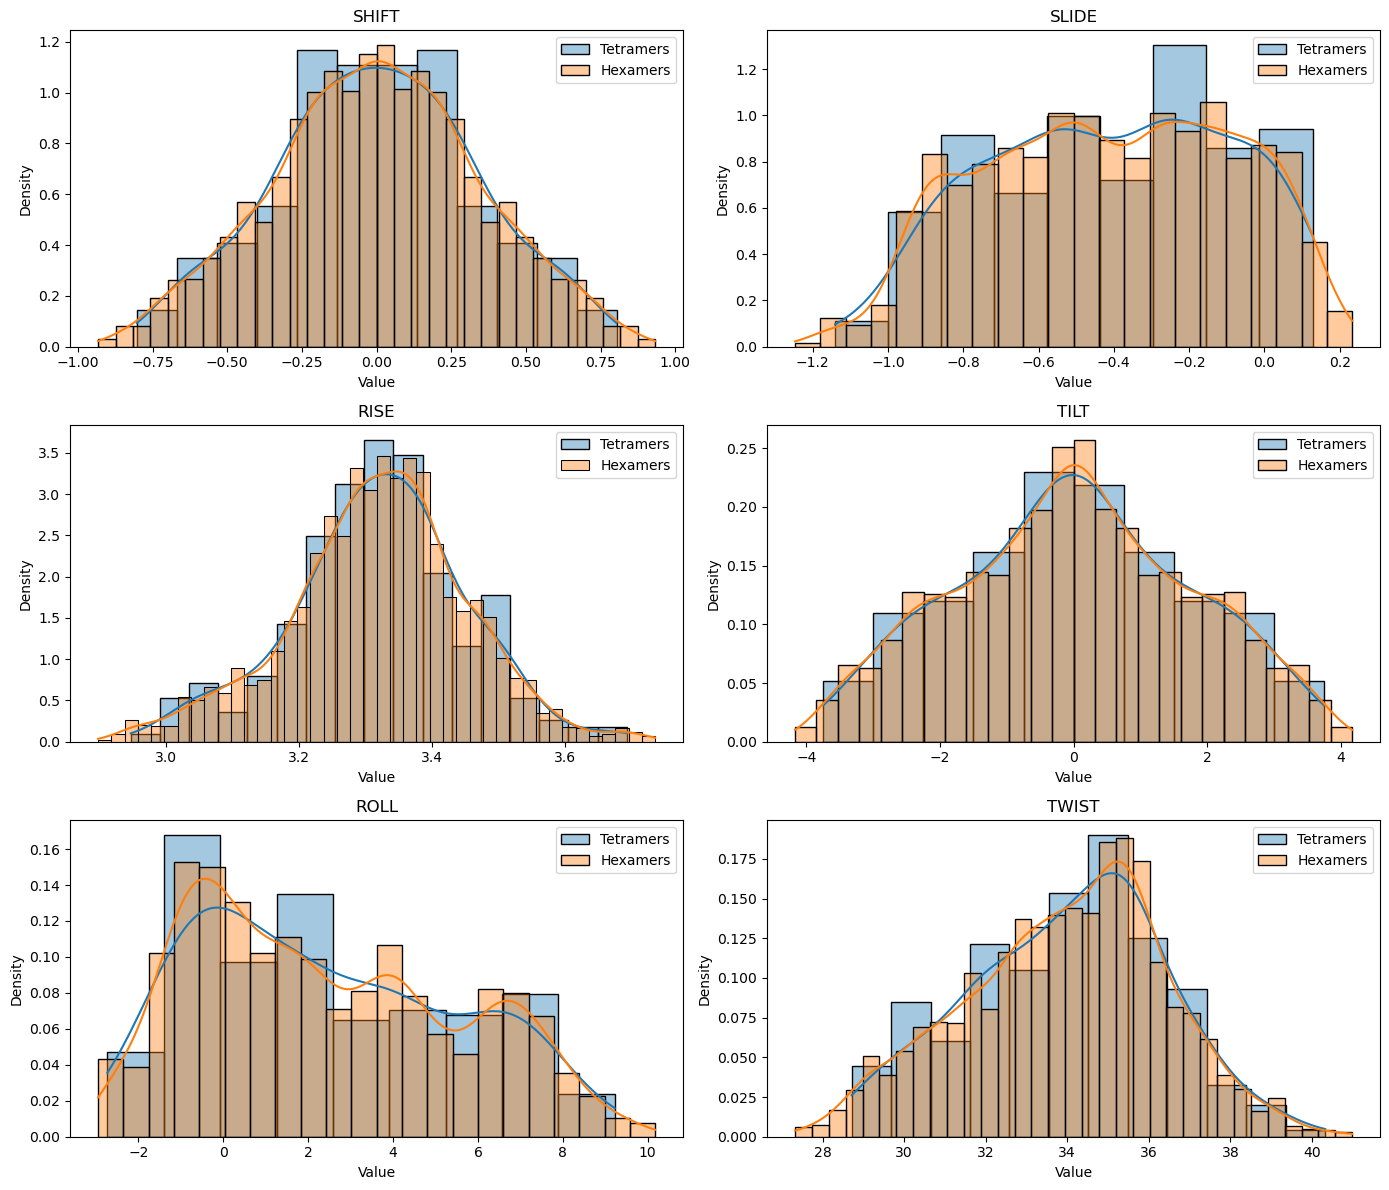

In [80]:
avg_features = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, avg_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)
    
    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)
    
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()

fig.savefig(PLOT_DIR / "avg_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


#### Observations

The AVG distributions differ in shape and variability across the six helical parameters. Some are more symmetric, while others show skewness or broader ranges.

### 5.2. Stiffness matrix (FCE)

#### 5.2.1. Diagonal elements

The diagonal elements describe stiffness along each of the six DNA deformation degrees of freedom. Their distributions are compared between tetramers and hexamers.

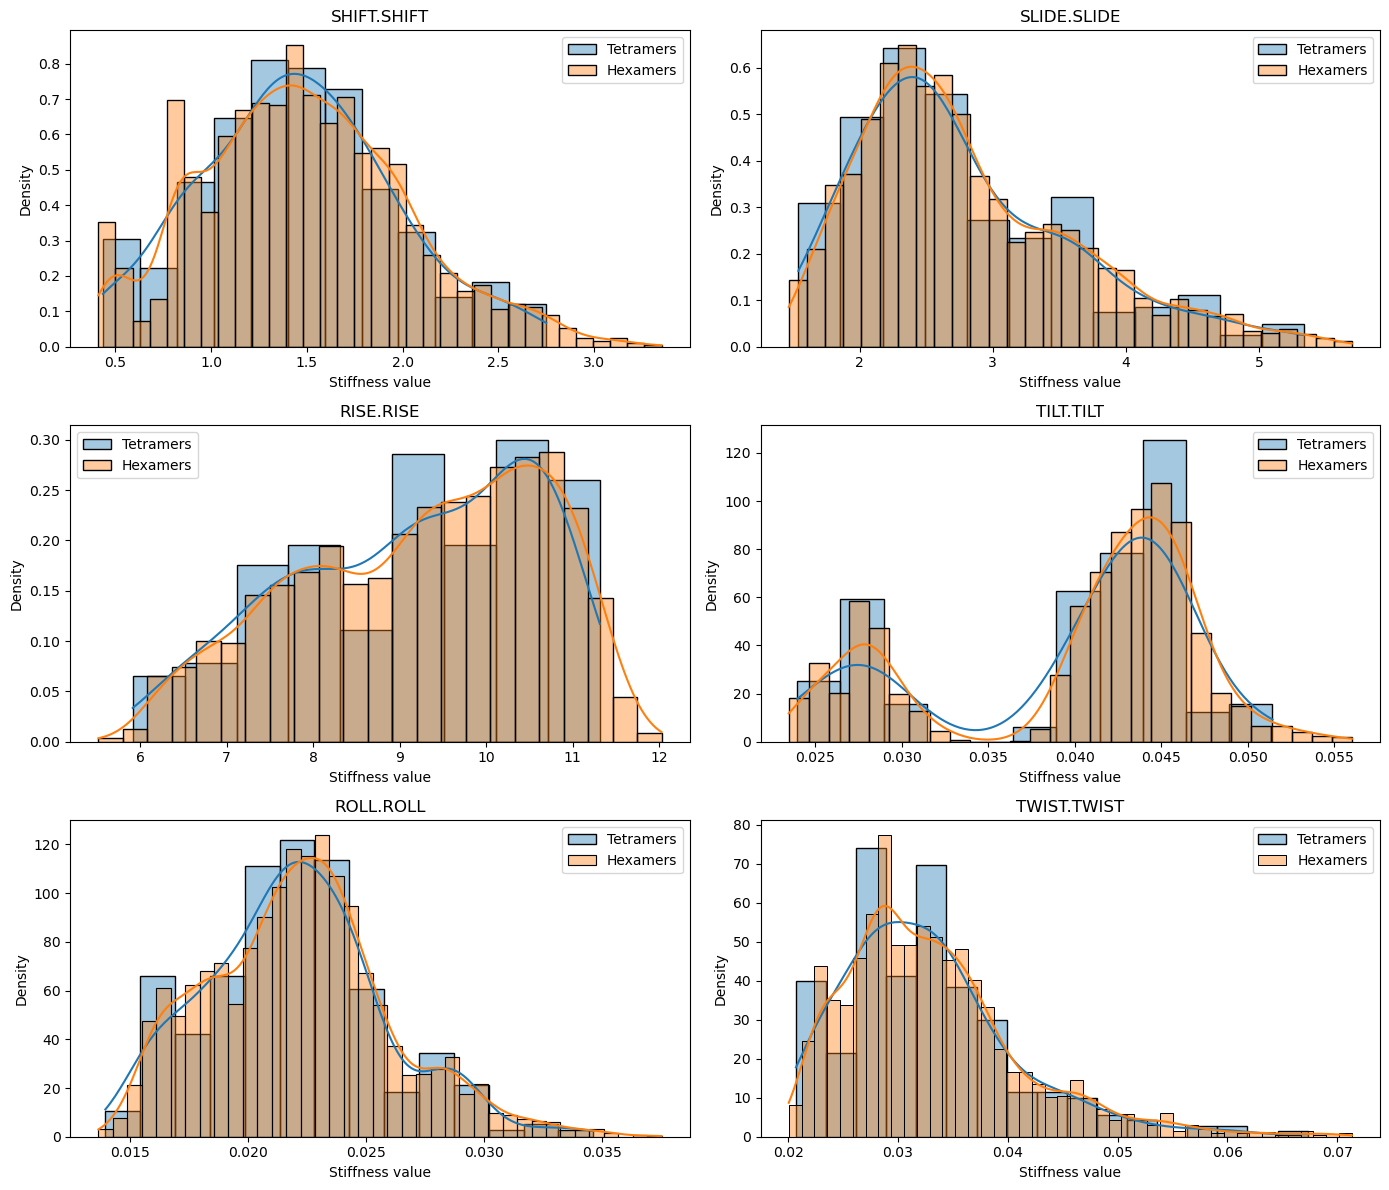

In [81]:
diagonal_features = [
    "SHIFT.SHIFT",
    "SLIDE.SLIDE",
    "RISE.RISE",
    "TILT.TILT",
    "ROLL.ROLL",
    "TWIST.TWIST"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, diagonal_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Stiffness value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
fig.savefig(PLOT_DIR / "fce_diagonal_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The diagonal stiffness elements show different spreads and distribution shapes, indicating that resistance to deformation varies across the six degrees of freedom.

#### 5.2.2. Off-diagonal elements

The 15 unique off-diagonal elements describe coupling between different deformation modes. Since the stiffness matrix is symmetric, only one value from each symmetric pair is analysed.

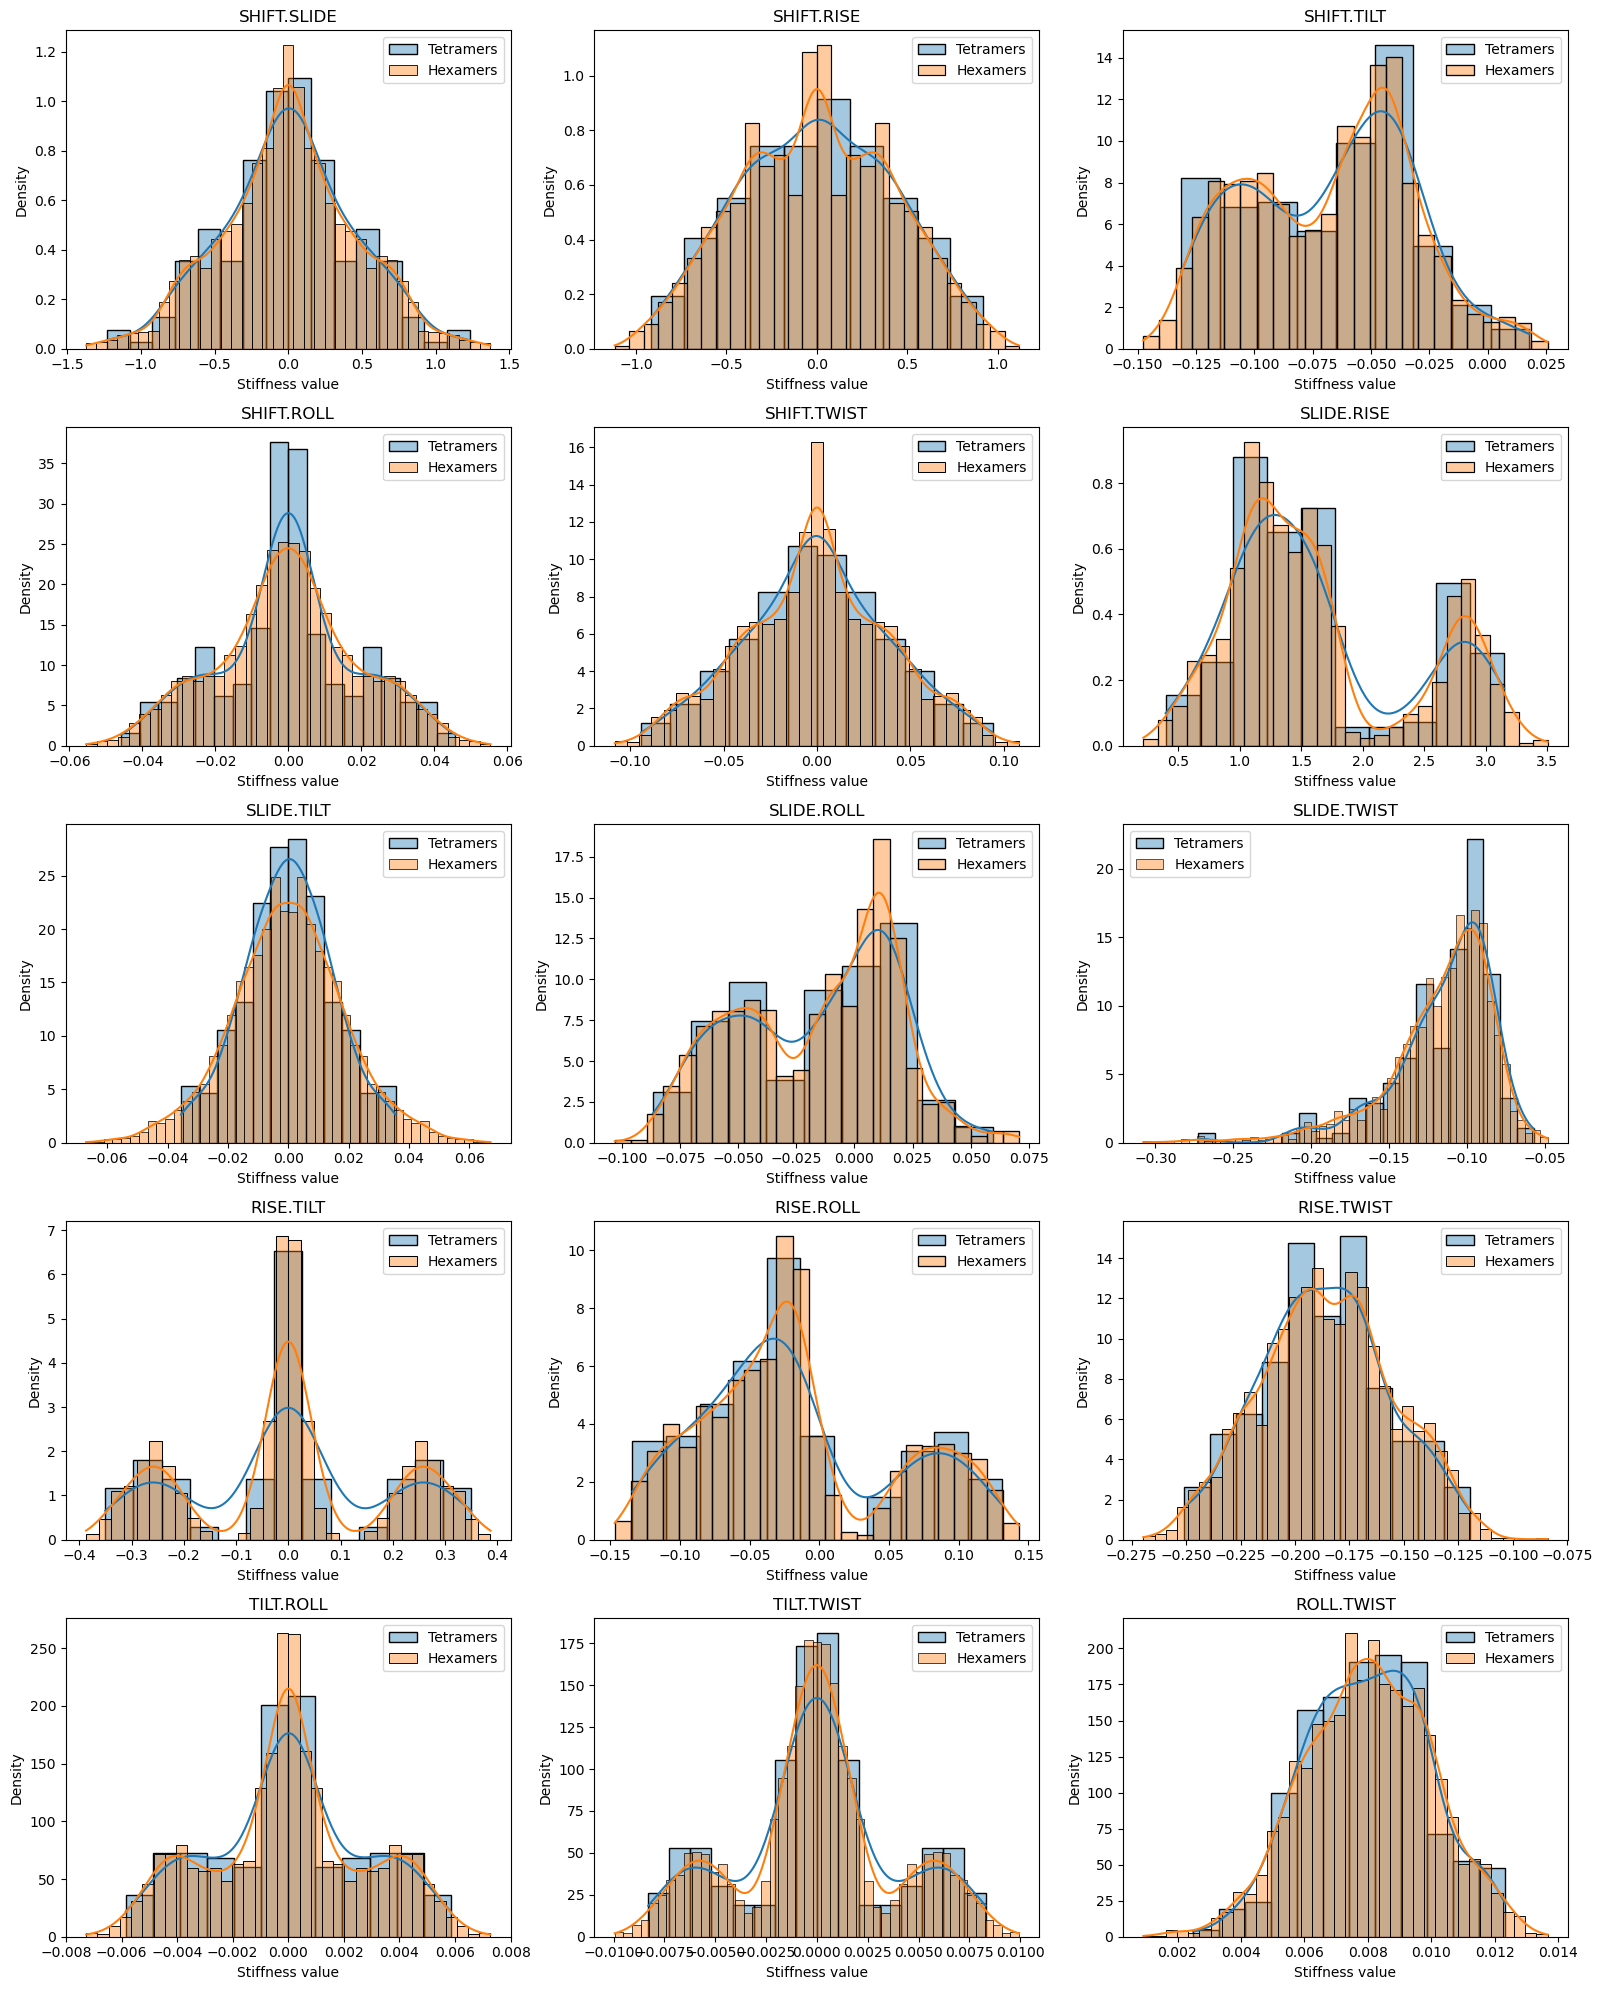

In [82]:
import itertools

degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

off_diagonal_features = [
    f"{a}.{b}"
    for a, b in itertools.combinations(degrees, 2)
]

fig, axes = plt.subplots(5, 3, figsize=(16, 20))

for ax, feature in zip(axes.flat, off_diagonal_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], kde=True, stat="density",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Stiffness value")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
fig.savefig(PLOT_DIR / "fce_off_diagonal_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The off-diagonal elements show different distributions, reflecting variation in the coupling between DNA deformation modes.

### 5.3. Electrostatic descriptors

The five discrete electrostatic descriptors (`e1`–`e5`) are compared between tetramers and hexamers.

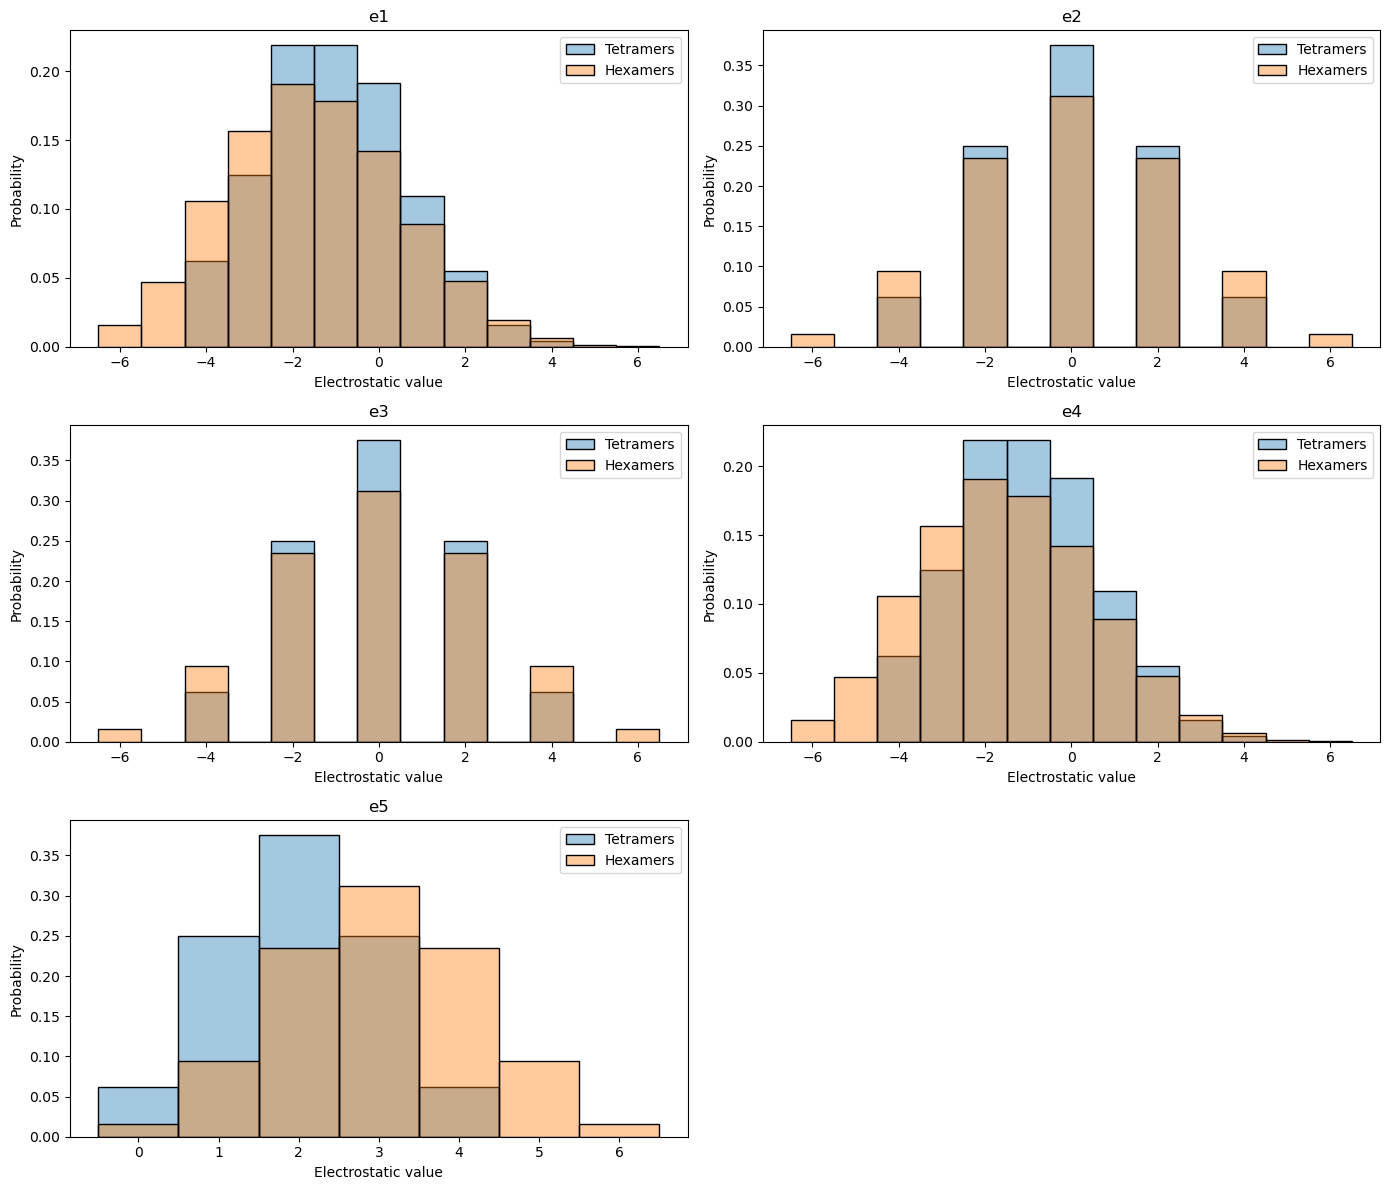

In [83]:
electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, electrostatic_features):
    sns.histplot(input_tetramer[feature], discrete=True, stat="probability",
                 label="Tetramers", ax=ax, alpha=0.4)

    sns.histplot(input_hexamer[feature], discrete=True, stat="probability",
                 label="Hexamers", ax=ax, alpha=0.4)

    ax.set_title(feature)
    ax.set_xlabel("Electrostatic value")
    ax.set_ylabel("Probability")
    ax.legend()

# Remove the unused subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
fig.savefig(PLOT_DIR / "electrostatic_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The electrostatic descriptors have discrete distributions, with different value ranges and frequencies across the five columns.

### 5.4. Ion-related descriptors

We examine the numerical distributions of the six tetramer and ten hexamer ion-related descriptors. Their precise physical interpretation is not documented in the repository.

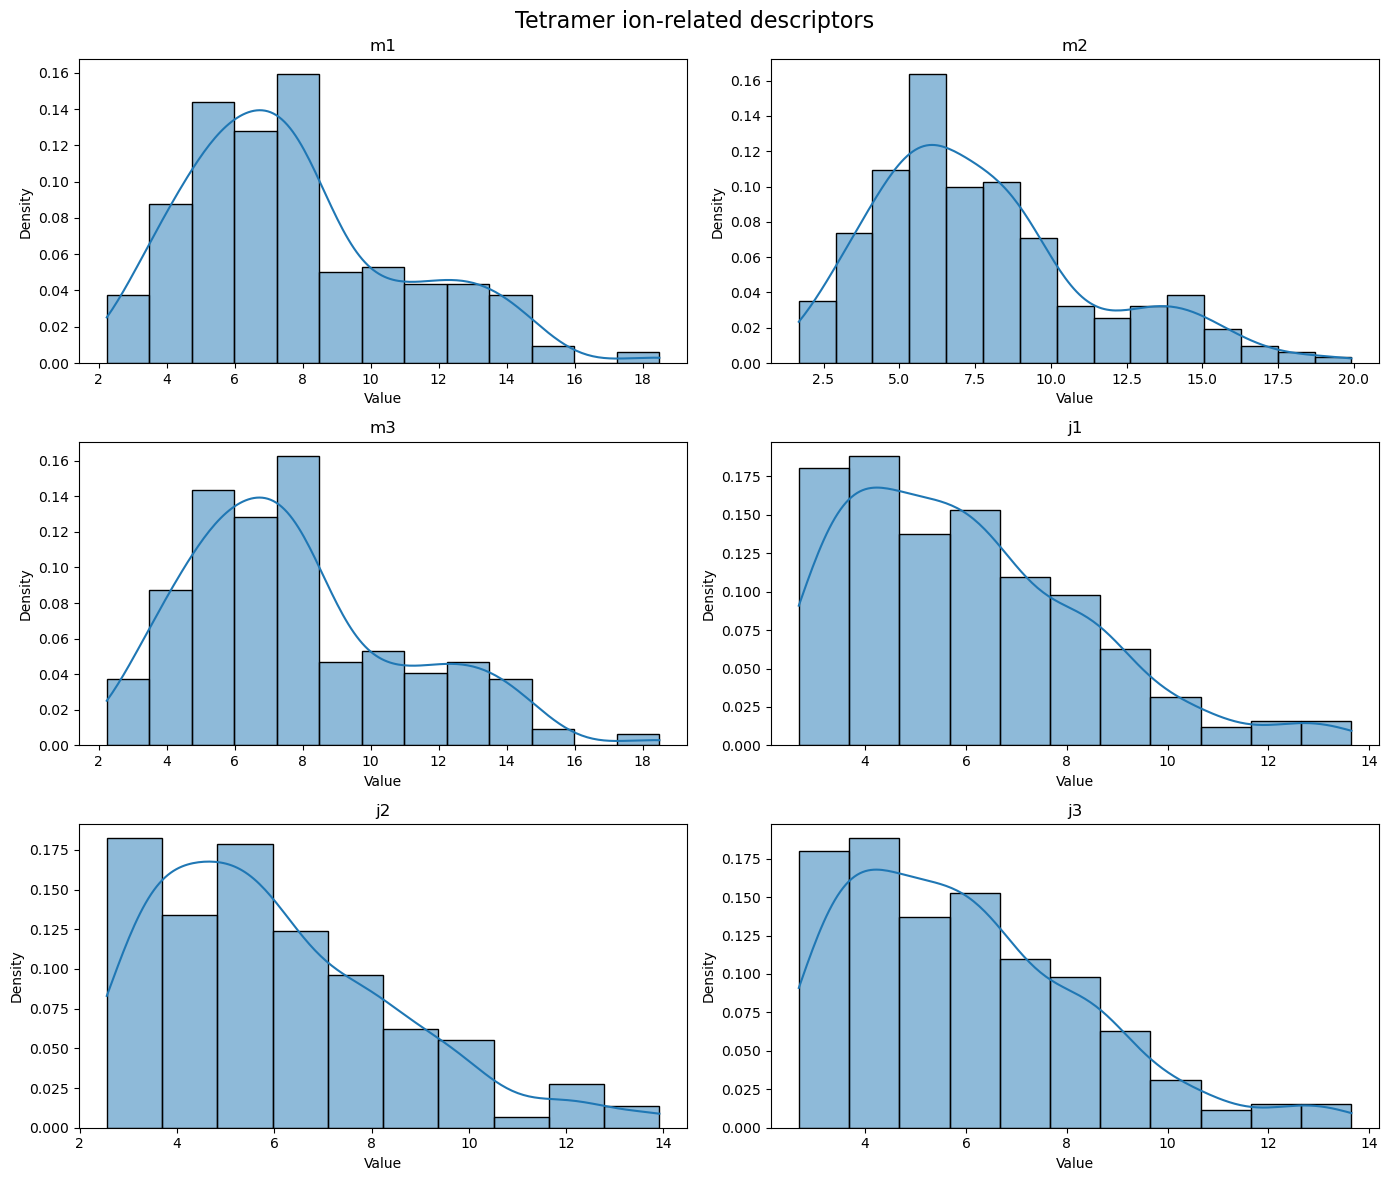

In [84]:
tetramer_ion_features = ["m1", "m2", "m3", "j1", "j2", "j3"]
hexamer_ion_features = ["m0", "m1", "m2", "m3", "m4",
                        "j0", "j1", "j2", "j3", "j4"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, feature in zip(axes.flat, tetramer_ion_features):
    sns.histplot(input_tetramer[feature], kde=True, stat="density", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

plt.suptitle("Tetramer ion-related descriptors", fontsize=16)
plt.tight_layout()
fig.savefig(PLOT_DIR / "tetramer_ion_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

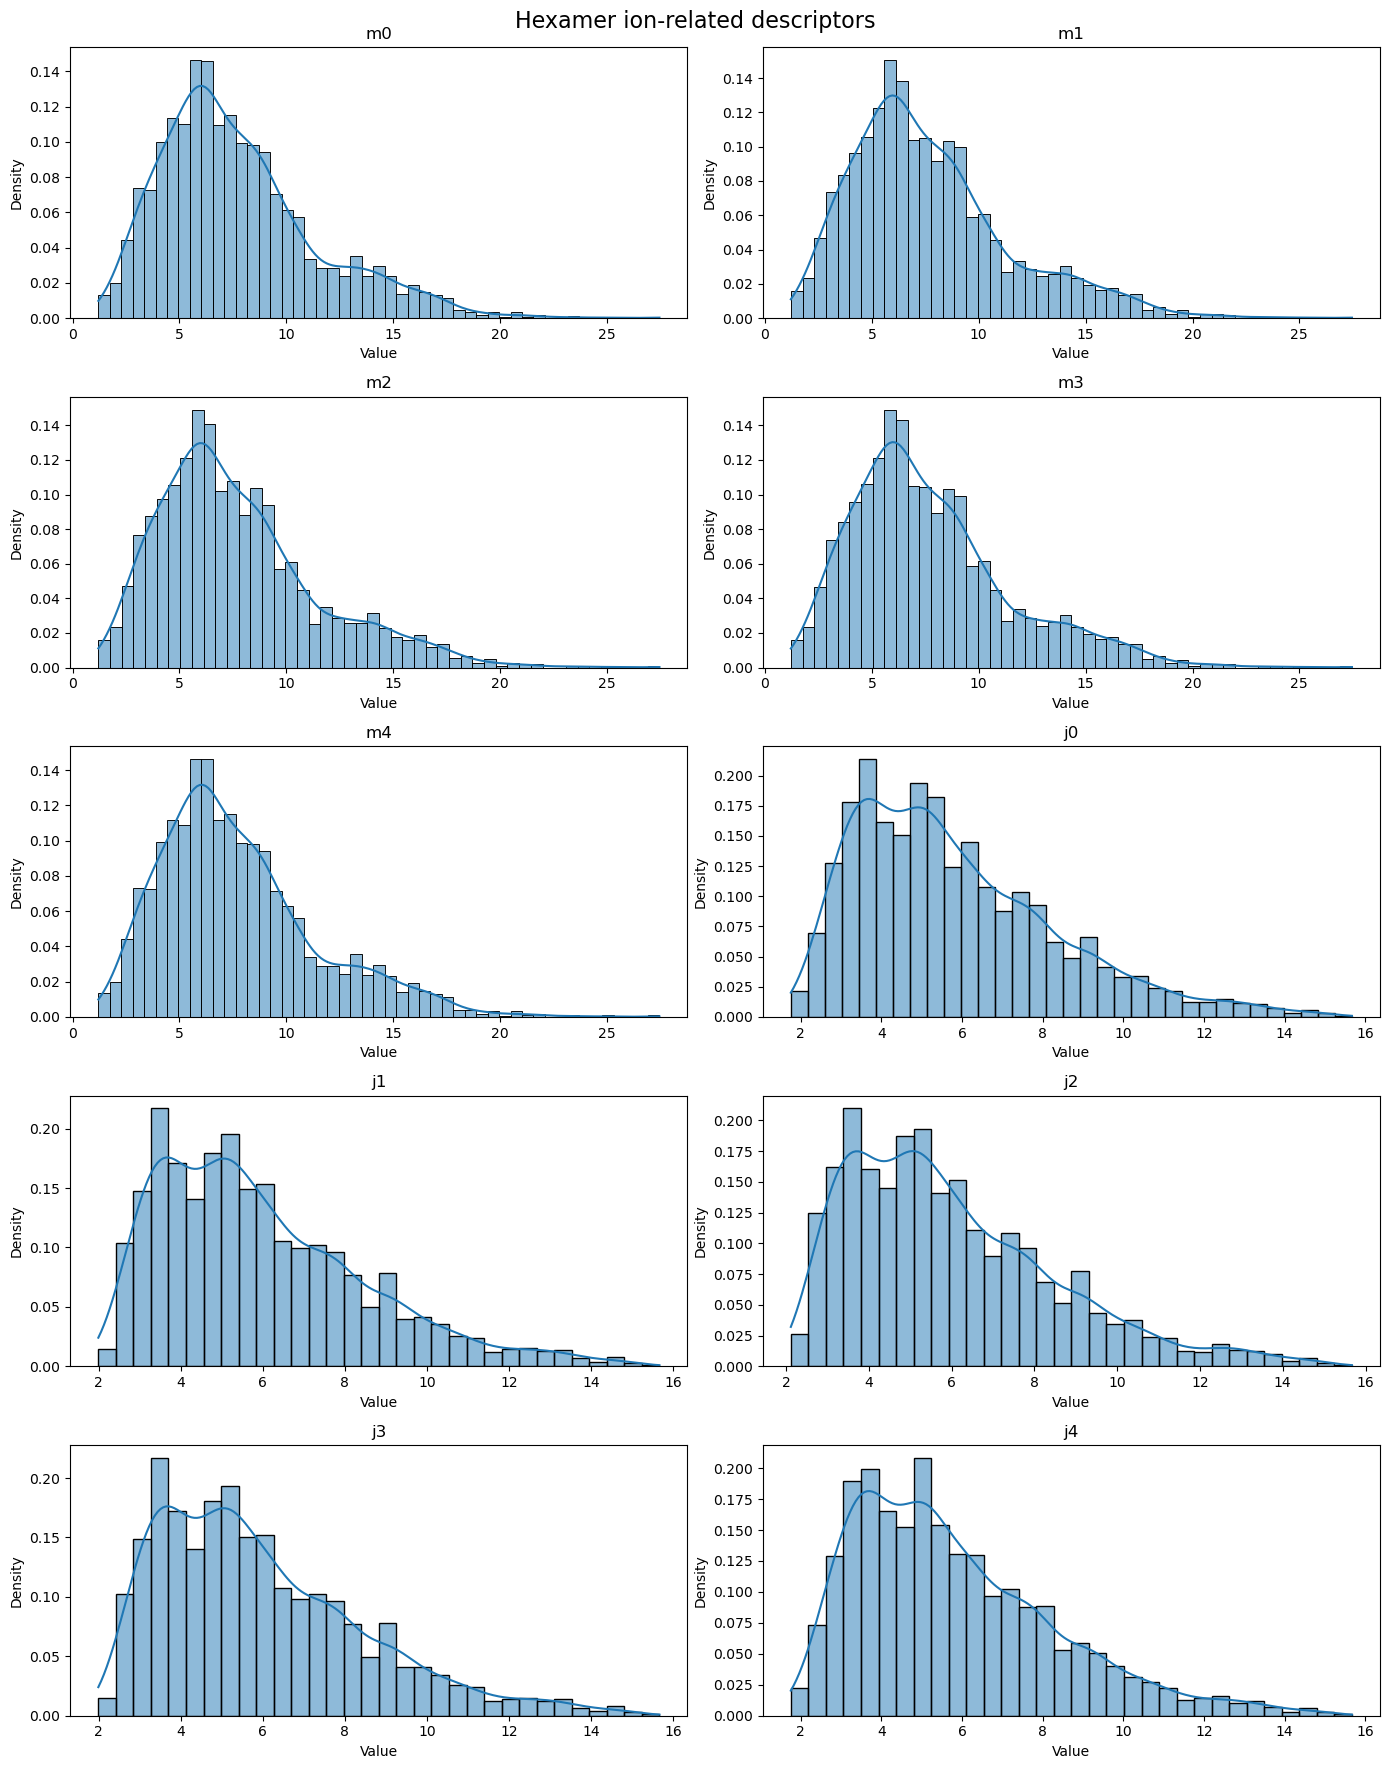

In [85]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for ax, feature in zip(axes.flat, hexamer_ion_features):
    sns.histplot(input_hexamer[feature], kde=True, stat="density", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

plt.suptitle("Hexamer ion-related descriptors", fontsize=16)
plt.tight_layout()
fig.savefig(PLOT_DIR / "hexamer_ion_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The ion-related descriptors are predominantly right-skewed, with most values concentrated at lower ranges and longer upper tails.

## 6. Correlation analysis

Pearson correlation is used to examine linear relationships within each descriptor group. Tetramer and hexamer results are calculated separately.

### 6.1. AVG descriptors

We examine correlations among the six average helical parameters.

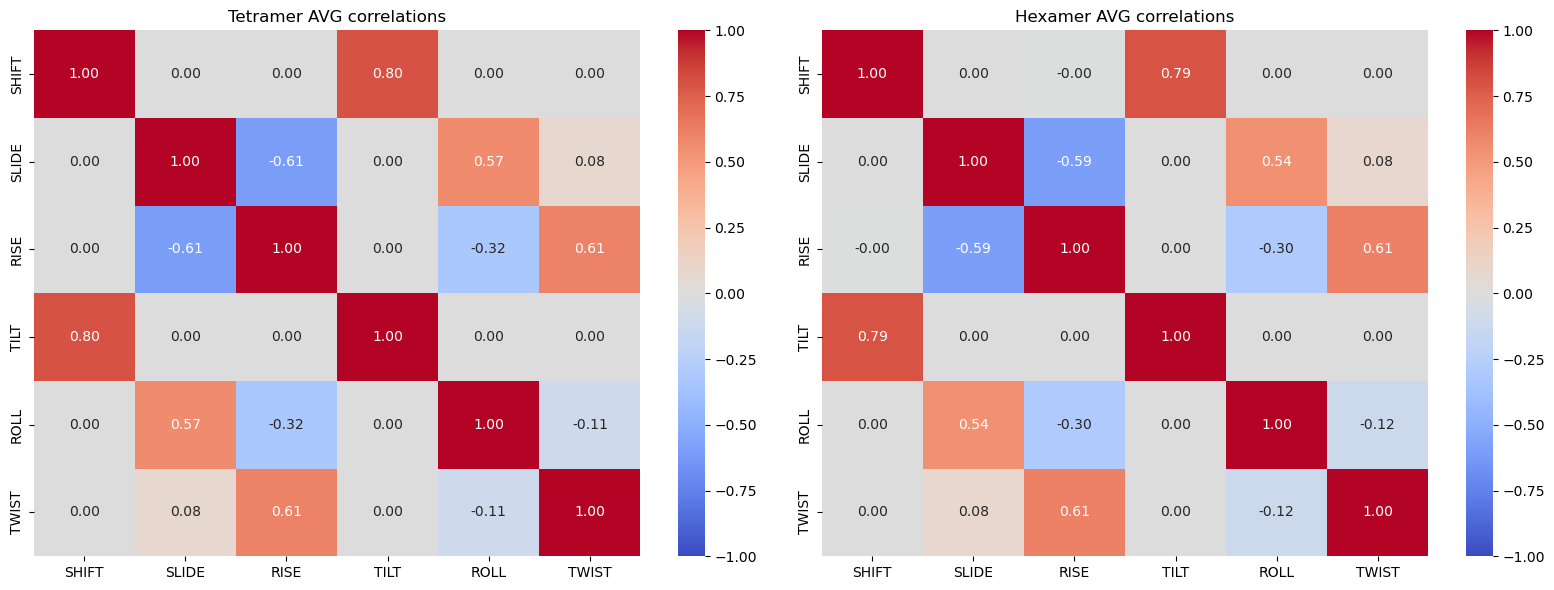

In [86]:
avg_features = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

# Calculate Pearson correlation matrices
corr_avg_tetramer = input_tetramer[avg_features].corr(method="pearson")
corr_avg_hexamer = input_hexamer[avg_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_avg_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer AVG correlations")

sns.heatmap(corr_avg_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer AVG correlations")

plt.tight_layout()
fig.savefig(PLOT_DIR / "avg_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The heatmaps show that some helical parameters are correlated, while others have weaker linear relationships. These patterns are broadly comparable between tetramers and hexamers.

### 6.2. FCE descriptors

We examine correlations among the 21 unique stiffness matrix elements, avoiding duplicated symmetric entries.

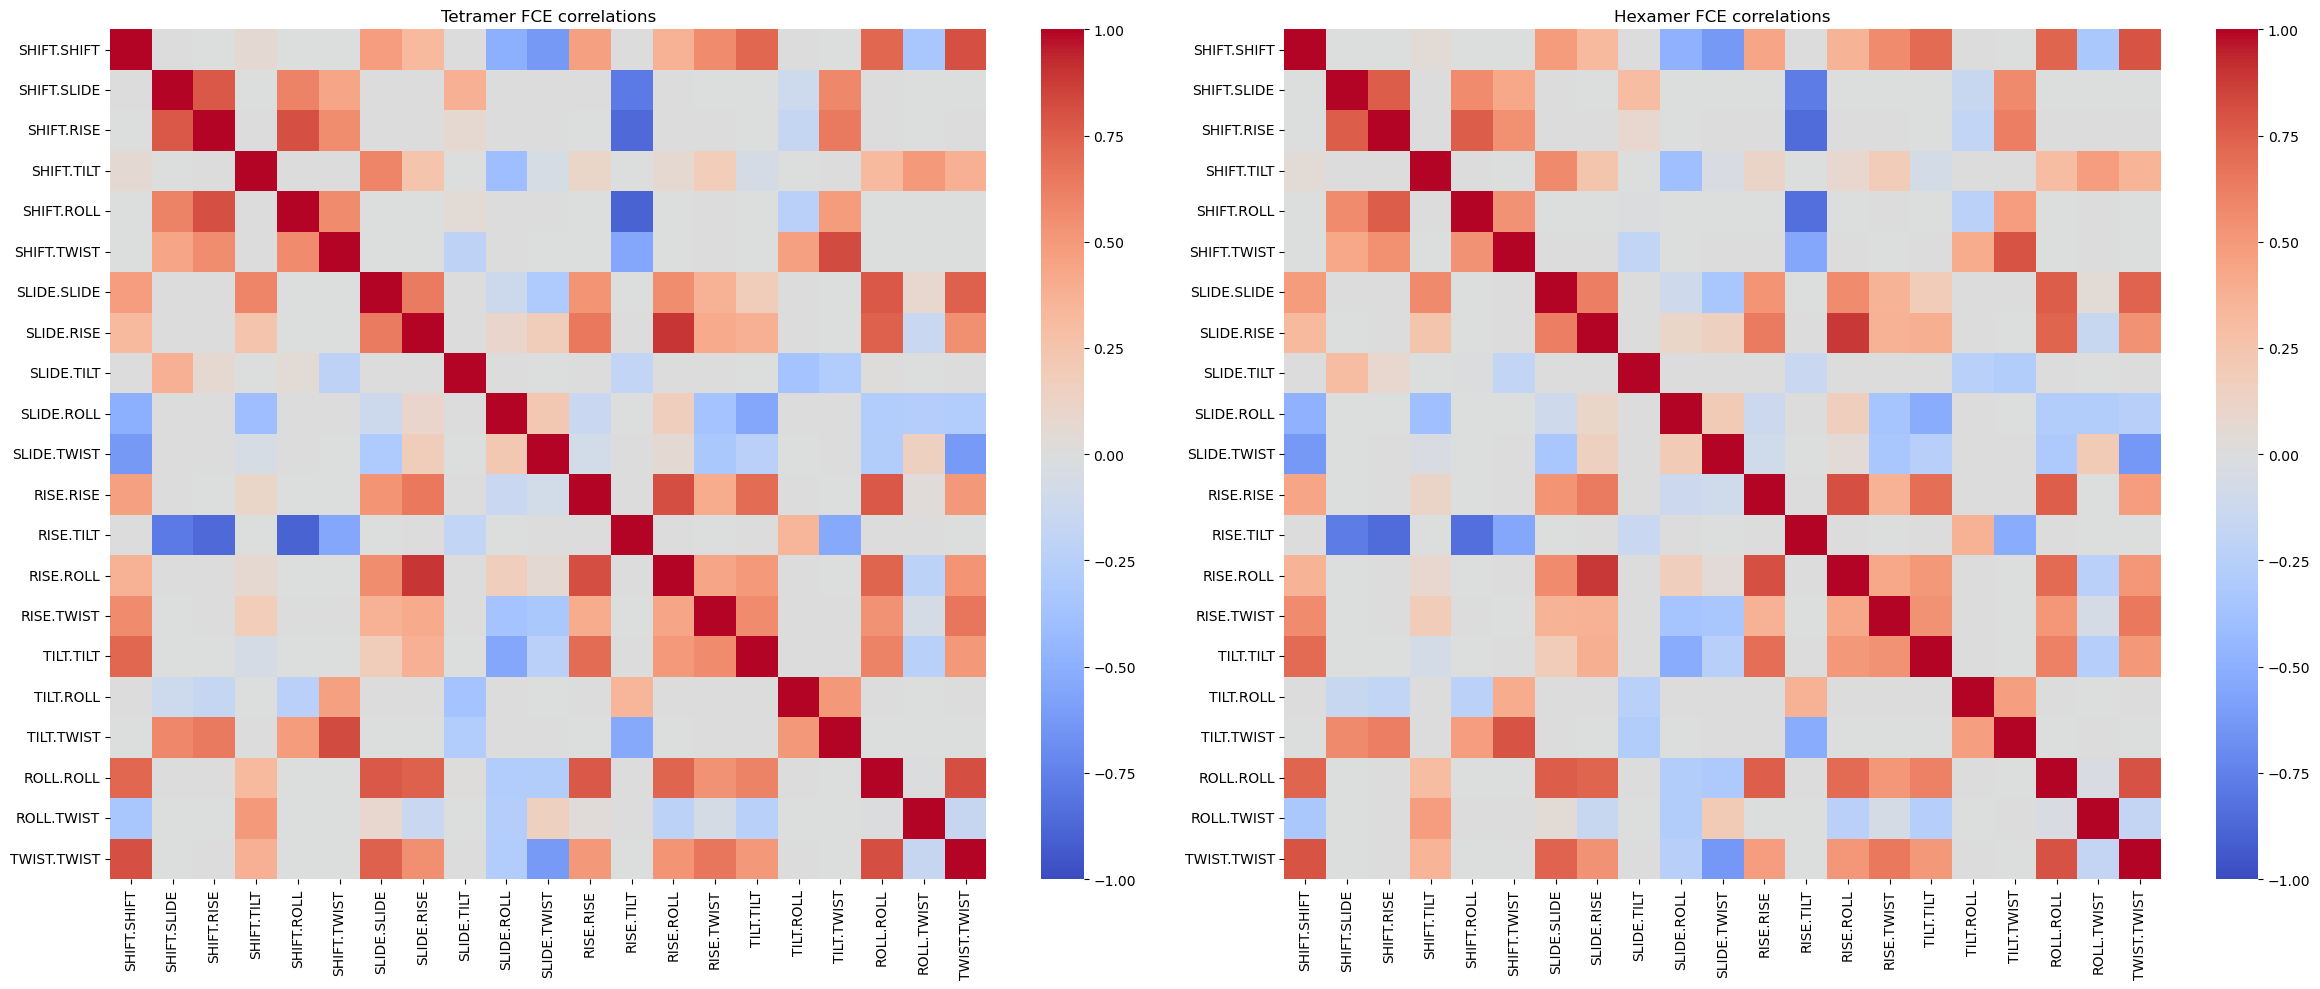

In [87]:
import itertools

degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]

# Generate the 21 unique stiffness matrix elements
fce_features = [
    f"{a}.{b}"
    for i, a in enumerate(degrees)
    for b in degrees[i:]
]

# Calculate Pearson correlation matrices
corr_fce_tetramer = input_tetramer[fce_features].corr(method="pearson")
corr_fce_hexamer = input_hexamer[fce_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(24, 10))

sns.heatmap(corr_fce_tetramer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[0])

axes[0].set_title("Tetramer FCE correlations")

sns.heatmap(corr_fce_hexamer, cmap="coolwarm", vmin=-1, vmax=1,
            center=0, ax=axes[1])

axes[1].set_title("Hexamer FCE correlations")

plt.tight_layout()
fig.savefig(PLOT_DIR / "fce_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The FCE heatmaps show multiple relationships among stiffness components. This indicates that the 21 unique matrix elements should not automatically be treated as statistically independent.

### 6.3. Electrostatic descriptors

We examine correlations among the five electrostatic descriptors.

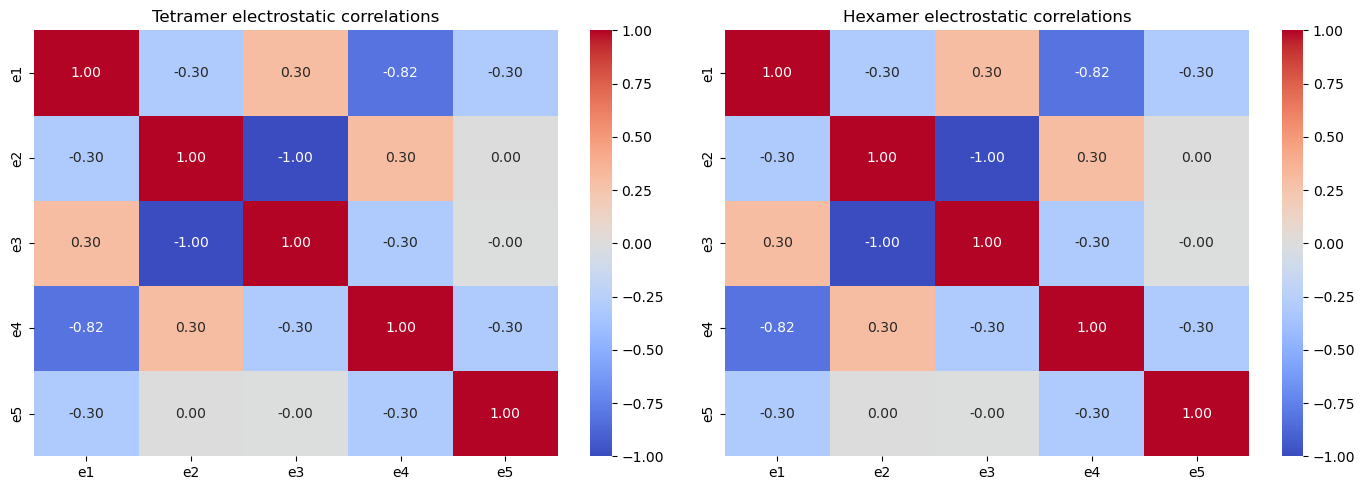

In [88]:
electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]

# Calculate Pearson correlation matrices
corr_elec_tetramer = input_tetramer[electrostatic_features].corr(method="pearson")
corr_elec_hexamer = input_hexamer[electrostatic_features].corr(method="pearson")

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_elec_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer electrostatic correlations")

sns.heatmap(corr_elec_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer electrostatic correlations")

plt.tight_layout()
fig.savefig(PLOT_DIR / "electrostatic_correlation_heatmaps.png",
            dpi=300, bbox_inches="tight")
plt.show()

#### Observations

Some electrostatic descriptors are strongly correlated, indicating that the five columns may contain overlapping linear information.

### 6.4. Ion-related descriptors

We examine correlations among the ion-related descriptors available for tetramers and hexamers.

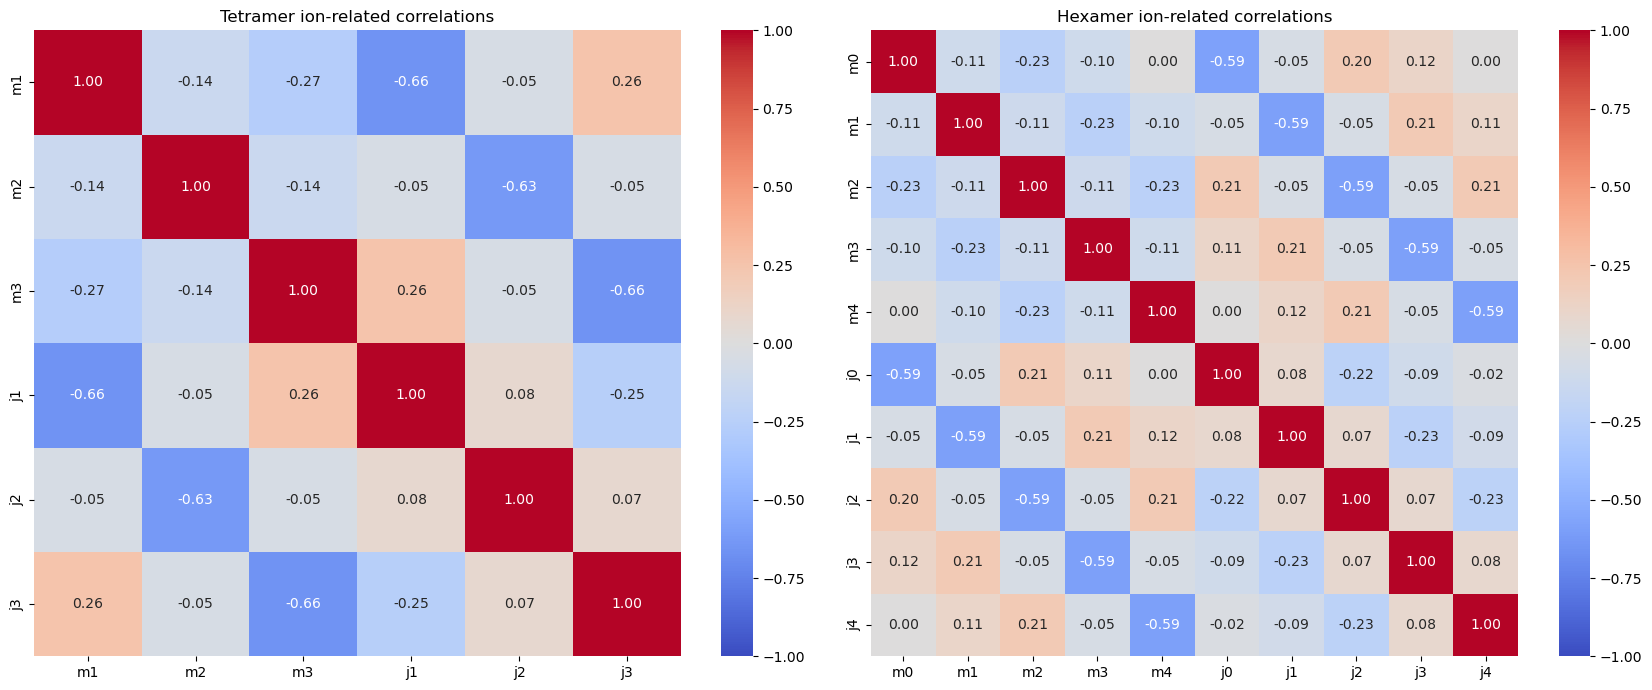

In [89]:
tetramer_ion_features = ["m1", "m2", "m3", "j1", "j2", "j3"]

hexamer_ion_features = [
    "m0", "m1", "m2", "m3", "m4",
    "j0", "j1", "j2", "j3", "j4"
]

# Calculate Pearson correlation matrices
corr_ion_tetramer = input_tetramer[tetramer_ion_features].corr()
corr_ion_hexamer = input_hexamer[hexamer_ion_features].corr()

# Plot correlation heatmaps
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(corr_ion_tetramer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[0])

axes[0].set_title("Tetramer ion-related correlations")

sns.heatmap(corr_ion_hexamer, annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, center=0,
            ax=axes[1])

axes[1].set_title("Hexamer ion-related correlations")

plt.tight_layout()
fig.savefig(PLOT_DIR / "ion_correlation_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

#### Observations

The heatmaps show negative correlations between corresponding `m` and `j` descriptors. Their physical interpretation is not assigned because the repository does not document what these columns represent.

## 7. Feature structure and dimensionality

We assess redundancy in the electrostatic descriptors by counting unique profiles and calculating the matrix rank. The rank indicates the number of linearly independent columns.

In [90]:
electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]

for name, df in {"Tetramer": input_tetramer, "Hexamer": input_hexamer}.items():
    X = df[electrostatic_features]
    print(
        f"{name}: {X.drop_duplicates().shape[0]} unique electrostatic profiles; "
        f"matrix rank = {np.linalg.matrix_rank(X.to_numpy())}"
    )

Tetramer: 35 unique electrostatic profiles; matrix rank = 3
Hexamer: 84 unique electrostatic profiles; matrix rank = 3


The number of unique electrostatic profiles and the matrix rank provide complementary information: the former measures how many distinct descriptor combinations occur, while the latter measures the number of linearly independent descriptor columns. The results should be interpreted separately; a low rank indicates linear dependence among columns.

## 8. HT-SELEX data exploration

We examine the selected HT-SELEX datasets across the 11 transcription factors, focusing on dataset structure, sequencing counts, estimated affinity and standard error.

### 8.1. Dataset overview

We compare dataset sizes and verify sequence length, missing values, duplicated K-mers and column consistency across transcription factors.

In [91]:
for protein, df in selex_data.items():
    print(f"{protein} (cycle {selex_cycles[protein]})")
    print(f"  Dimensions: {df.shape}")
    print(f"  Columns: {df.columns.tolist()}")
    print()

Gata4 (cycle 4)
  Dimensions: (126624, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

Zfp24 (cycle 5)
  Dimensions: (406165, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

arid3 (cycle 6)
  Dimensions: (273249, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

hoxd1 (cycle 3)
  Dimensions: (887634, 7)
  Columns: ['#', 'Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

nkx3 (cycle 6)
  Dimensions: (963575, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

pax3-like (cycle 5)
  Dimensions: (427916, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

six1 (cycle 5)
  Dimensions: (944350, 6)
  Columns: ['Kmer', 'ObservedCount', 'Probability', 'ExpectedCount', 'Affinity', 'SE']

tbx15 (cycle 5)
  Dimensions: (25991, 6)
  Columns: ['Kmer', 'ObservedCount', 'Prob

In [92]:
# Remove the row-index column present only in Hoxd1
selex_data["hoxd1"] = selex_data["hoxd1"].drop(columns="#", errors="ignore")

# Summarise data quality across transcription factors
selex_quality = []
for protein, df in selex_data.items():
    selex_quality.append({
        "Transcription factor": protein,
        "Cycle": selex_cycles[protein],
        "Sequences": len(df),
        "Missing values": int(df.isna().sum().sum()),
        "Duplicated K-mers": int(df["Kmer"].duplicated().sum()),
        "Sequence lengths": sorted(df["Kmer"].str.len().dropna().unique().tolist()),
        "Columns": len(df.columns)
    })

display(pd.DataFrame(selex_quality))

,Transcription factor,Cycle,Sequences,Missing values,Duplicated K-mers,Sequence lengths,Columns
0,Gata4,4,126624,0,0,[10],6
1,Zfp24,5,406165,0,0,[10],6
2,arid3,6,273249,0,0,[10],6
3,hoxd1,3,887634,0,0,[10],6
4,nkx3,6,963575,0,0,[10],6
5,pax3-like,5,427916,0,0,[10],6
6,six1,5,944350,0,0,[10],6
7,tbx15,5,25991,0,0,[10],6
8,telf,5,691492,0,0,[10],6
9,uncxb,5,234129,0,0,[10],6


The 11 datasets contain observed 10-mer sequences and associated sequencing and affinity estimates. Dataset sizes vary substantially, from 25,991 sequences for Tbx15 to 963,575 for Nkx3. The quality summary above should be used to verify missing values, duplicated K-mers, sequence lengths and column consistency after removing the Hoxd1 row-index column.

### 8.2. Observed counts and affinity

We compare observed sequencing counts and estimated affinity across transcription factors using descriptive statistics and boxplots. Counts are displayed on a logarithmic scale because their distributions are strongly right-skewed.

In [93]:
selex_stats = []

for protein, df in selex_data.items():
    for variable in ["ObservedCount", "Affinity"]:
        stats = df[variable].describe()

        selex_stats.append({
            "Transcription factor": protein,
            "Variable": variable,
            "Mean": stats["mean"],
            "Median": stats["50%"],
            "Std": stats["std"],
            "Min": stats["min"],
            "Max": stats["max"]
        })

selex_stats = pd.DataFrame(selex_stats)
display(selex_stats.round(4))

,Transcription factor,Variable,Mean,Median,Std,Min,Max
0,Gata4,ObservedCount,5.4461,1.0000,19.7855,1.0000,925.0000
1,Gata4,Affinity,0.2349,0.2140,0.0831,0.0942,1.0000
2,Zfp24,ObservedCount,24.6974,2.0000,139.5192,1.0000,9031.0000
3,Zfp24,Affinity,0.2733,0.2555,0.0711,0.1417,1.0000
4,arid3,ObservedCount,8.9125,2.0000,65.7976,1.0000,12365.0000
5,arid3,Affinity,0.2777,0.2680,0.0539,0.1595,1.0000
6,hoxd1,ObservedCount,3.8803,3.0000,6.1556,1.0000,520.0000
7,hoxd1,Affinity,0.0172,0.0140,0.0136,0.0010,0.5843
8,nkx3,ObservedCount,8.9979,5.0000,11.3716,1.0000,727.0000
9,nkx3,Affinity,0.3605,0.3554,0.0554,0.1873,1.0000


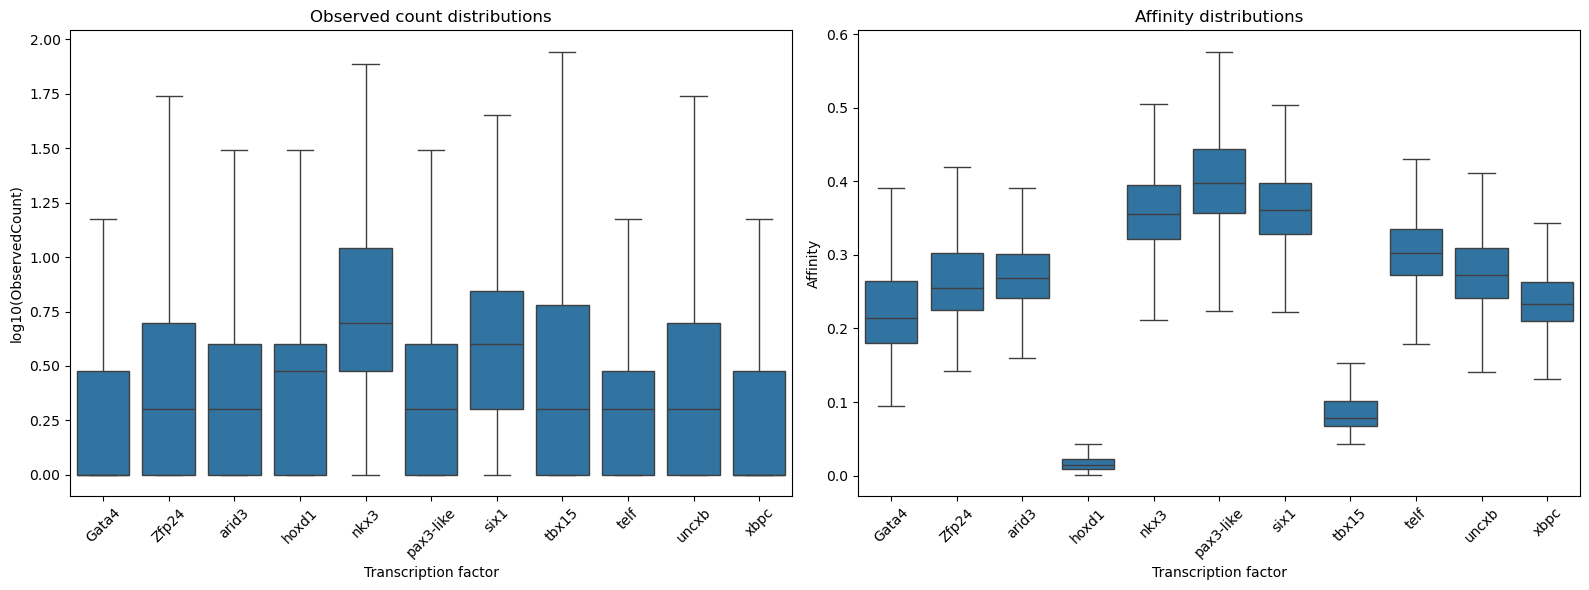

In [94]:
# Combine all datasets into a single DataFrame
selex_combined = pd.concat(
    [
        df.assign(TranscriptionFactor=protein)
        for protein, df in selex_data.items()
    ],
    ignore_index=True
)

# Log-transform observed counts
selex_combined["Log10ObservedCount"] = np.log10(
    selex_combined["ObservedCount"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Observed counts
sns.boxplot(
    data=selex_combined,
    x="TranscriptionFactor",
    y="Log10ObservedCount",
    ax=axes[0],
    showfliers=False
)
axes[0].set_title("Observed count distributions")
axes[0].set_xlabel("Transcription factor")
axes[0].set_ylabel("log10(ObservedCount)")
axes[0].tick_params(axis="x", rotation=45)

# Affinity
sns.boxplot(
    data=selex_combined,
    x="TranscriptionFactor",
    y="Affinity",
    ax=axes[1],
    showfliers=False
)
axes[1].set_title("Affinity distributions")
axes[1].set_xlabel("Transcription factor")
axes[1].set_ylabel("Affinity")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()

fig.savefig(PLOT_DIR / "selex_count_affinity_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Observed counts are strongly right-skewed, and their distributions differ across transcription factors. Estimated affinity distributions also vary between datasets. These between-factor differences should be considered when comparing or modelling the datasets.

### 8.3. Count–affinity association

Spearman correlations are calculated separately for each transcription factor to describe the monotonic association between observed counts and estimated affinity.

,Transcription factor,Spearman correlation
0,Gata4,0.7257
1,Zfp24,0.6178
2,arid3,0.6398
3,hoxd1,0.7922
4,nkx3,0.6358
5,pax3-like,0.5216
6,six1,0.5071
7,tbx15,0.8197
8,telf,0.5996
9,uncxb,0.5899


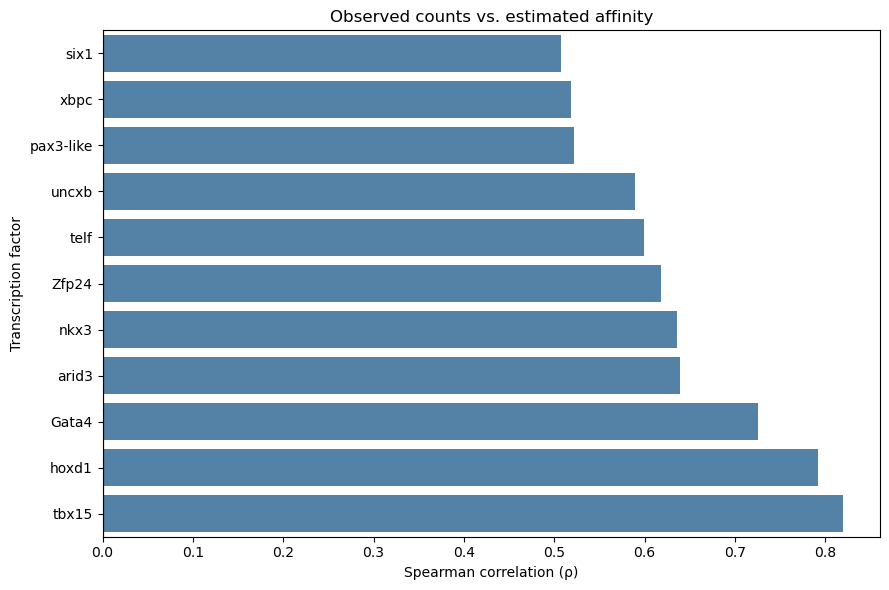

In [95]:
selex_correlations = []

for protein, df in selex_data.items():
    correlation = df["ObservedCount"].corr(
        df["Affinity"],
        method="spearman"
    )

    selex_correlations.append({
        "Transcription factor": protein,
        "Spearman correlation": correlation
    })

selex_correlations = pd.DataFrame(selex_correlations)
display(selex_correlations.round(4))

# Plot Spearman correlations across transcription factors
fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=selex_correlations.sort_values("Spearman correlation"),
    x="Spearman correlation",
    y="Transcription factor",
    color="steelblue",
    ax=ax
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman correlation (ρ)")
ax.set_ylabel("Transcription factor")
ax.set_title("Observed counts vs. estimated affinity")

plt.tight_layout()
fig.savefig(PLOT_DIR / "selex_spearman_correlations.png",
            dpi=300, bbox_inches="tight")
plt.show()

### 8.4. Standard error

We summarise the standard error (`SE`) across transcription factors to describe its scale and variability.

In [96]:
se_stats = []

for protein, df in selex_data.items():
    stats = df["SE"].describe()

    se_stats.append({
        "Transcription factor": protein,
        "Mean SE": stats["mean"],
        "Median SE": stats["50%"],
        "Std SE": stats["std"],
        "Min SE": stats["min"],
        "Max SE": stats["max"]
    })

se_stats = pd.DataFrame(se_stats)
display(se_stats.round(5))

,Transcription factor,Mean SE,Median SE,Std SE,Min SE,Max SE
0,Gata4,0.22749,0.22773,0.06765,0.03788,0.59686
1,Zfp24,0.24668,0.25888,0.10488,0.00788,0.62348
2,arid3,0.26943,0.28284,0.09963,0.00838,0.60341
3,hoxd1,0.00921,0.00838,0.00426,0.00102,0.06250
4,nkx3,0.23664,0.21709,0.09864,0.04503,0.70351
5,pax3-like,0.40808,0.42279,0.14462,0.01083,0.91480
6,six1,0.27647,0.25974,0.10559,0.03905,0.77868
7,tbx15,0.07469,0.08005,0.02898,0.00175,0.15491
8,telf,0.31135,0.31428,0.09105,0.00948,0.63736
9,uncxb,0.26202,0.27207,0.11069,0.00777,0.68675


Spearman correlation analysis revealed positive associations between observed sequencing counts and estimated affinity across all 11 transcription factors (ρ = 0.51–0.82). Tbx15 and Hoxd1 showed the strongest associations, whereas Six1, Xbpc and Pax3-like showed comparatively weaker correlations.

These results indicate that the relationship between sequencing abundance and estimated affinity varies across transcription factors. However, since affinity is derived from sequencing enrichment, these associations are partly expected and should not be interpreted as independent evidence of binding strength.
The majority of transcription factors show median SE values between approximately 0.20 and 0.30. Pax3-like exhibits higher uncertainty (median SE = 0.423), whereas Hoxd1 and Tbx15 show considerably lower values. These differences should be interpreted in the context of their affinity and observed count distributions, since SE is mathematically related to both variables.

## 9. Principal Component Analysis (PCA)

PCA is applied separately to the tetramer and hexamer AVG descriptors. Each dataset is standardised before fitting PCA. The same sequence of analyses is used for both: explained variance, scores, loadings and a biplot.

### 9.1. PCA of tetramer AVG descriptors

We examine the variance explained by the six AVG descriptors and visualise the tetramers in the PC1–PC2 space.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.3550,0.3550
1,PC2,0.2998,0.6549
2,PC3,0.2034,0.8583
3,PC4,0.0954,0.9537
4,PC5,0.0335,0.9873
5,PC6,0.0127,1.0000


,Variance threshold,Number of components
0,80%,3
1,90%,4
2,95%,4


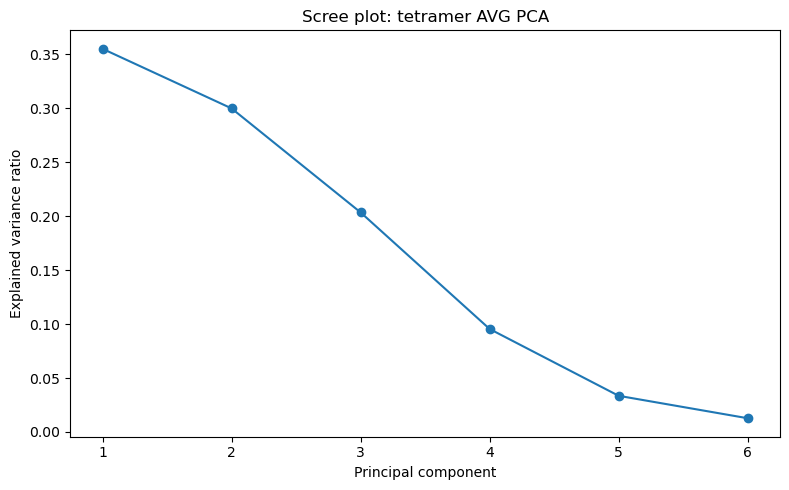

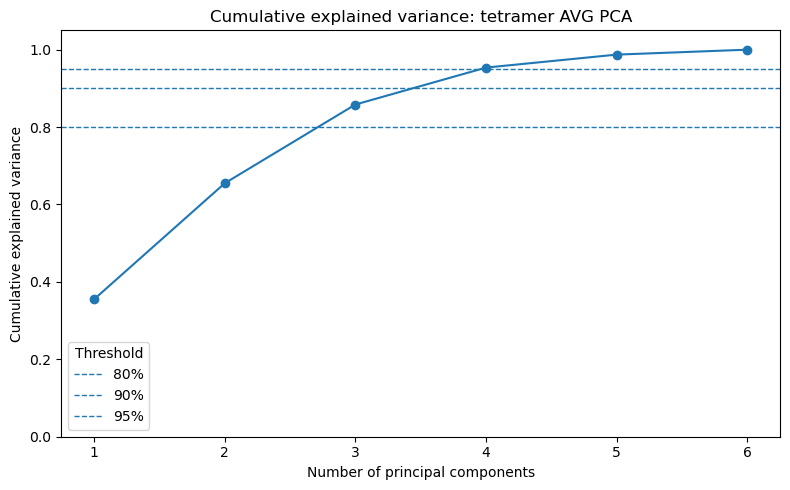

In [97]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

tetramer_avg_features = [
    "SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"
]
tetramer_avg = input_tetramer[tetramer_avg_features]

# Standardise the features before PCA
tetramer_avg_scaled = StandardScaler().fit_transform(tetramer_avg)

# Fit PCA and summarise explained variance
pca_tetramer_avg = PCA()
pca_tetramer_avg.fit(tetramer_avg_scaled)

cumulative_variance = np.cumsum(pca_tetramer_avg.explained_variance_ratio_)
pca_variance = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(tetramer_avg_features) + 1)
    ],
    "Explained variance ratio": pca_tetramer_avg.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance
})
display(pca_variance.round(4))

# Count the components required to reach each variance threshold
variance_thresholds = [0.80, 0.90, 0.95]
components_required = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds],
    "Number of components": [
        np.searchsorted(cumulative_variance, threshold) + 1
        for threshold in variance_thresholds
    ]
})
display(components_required)

# Save PCA plots in the existing EDA plots directory
pca_plot_dir = PLOT_DIR
components = np.arange(1, len(tetramer_avg_features) + 1)

# Scree plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components,
    pca_tetramer_avg.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: tetramer AVG PCA")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components)
fig.tight_layout()
fig.savefig(pca_plot_dir / "pca_tetramer_avg_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components, cumulative_variance, marker="o")
for threshold in variance_thresholds:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: tetramer AVG PCA")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(pca_plot_dir / "pca_tetramer_avg_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()

#### Explained variance interpretation

The PCA indicates that the six tetramer AVG descriptors can be represented by three principal components, which together explain approximately 85.8% of the total variance. Four components are sufficient to explain more than 95%.

This suggests that the descriptors share some information and that the dimensionality of the AVG feature space may be lower than the original number of variables.

#### Scores plot

Each point represents one of the 256 tetramers in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in their AVG descriptors.

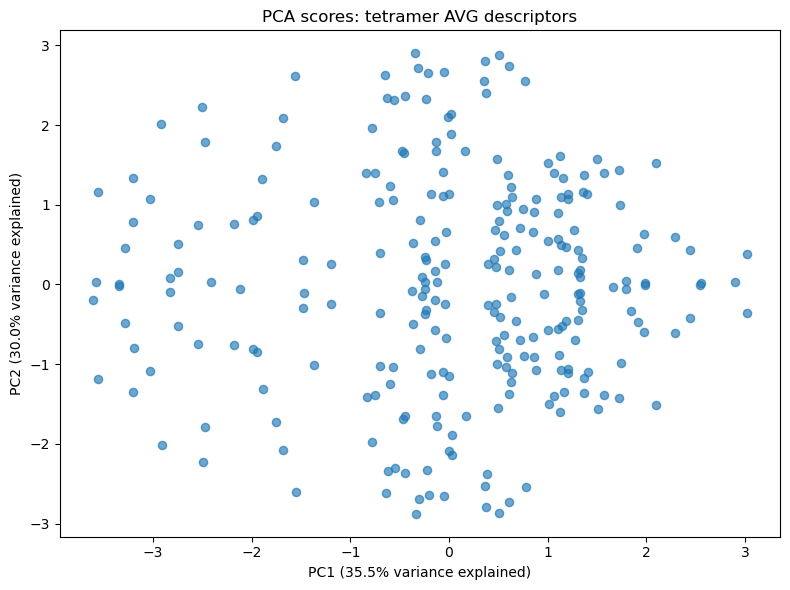

In [98]:
# Project the standardised AVG descriptors onto the fitted principal components
scores_avg_tetra = pca_tetramer_avg.transform(tetramer_avg_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_avg_tetra[:, 0],
    scores_avg_tetra[:, 1],
    s=35,
    alpha=0.65
)
ax.set_title("PCA scores: tetramer AVG descriptors")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_avg.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_avg.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_avg_scores.png", dpi=300, bbox_inches="tight")
plt.show()

#### Loadings

PCA loadings show the direction and strength of the relationship between each original AVG descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5,PC6
SHIFT,-0.001,0.950,-0.005,-0.000,0.318,-0.000
SLIDE,-0.792,0.004,0.502,-0.316,-0.000,0.159
RISE,0.888,0.005,0.314,0.295,-0.001,0.175
TILT,-0.002,0.950,-0.008,-0.001,-0.318,-0.000
ROLL,-0.695,0.004,0.419,0.585,-0.000,-0.052
TWIST,0.491,0.008,0.836,-0.214,-0.001,-0.135


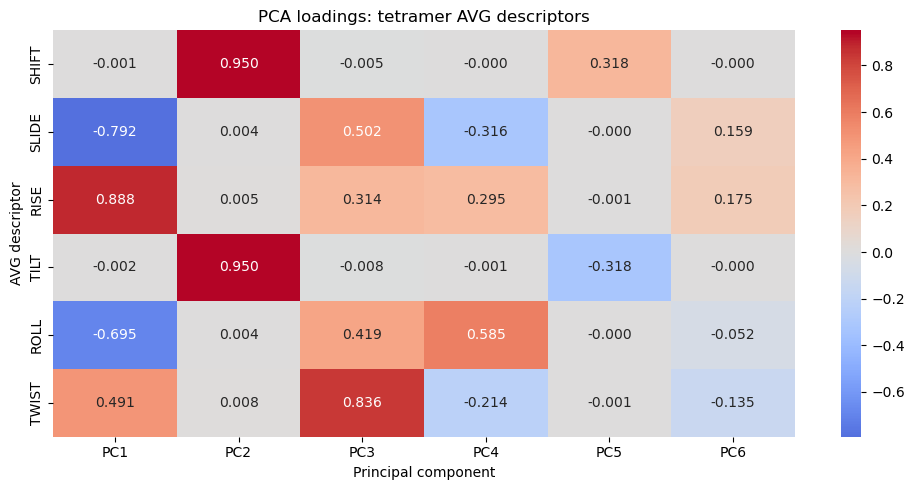

In [99]:
# Calculate loadings from the existing fitted PCA model
pca_loadings_avg = pd.DataFrame(
    pca_tetramer_avg.components_.T
    * np.sqrt(pca_tetramer_avg.explained_variance_),
    index=tetramer_avg_features,
    columns=[f"PC{i}" for i in range(1, len(tetramer_avg_features) + 1)]
)
display(pca_loadings_avg.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    pca_loadings_avg,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: tetramer AVG descriptors")
ax.set_xlabel("Principal component")
ax.set_ylabel("AVG descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_avg_loadings.png", dpi=300, bbox_inches="tight")
plt.show()

#### Biplot

The biplot overlays the tetramer scores with vectors for the six AVG descriptors. For display, all loading vectors are multiplied by one common scale factor so the longest arrow fits within 80% of the score range; this changes arrow lengths for visualisation, not their directions or relative lengths.

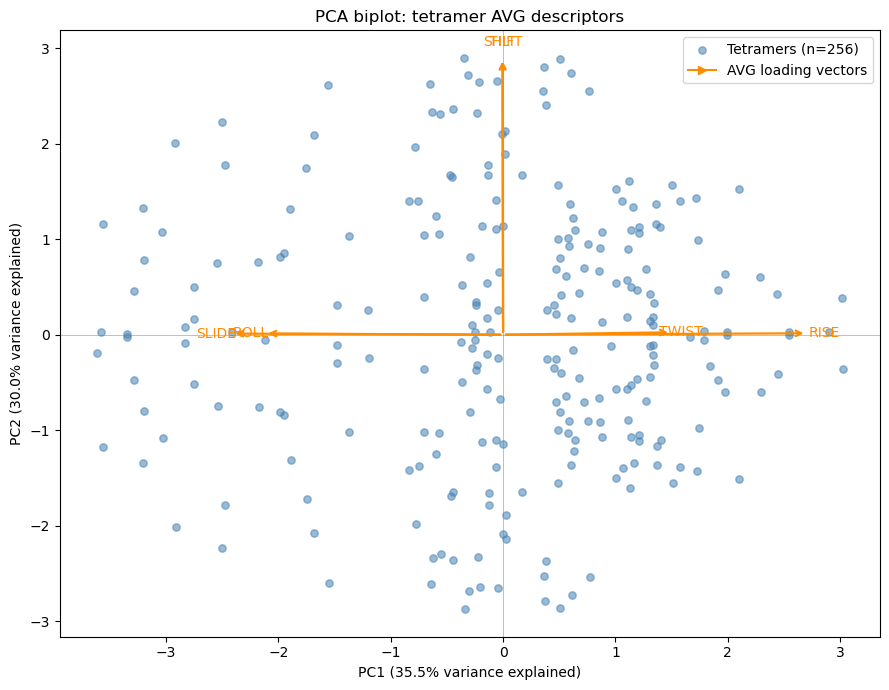

In [100]:
# Use the existing PCA scores and loading matrix
scores_pc12 = scores_avg_tetra[:, :2]
loading_coordinates = pca_loadings_avg[["PC1", "PC2"]].to_numpy()

# Apply one common scale factor so the longest arrow fits the score range
score_extent = np.abs(scores_pc12).max()
loading_extent = np.abs(loading_coordinates).max()
arrow_scale = 0.8 * score_extent / loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    scores_pc12[:, 0],
    scores_pc12[:, 1],
    s=28,
    alpha=0.55,
    color="steelblue",
    label=f"Tetramers (n={len(scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    tetramer_avg_features, loading_coordinates
):
    end_x = loading_x * arrow_scale
    end_y = loading_y * arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="AVG loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: tetramer AVG descriptors")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_avg.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_avg.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_avg_biplot.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.2. PCA of hexamer AVG descriptors

We repeat the same PCA analysis for the 4,096 hexamers, using the six corresponding AVG descriptors.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.3502,0.3502
1,PC2,0.2988,0.6490
2,PC3,0.2027,0.8517
3,PC4,0.1004,0.9521
4,PC5,0.0345,0.9866
5,PC6,0.0134,1.0000


,Variance threshold,Number of components
0,80%,3
1,90%,4
2,95%,4


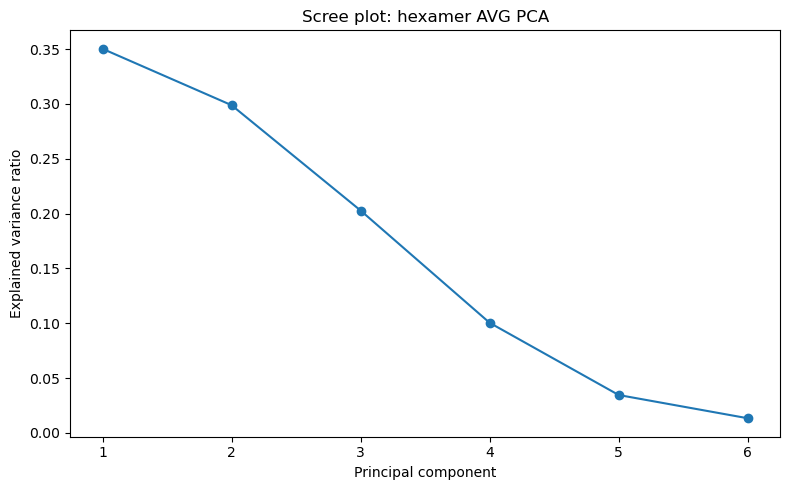

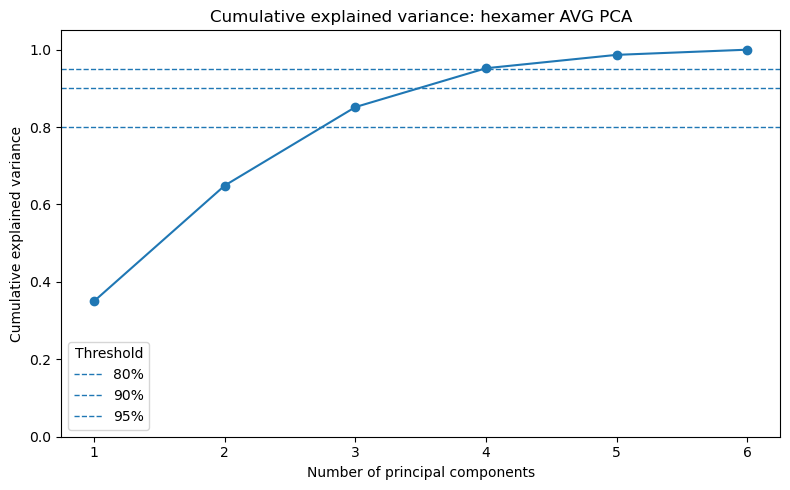

In [101]:
hexamer_avg_features = [
    "SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"
]
hexamer_avg = input_hexamer[hexamer_avg_features]

# Standardise the hexamer AVG features before PCA
hexamer_avg_scaled = StandardScaler().fit_transform(hexamer_avg)

# Fit PCA and summarise explained variance
pca_hexamer_avg = PCA()
pca_hexamer_avg.fit(hexamer_avg_scaled)

cumulative_variance_hexa = np.cumsum(pca_hexamer_avg.explained_variance_ratio_)
pca_variance_hexa = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(hexamer_avg_features) + 1)
    ],
    "Explained variance ratio": pca_hexamer_avg.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_hexa
})
display(pca_variance_hexa.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_hexa = [0.80, 0.90, 0.95]
components_required_hexa = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_hexa],
    "Number of components": [
        np.searchsorted(cumulative_variance_hexa, threshold) + 1
        for threshold in variance_thresholds_hexa
    ]
})
display(components_required_hexa)

# Scree plot
components_hexa = np.arange(1, len(hexamer_avg_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_hexa,
    pca_hexamer_avg.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: hexamer AVG PCA")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_hexa)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_avg_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_hexa, cumulative_variance_hexa, marker="o")
for threshold in variance_thresholds_hexa:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: hexamer AVG PCA")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_hexa)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_avg_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one of the 4,096 hexamers in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in their AVG descriptors.

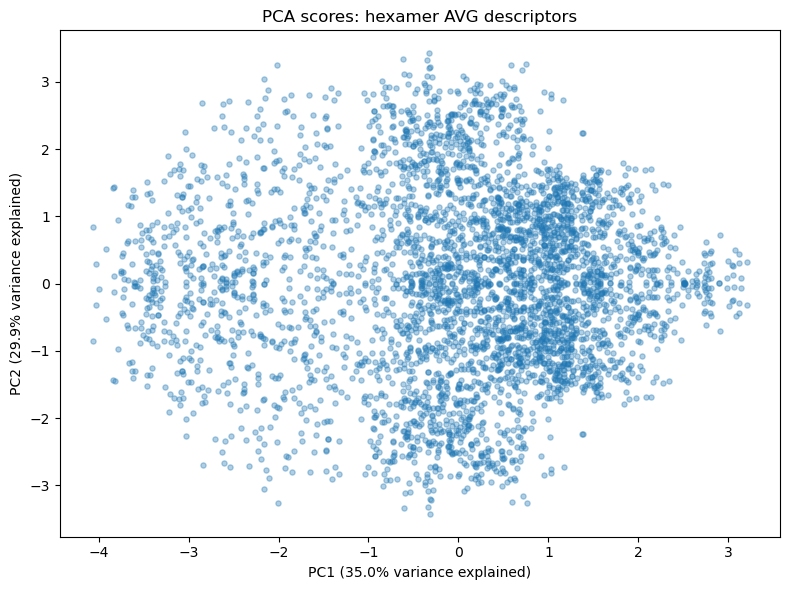

In [102]:
# Project the standardised hexamer AVG descriptors onto the fitted principal components
scores_avg_hexa = pca_hexamer_avg.transform(hexamer_avg_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_avg_hexa[:, 0],
    scores_avg_hexa[:, 1],
    s=14,
    alpha=0.35
)
ax.set_title("PCA scores: hexamer AVG descriptors")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_avg.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_avg.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_avg_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

The loading matrix shows the direction and strength of the relationship between each hexamer AVG descriptor and each principal component.

,PC1,PC2,PC3,PC4,PC5,PC6
SHIFT,-0.002,0.947,-0.001,-0.000,-0.322,-0.000
SLIDE,-0.775,-0.000,0.521,-0.321,-0.000,0.160
RISE,0.884,0.002,0.306,0.304,-0.000,0.178
TILT,-0.002,0.947,-0.001,0.000,0.322,0.000
ROLL,-0.679,-0.000,0.420,0.600,-0.000,-0.055
TWIST,0.508,0.002,0.822,-0.217,0.000,-0.140


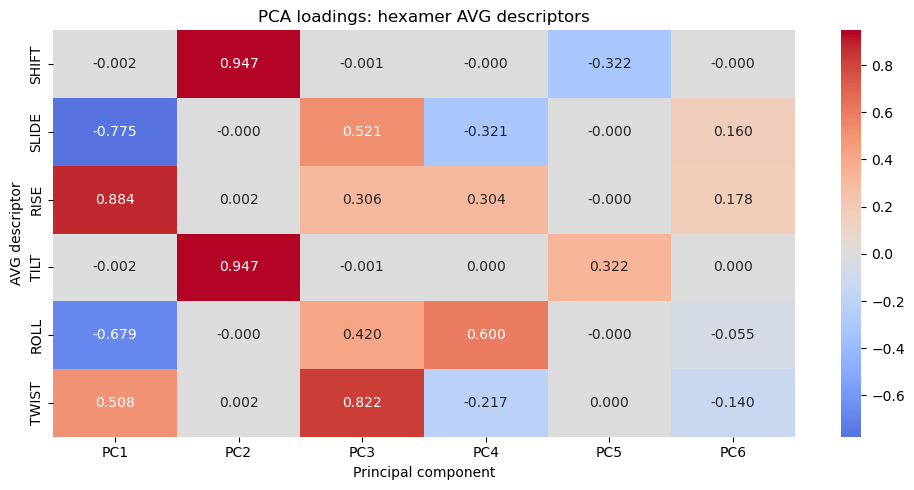

In [103]:
# Calculate loadings from the existing fitted hexamer PCA model
pca_loadings_hexa = pd.DataFrame(
    pca_hexamer_avg.components_.T
    * np.sqrt(pca_hexamer_avg.explained_variance_),
    index=hexamer_avg_features,
    columns=[f"PC{i}" for i in range(1, len(hexamer_avg_features) + 1)]
)
display(pca_loadings_hexa.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    pca_loadings_hexa,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: hexamer AVG descriptors")
ax.set_xlabel("Principal component")
ax.set_ylabel("AVG descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_avg_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the hexamer scores with vectors for the six AVG descriptors. A common scale factor is used to fit the arrows to the score range while preserving their directions and relative lengths.

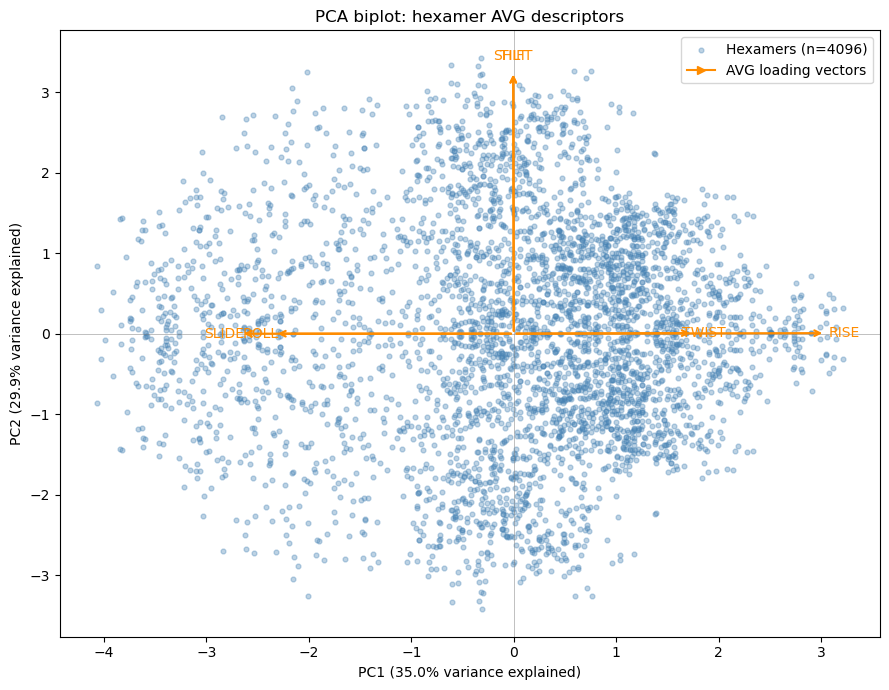

In [104]:
# Use the existing hexamer PCA scores and loading matrix
scores_pc12_hexa = scores_avg_hexa[:, :2]
loading_coordinates_hexa = pca_loadings_hexa[["PC1", "PC2"]].to_numpy()

# Apply one common scale factor so the longest arrow fits the score range
score_extent_hexa = np.abs(scores_pc12_hexa).max()
loading_extent_hexa = np.abs(loading_coordinates_hexa).max()
arrow_scale_hexa = 0.8 * score_extent_hexa / loading_extent_hexa

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    scores_pc12_hexa[:, 0],
    scores_pc12_hexa[:, 1],
    s=12,
    alpha=0.35,
    color="steelblue",
    label=f"Hexamers (n={len(scores_pc12_hexa)})"
)

for descriptor, (loading_x, loading_y) in zip(
    hexamer_avg_features, loading_coordinates_hexa
):
    end_x = loading_x * arrow_scale_hexa
    end_y = loading_y * arrow_scale_hexa
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="AVG loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: hexamer AVG descriptors")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_avg.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_avg.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_avg_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.3. PCA of tetramer FCE descriptors

The FCE matrix is symmetric, so this analysis uses its 21 unique upper-triangular elements, including the diagonal. The features are standardised before PCA, which is fitted separately to the 256 tetramers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2870,0.2870
1,PC2,0.2064,0.4934
2,PC3,0.0994,0.5928
3,PC4,0.0993,0.6921
4,PC5,0.0912,0.7832
5,PC6,0.0583,0.8415
6,PC7,0.0405,0.8821
7,PC8,0.0288,0.9109
8,PC9,0.0257,0.9366
9,PC10,0.0170,0.9536


,Variance threshold,Number of components
0,80%,6
1,90%,8
2,95%,10


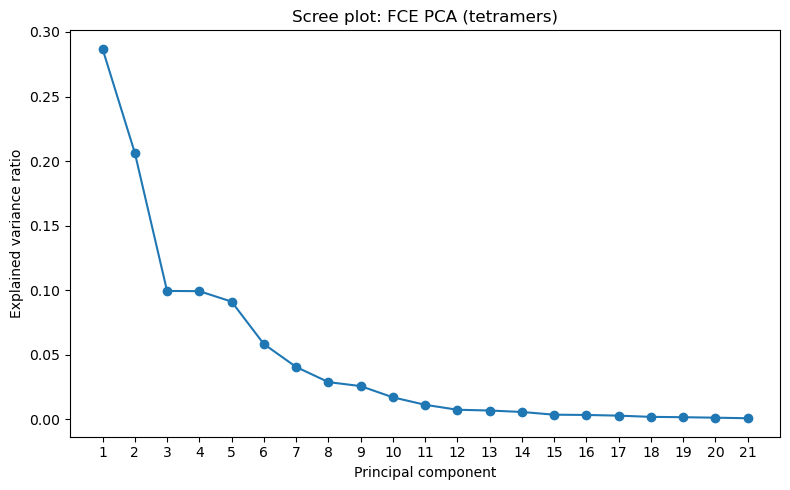

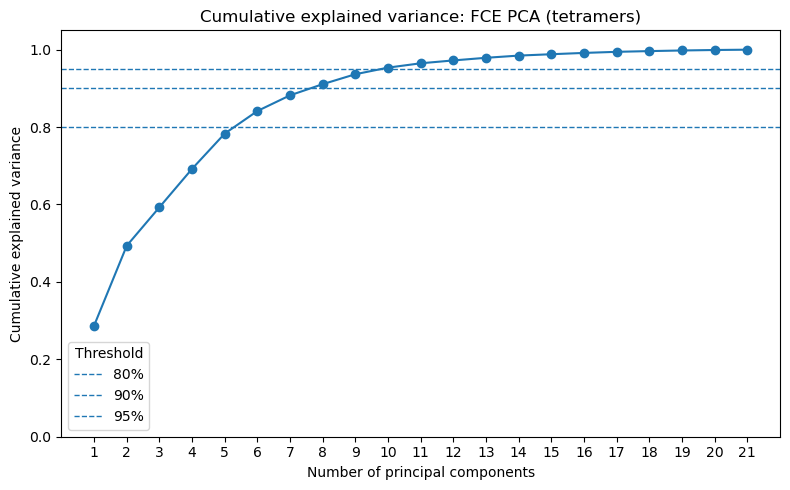

In [105]:
fce_degrees_tetra = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]
tetramer_fce_features = [
    f"{a}.{b}"
    for i, a in enumerate(fce_degrees_tetra)
    for b in fce_degrees_tetra[i:]
]
tetramer_fce_data = input_tetramer[tetramer_fce_features]

# Standardise all features before PCA
tetramer_fce_scaled = StandardScaler().fit_transform(tetramer_fce_data)

# Fit PCA and summarise explained variance
pca_tetramer_fce = PCA()
pca_tetramer_fce.fit(tetramer_fce_scaled)

cumulative_variance_tetramer_fce = np.cumsum(pca_tetramer_fce.explained_variance_ratio_)
pca_variance_tetramer_fce = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(tetramer_fce_features) + 1)
    ],
    "Explained variance ratio": pca_tetramer_fce.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_tetramer_fce
})
display(pca_variance_tetramer_fce.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_tetramer_fce = [0.80, 0.90, 0.95]
components_required_tetramer_fce = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_tetramer_fce],
    "Number of components": [
        np.searchsorted(cumulative_variance_tetramer_fce, threshold) + 1
        for threshold in variance_thresholds_tetramer_fce
    ]
})
display(components_required_tetramer_fce)

# Scree plot
components_tetramer_fce = np.arange(1, len(tetramer_fce_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_tetramer_fce,
    pca_tetramer_fce.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: FCE PCA (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_tetramer_fce)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_tetramer_fce, cumulative_variance_tetramer_fce, marker="o")
for threshold in variance_thresholds_tetramer_fce:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: FCE PCA (tetramers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_tetramer_fce)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one tetramer (256 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the FCE descriptors.

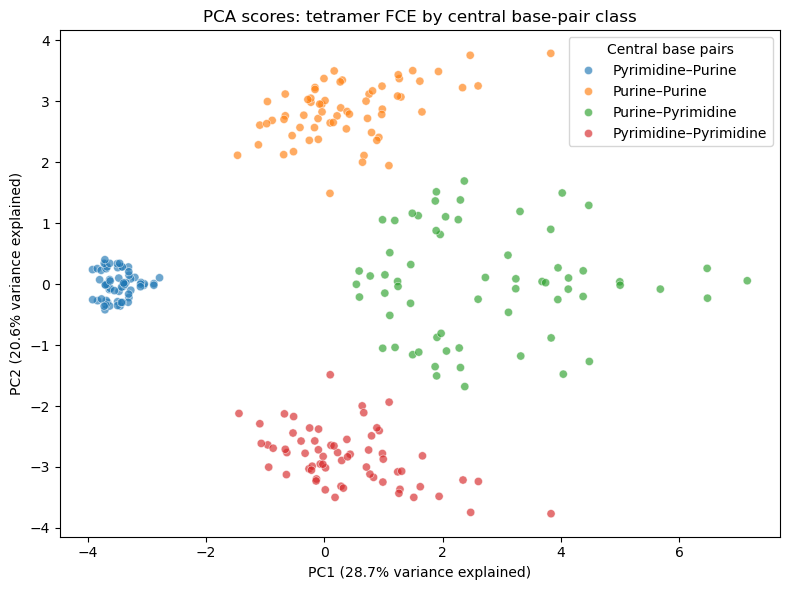

In [106]:
# Use the existing tetramer FCE PCA scores
scores_tetramer_fce = pca_tetramer_fce.transform(tetramer_fce_scaled)

# Classify the bases at sequence positions 2 and 3
base_class = {
    "A": "Purine",
    "G": "Purine",
    "C": "Pyrimidine",
    "T": "Pyrimidine"
}
category_order = [
    "Pyrimidine–Purine",
    "Purine–Purine",
    "Purine–Pyrimidine",
    "Pyrimidine–Pyrimidine"
]
central_pair_categories = pd.Categorical(
    [
        f"{base_class[sequence[1]]}–{base_class[sequence[2]]}"
        for sequence in input_tetramer["SEQUENCE"]
    ],
    categories=category_order,
    ordered=True
)

score_plot_data = pd.DataFrame({
    "PC1": scores_tetramer_fce[:, 0],
    "PC2": scores_tetramer_fce[:, 1],
    "Central dinucleotide class": central_pair_categories
})

category_colours = {
    "Pyrimidine–Purine": "#1f77b4",
    "Purine–Purine": "#ff7f0e",
    "Purine–Pyrimidine": "#2ca02c",
    "Pyrimidine–Pyrimidine": "#d62728"
}

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=score_plot_data,
    x="PC1",
    y="PC2",
    hue="Central dinucleotide class",
    hue_order=category_order,
    palette=category_colours,
    s=35,
    alpha=0.65,
    ax=ax
)
ax.set_title("PCA scores: tetramer FCE by central base-pair class")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend(title="Central base pairs")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Tetramer FCE scores by central base-pair class

This plot colours the existing tetramer FCE PC1–PC2 scores by the purine/pyrimidine classes of sequence positions 2 and 3. The PCA scores and axes are unchanged.

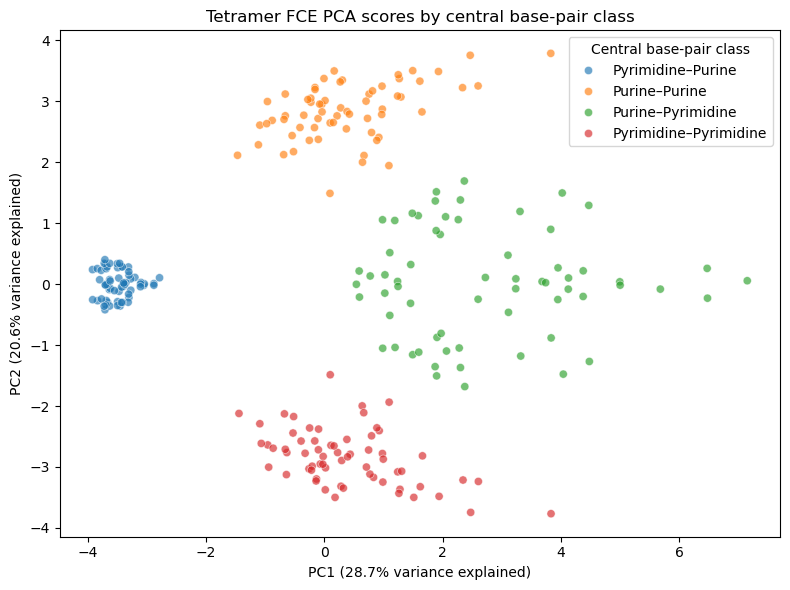

In [107]:
# Plot the existing tetramer FCE scores by central base-pair class
base_class = {"A": "Purine", "G": "Purine", "C": "Pyrimidine", "T": "Pyrimidine"}
category_order = [
    "Pyrimidine–Purine",
    "Purine–Purine",
    "Purine–Pyrimidine",
    "Pyrimidine–Pyrimidine",
]
central_pair_categories = pd.Categorical(
    [f"{base_class[sequence[1]]}–{base_class[sequence[2]]}"
     for sequence in input_tetramer["SEQUENCE"]],
    categories=category_order,
    ordered=True,
)

score_plot_data = pd.DataFrame({
    "PC1": scores_tetramer_fce[:, 0],
    "PC2": scores_tetramer_fce[:, 1],
    "Central base-pair class": central_pair_categories,
})
category_colours = {
    "Pyrimidine–Purine": "#1f77b4",
    "Purine–Purine": "#ff7f0e",
    "Purine–Pyrimidine": "#2ca02c",
    "Pyrimidine–Pyrimidine": "#d62728",
}

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=score_plot_data,
    x="PC1",
    y="PC2",
    hue="Central base-pair class",
    hue_order=category_order,
    palette=category_colours,
    s=35,
    alpha=0.65,
    ax=ax,
)
ax.set_title("Tetramer FCE PCA scores by central base-pair class")
ax.set_xlabel(f"PC1 ({pca_tetramer_fce.explained_variance_ratio_[0]:.1%} variance explained)")
ax.set_ylabel(f"PC2 ({pca_tetramer_fce.explained_variance_ratio_[1]:.1%} variance explained)")
ax.legend(title="Central base-pair class")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_scores_central_pairs.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original FCE descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21
SHIFT.SHIFT,0.804,0.001,-0.359,-0.158,-0.340,-0.060,0.005,-0.040,-0.162,0.001,...,-0.002,-0.004,-0.001,0.003,-0.001,0.154,-0.049,-0.053,-0.003,0.030
SHIFT.SLIDE,-0.001,0.838,0.099,-0.220,-0.002,-0.001,0.350,-0.001,0.001,-0.285,...,-0.050,-0.001,-0.155,-0.002,-0.111,-0.001,-0.001,-0.001,0.036,0.002
SHIFT.RISE,-0.001,0.927,0.055,-0.124,0.000,0.000,-0.100,-0.003,-0.003,-0.172,...,0.165,-0.000,0.236,0.000,-0.058,-0.000,-0.000,0.000,-0.015,-0.001
SHIFT.TILT,0.328,0.001,-0.193,-0.088,0.833,-0.115,-0.006,0.189,-0.176,0.000,...,0.002,-0.063,0.002,-0.056,0.000,0.049,0.023,-0.049,-0.002,0.008
SHIFT.ROLL,-0.004,0.868,0.075,-0.170,-0.001,0.003,-0.292,0.002,0.000,0.261,...,0.202,0.001,-0.136,-0.002,0.027,-0.000,0.000,-0.002,0.050,0.003
SHIFT.TWIST,-0.004,0.755,-0.215,0.481,0.002,-0.001,0.069,0.004,0.003,0.317,...,-0.185,0.001,0.088,0.001,-0.093,-0.001,-0.001,-0.001,0.034,0.002
SLIDE.SLIDE,0.758,0.002,0.081,0.033,0.418,-0.393,-0.001,-0.064,-0.124,-0.001,...,-0.001,0.248,-0.002,0.041,0.000,-0.052,-0.067,-0.001,0.001,-0.023
SLIDE.RISE,0.732,0.002,0.547,0.242,0.130,-0.006,-0.002,0.192,-0.083,-0.000,...,-0.000,-0.149,-0.002,0.108,-0.001,-0.077,-0.031,-0.019,-0.005,0.057
SLIDE.TILT,0.007,0.063,0.288,-0.639,-0.005,-0.008,0.673,0.011,0.007,0.213,...,0.038,0.001,0.068,0.001,0.065,-0.000,0.000,-0.001,0.002,-0.000
SLIDE.ROLL,-0.352,-0.000,0.647,0.287,-0.188,-0.505,-0.009,-0.091,0.238,-0.000,...,-0.001,-0.045,0.001,-0.107,0.001,0.020,-0.054,-0.069,-0.002,-0.005


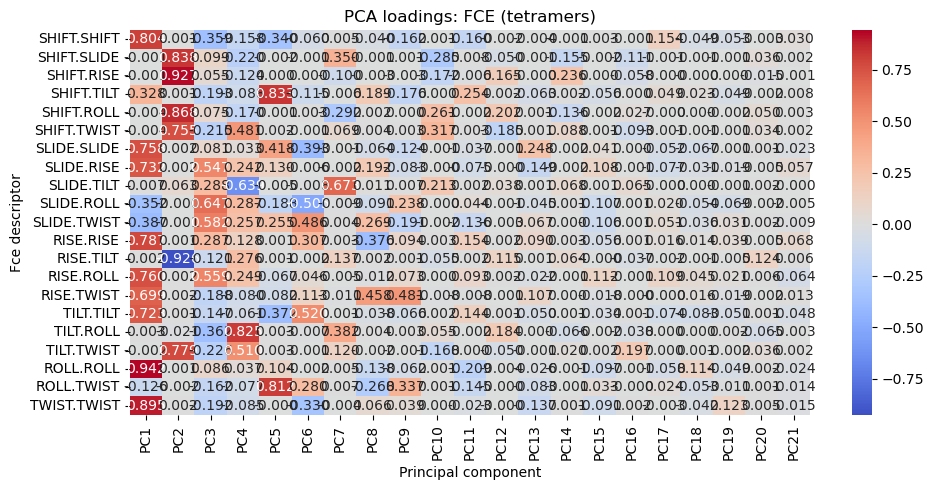

In [108]:
# Calculate loadings from the existing fitted PCA model
loadings_tetramer_fce = pd.DataFrame(
    pca_tetramer_fce.components_.T
    * np.sqrt(pca_tetramer_fce.explained_variance_),
    index=tetramer_fce_features,
    columns=[f"PC{i}" for i in range(1, len(tetramer_fce_features) + 1)]
)
display(loadings_tetramer_fce.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_tetramer_fce,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: FCE (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Fce descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the tetramer scores with vectors for the FCE descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

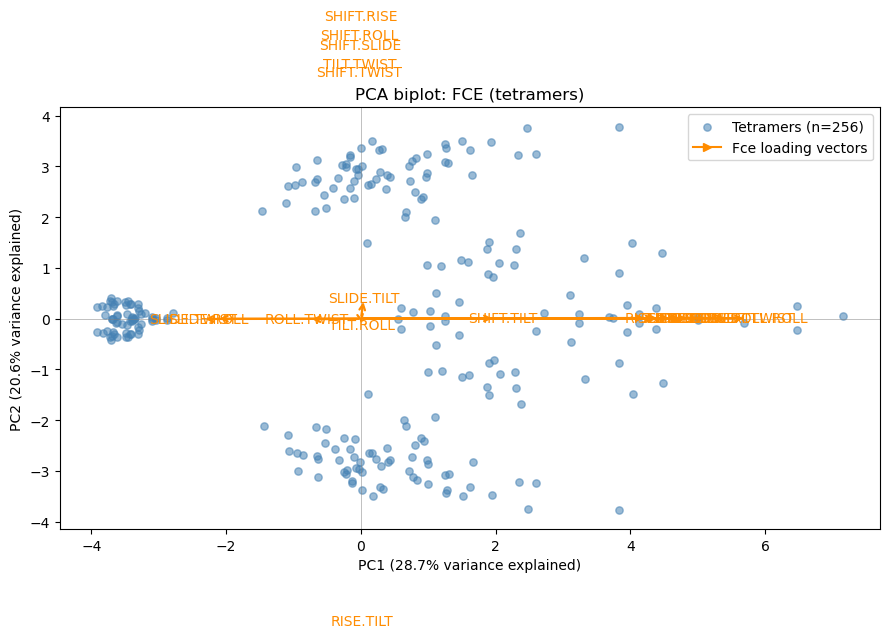

In [109]:
# Use the existing PCA scores and loading matrix
tetramer_fce_scores_pc12 = scores_tetramer_fce[:, :2]
tetramer_fce_loading_coordinates = loadings_tetramer_fce[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
tetramer_fce_score_extent = np.abs(tetramer_fce_scores_pc12).max()
tetramer_fce_loading_extent = np.abs(tetramer_fce_loading_coordinates).max()
tetramer_fce_arrow_scale = 0.8 * tetramer_fce_score_extent / tetramer_fce_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    tetramer_fce_scores_pc12[:, 0],
    tetramer_fce_scores_pc12[:, 1],
    s=28,
    alpha=0.55,
    color="steelblue",
    label=f"Tetramers (n={len(tetramer_fce_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    tetramer_fce_features, tetramer_fce_loading_coordinates
):
    end_x = loading_x * tetramer_fce_arrow_scale
    end_y = loading_y * tetramer_fce_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Fce loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: FCE (tetramers)")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.4. PCA of hexamer FCE descriptors

The FCE matrix is symmetric, so this analysis uses its 21 unique upper-triangular elements, including the diagonal. The features are standardised before PCA, which is fitted separately to the 4,096 hexamers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2838,0.2838
1,PC2,0.2011,0.4849
2,PC3,0.0974,0.5823
3,PC4,0.0929,0.6752
4,PC5,0.0902,0.7654
5,PC6,0.0589,0.8243
6,PC7,0.0431,0.8674
7,PC8,0.0291,0.8966
8,PC9,0.0253,0.9218
9,PC10,0.0193,0.9411


,Variance threshold,Number of components
0,80%,6
1,90%,9
2,95%,11


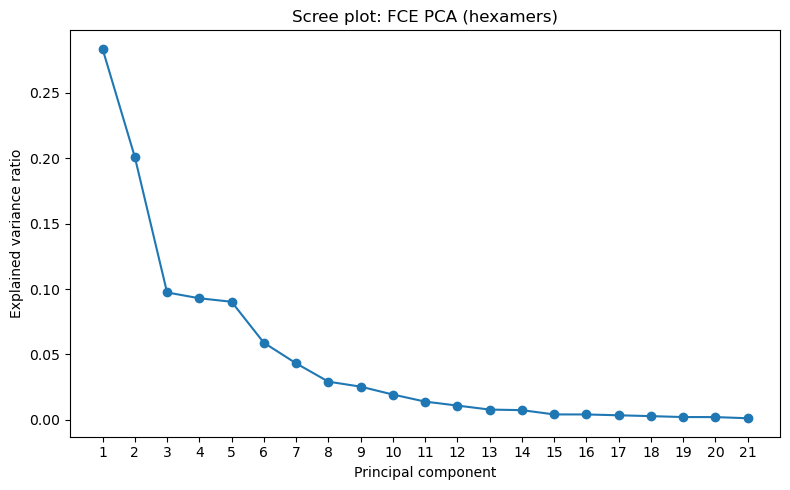

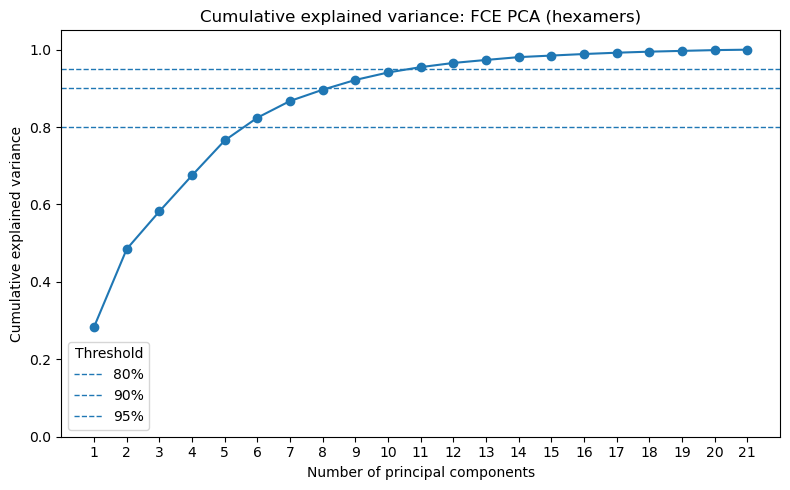

In [110]:
fce_degrees_hexa = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]
hexamer_fce_features = [
    f"{a}.{b}"
    for i, a in enumerate(fce_degrees_hexa)
    for b in fce_degrees_hexa[i:]
]
hexamer_fce_data = input_hexamer[hexamer_fce_features]

# Standardise all features before PCA
hexamer_fce_scaled = StandardScaler().fit_transform(hexamer_fce_data)

# Fit PCA and summarise explained variance
pca_hexamer_fce = PCA()
pca_hexamer_fce.fit(hexamer_fce_scaled)

cumulative_variance_hexamer_fce = np.cumsum(pca_hexamer_fce.explained_variance_ratio_)
pca_variance_hexamer_fce = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(hexamer_fce_features) + 1)
    ],
    "Explained variance ratio": pca_hexamer_fce.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_hexamer_fce
})
display(pca_variance_hexamer_fce.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_hexamer_fce = [0.80, 0.90, 0.95]
components_required_hexamer_fce = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_hexamer_fce],
    "Number of components": [
        np.searchsorted(cumulative_variance_hexamer_fce, threshold) + 1
        for threshold in variance_thresholds_hexamer_fce
    ]
})
display(components_required_hexamer_fce)

# Scree plot
components_hexamer_fce = np.arange(1, len(hexamer_fce_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_hexamer_fce,
    pca_hexamer_fce.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: FCE PCA (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_hexamer_fce)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_hexamer_fce, cumulative_variance_hexamer_fce, marker="o")
for threshold in variance_thresholds_hexamer_fce:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: FCE PCA (hexamers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_hexamer_fce)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one hexamer (4,096 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the FCE descriptors.

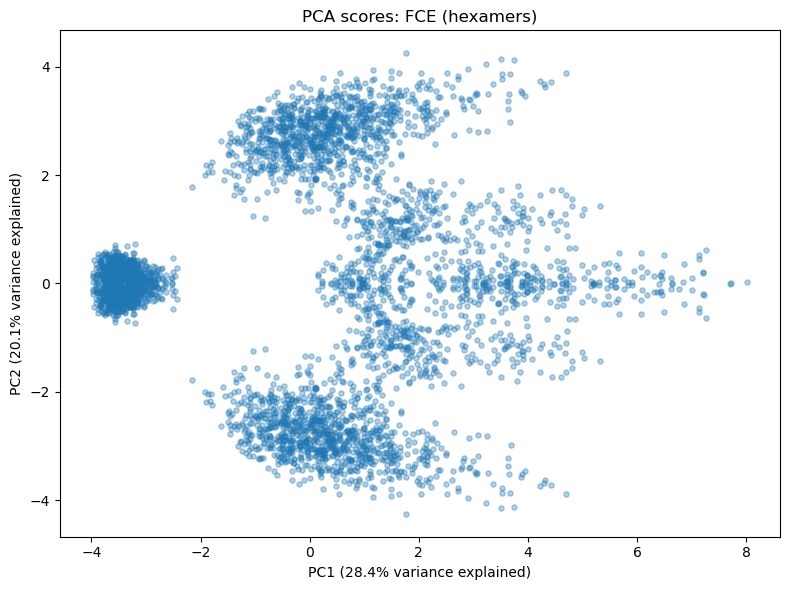

In [111]:
# Project the standardised features onto the fitted principal components
scores_hexamer_fce = pca_hexamer_fce.transform(hexamer_fce_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_hexamer_fce[:, 0],
    scores_hexamer_fce[:, 1],
    s=14,
    alpha=0.35
)
ax.set_title("PCA scores: FCE (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original FCE descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21
SHIFT.SHIFT,0.802,0.000,-0.387,-0.005,-0.329,-0.027,0.000,-0.070,-0.136,-0.001,...,-0.000,0.000,0.035,0.001,0.006,0.159,-0.064,0.002,-0.055,-0.041
SHIFT.SLIDE,-0.000,-0.827,0.001,-0.231,0.002,-0.001,0.291,-0.000,0.001,0.354,...,0.045,-0.190,0.000,-0.113,0.016,0.000,-0.000,0.031,0.001,-0.000
SHIFT.RISE,0.000,-0.916,0.001,-0.152,0.002,0.000,-0.041,0.000,0.000,0.107,...,-0.154,0.307,-0.001,-0.078,0.012,0.000,0.000,0.006,0.000,-0.000
SHIFT.TILT,0.311,-0.000,-0.209,0.010,0.832,-0.145,0.000,0.120,-0.212,0.001,...,0.000,-0.000,-0.080,0.010,0.064,0.070,0.027,0.002,-0.048,-0.011
SHIFT.ROLL,-0.000,-0.842,-0.000,-0.160,0.002,0.001,-0.279,0.000,-0.001,-0.309,...,-0.254,-0.163,0.001,-0.003,-0.000,0.000,-0.000,0.046,0.002,-0.000
SHIFT.TWIST,-0.000,-0.741,-0.001,0.514,-0.007,-0.000,0.076,-0.000,0.000,-0.294,...,0.290,0.042,-0.000,-0.074,0.011,0.000,0.000,0.053,0.002,-0.000
SLIDE.SLIDE,0.762,-0.000,0.076,0.005,0.384,-0.410,-0.000,-0.110,-0.098,0.000,...,0.001,0.001,0.243,-0.008,-0.051,-0.090,-0.066,0.001,-0.031,0.021
SLIDE.RISE,0.721,0.000,0.594,0.003,0.149,-0.001,-0.000,0.163,-0.140,-0.001,...,-0.000,-0.001,-0.144,-0.017,-0.115,-0.067,0.012,0.000,-0.014,-0.073
SLIDE.TILT,0.001,-0.036,0.003,-0.624,0.006,-0.002,0.745,0.000,0.001,-0.218,...,-0.026,0.040,-0.000,0.065,-0.010,-0.000,-0.000,0.016,0.000,-0.000
SLIDE.ROLL,-0.329,0.000,0.702,-0.001,-0.218,-0.513,-0.002,-0.013,0.253,0.000,...,-0.000,-0.000,-0.051,0.016,0.108,0.014,-0.035,0.003,-0.091,-0.006


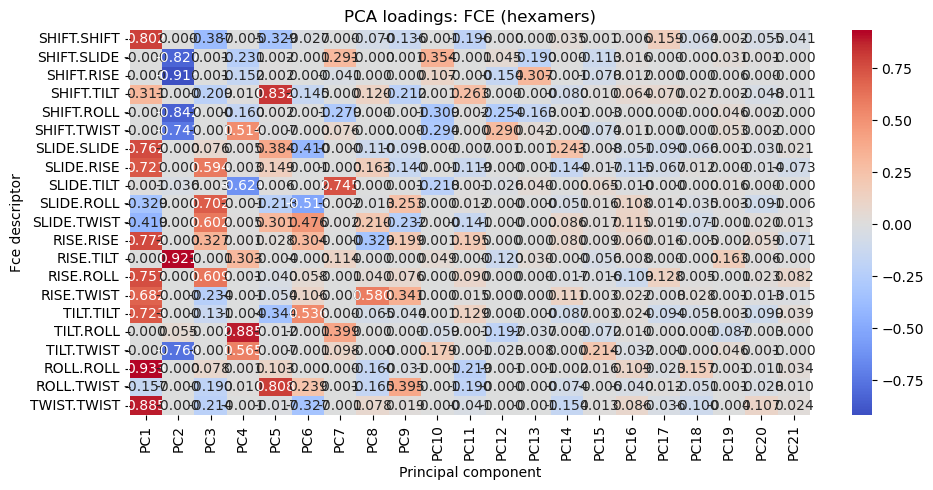

In [112]:
# Calculate loadings from the existing fitted PCA model
loadings_hexamer_fce = pd.DataFrame(
    pca_hexamer_fce.components_.T
    * np.sqrt(pca_hexamer_fce.explained_variance_),
    index=hexamer_fce_features,
    columns=[f"PC{i}" for i in range(1, len(hexamer_fce_features) + 1)]
)
display(loadings_hexamer_fce.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_hexamer_fce,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: FCE (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Fce descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the hexamer scores with vectors for the FCE descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

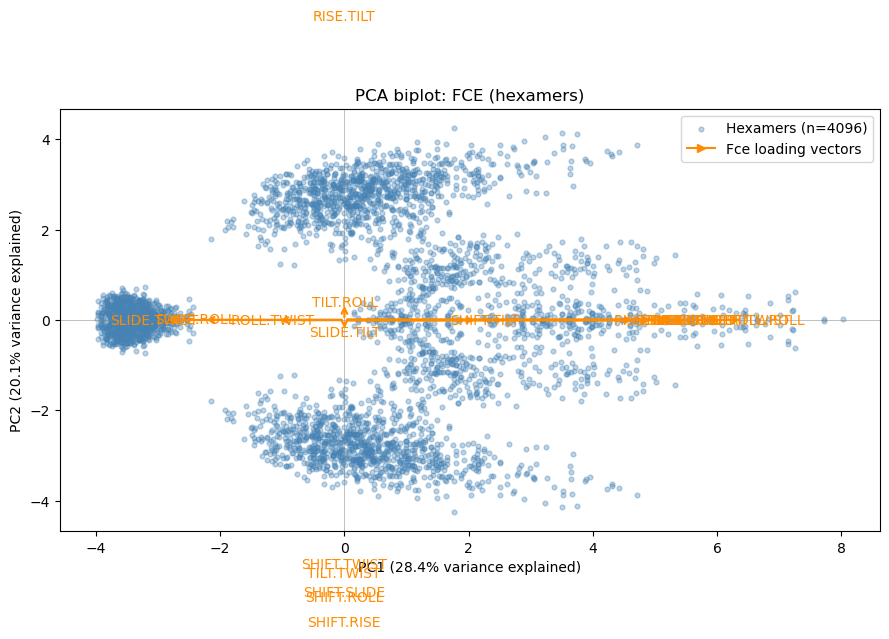

In [113]:
# Use the existing PCA scores and loading matrix
hexamer_fce_scores_pc12 = scores_hexamer_fce[:, :2]
hexamer_fce_loading_coordinates = loadings_hexamer_fce[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
hexamer_fce_score_extent = np.abs(hexamer_fce_scores_pc12).max()
hexamer_fce_loading_extent = np.abs(hexamer_fce_loading_coordinates).max()
hexamer_fce_arrow_scale = 0.8 * hexamer_fce_score_extent / hexamer_fce_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    hexamer_fce_scores_pc12[:, 0],
    hexamer_fce_scores_pc12[:, 1],
    s=12,
    alpha=0.35,
    color="steelblue",
    label=f"Hexamers (n={len(hexamer_fce_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    hexamer_fce_features, hexamer_fce_loading_coordinates
):
    end_x = loading_x * hexamer_fce_arrow_scale
    end_y = loading_y * hexamer_fce_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Fce loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: FCE (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


#### FCE profile uniqueness summary

We count exact profiles using the 21 independent upper-triangular FCE columns from the raw tetramer and hexamer FCE tables. No rounding is applied.

In [114]:
# Use the 21 independent FCE columns defined for the PCA analysis
tetramer_fce_profiles = fce_tetramer[tetramer_fce_features]
hexamer_fce_profiles = fce_hexamer[hexamer_fce_features]

# Count identical raw FCE rows without rounding
tetramer_fce_profile_counts = tetramer_fce_profiles.value_counts(
    dropna=False, sort=False
)
hexamer_fce_profile_counts = hexamer_fce_profiles.value_counts(
    dropna=False, sort=False
)

fce_profile_summary = pd.DataFrame([
    {
        "Dataset": "Tetramers",
        "Total sequences": len(fce_tetramer),
        "Independent FCE features": len(tetramer_fce_features),
        "Unique FCE profiles": len(tetramer_fce_profile_counts),
        "Repeated profiles": int((tetramer_fce_profile_counts > 1).sum())
    },
    {
        "Dataset": "Hexamers",
        "Total sequences": len(fce_hexamer),
        "Independent FCE features": len(hexamer_fce_features),
        "Unique FCE profiles": len(hexamer_fce_profile_counts),
        "Repeated profiles": int((hexamer_fce_profile_counts > 1).sum())
    }
])

print("Tetramer FCE columns:", tetramer_fce_features)
print("Hexamer FCE columns:", hexamer_fce_features)
display(fce_profile_summary)

Tetramer FCE columns: ['SHIFT.SHIFT', 'SHIFT.SLIDE', 'SHIFT.RISE', 'SHIFT.TILT', 'SHIFT.ROLL', 'SHIFT.TWIST', 'SLIDE.SLIDE', 'SLIDE.RISE', 'SLIDE.TILT', 'SLIDE.ROLL', 'SLIDE.TWIST', 'RISE.RISE', 'RISE.TILT', 'RISE.ROLL', 'RISE.TWIST', 'TILT.TILT', 'TILT.ROLL', 'TILT.TWIST', 'ROLL.ROLL', 'ROLL.TWIST', 'TWIST.TWIST']
Hexamer FCE columns: ['SHIFT.SHIFT', 'SHIFT.SLIDE', 'SHIFT.RISE', 'SHIFT.TILT', 'SHIFT.ROLL', 'SHIFT.TWIST', 'SLIDE.SLIDE', 'SLIDE.RISE', 'SLIDE.TILT', 'SLIDE.ROLL', 'SLIDE.TWIST', 'RISE.RISE', 'RISE.TILT', 'RISE.ROLL', 'RISE.TWIST', 'TILT.TILT', 'TILT.ROLL', 'TILT.TWIST', 'ROLL.ROLL', 'ROLL.TWIST', 'TWIST.TWIST']


,Dataset,Total sequences,Independent FCE features,Unique FCE profiles,Repeated profiles
0,Tetramers,256,21,256,0
1,Hexamers,4096,21,4096,0


**Results.** Exact row comparison finds no repeated FCE profiles in either dataset.

| Dataset | Total sequences | Independent FCE features | Unique FCE profiles | Repeated profiles |
| --- | ---: | ---: | ---: | ---: |
| Tetramers | 256 | 21 | 256 | 0 |
| Hexamers | 4,096 | 21 | 4,096 | 0 |

#### Pairwise FCE profile distances

We standardise the 21 independent FCE features and calculate Euclidean distances between every pair of profiles. The original FCE rows align exactly with the sequence order in the combined tables, allowing the closest pairs to be labelled by sequence. Distances are calculated before any display rounding.

In [115]:
from scipy.spatial.distance import pdist

def fce_pairwise_distance_analysis(fce_df, feature_names, sequences):
    scaled_profiles = StandardScaler().fit_transform(fce_df[feature_names])
    distances = pdist(scaled_profiles, metric="euclidean")

    distance_summary = {
        "Pairwise comparisons": len(distances),
        "Mean distance": distances.mean(),
        "Median distance": np.median(distances),
        "Standard deviation": distances.std(),
        "Minimum distance": distances.min()
    }

    # Retrieve the sequence indices for the 10 smallest condensed distances
    smallest_indices = np.argsort(distances, kind="stable")[:10]
    n_sequences = len(sequences)
    row_starts = np.arange(n_sequences - 1) * (2 * n_sequences - np.arange(n_sequences - 1) - 1) // 2
    first_indices = np.searchsorted(row_starts, smallest_indices, side="right") - 1
    second_indices = first_indices + 1 + smallest_indices - row_starts[first_indices]

    closest_pairs = pd.DataFrame({
        "Sequence 1": sequences.iloc[first_indices].to_numpy(),
        "Sequence 2": sequences.iloc[second_indices].to_numpy(),
        "Distance": distances[smallest_indices]
    })
    return distance_summary, closest_pairs

# The raw FCE rows match the sequence order in the combined feature tables
assert len(fce_tetramer) == len(input_tetramer)
assert len(fce_hexamer) == len(input_hexamer)

tetramer_fce_distance_stats, tetramer_fce_closest_pairs = fce_pairwise_distance_analysis(
    fce_tetramer, tetramer_fce_features, input_tetramer["SEQUENCE"]
)
hexamer_fce_distance_stats, hexamer_fce_closest_pairs = fce_pairwise_distance_analysis(
    fce_hexamer, hexamer_fce_features, input_hexamer["SEQUENCE"]
)

fce_distance_summary = pd.DataFrame([
    {"Dataset": "Tetramers", **tetramer_fce_distance_stats},
    {"Dataset": "Hexamers", **hexamer_fce_distance_stats}
])
display(fce_distance_summary.round(6))

print("10 closest tetramer sequence pairs:")
display(tetramer_fce_closest_pairs.round({"Distance": 6}))

print("10 closest hexamer sequence pairs:")
display(hexamer_fce_closest_pairs.round({"Distance": 6}))

,Dataset,Pairwise comparisons,Mean distance,Median distance,Standard deviation,Minimum distance
0,Tetramers,32640,6.270235,6.491428,1.687855,0.661692
1,Hexamers,8386560,6.256092,6.453204,1.694570,0.259865


10 closest tetramer sequence pairs:


,Sequence 1,Sequence 2,Distance
0,CCGG,TCGG,0.661692
1,CGAA,TGAA,0.683408
2,TTCA,TTCG,0.683408
3,CCGA,TCGA,0.704056
4,TCGA,TCGG,0.714275
5,CCAG,TCAG,0.735607
6,CTGA,CTGG,0.735607
7,CCGC,TCGC,0.739757
8,GCGA,GCGG,0.739757
9,CGTA,TGTA,0.780445


10 closest hexamer sequence pairs:


,Sequence 1,Sequence 2,Distance
0,CACTAA,TACTAA,0.259865
1,TTAGTA,TTAGTG,0.259865
2,CATAAA,CATAAC,0.282290
3,GTTATG,TTTATG,0.282290
4,CAGGAC,TAGGAC,0.308510
5,GTCCTA,GTCCTG,0.308510
6,CGATCA,TGATCA,0.312980
7,CCTAAC,CCTAAG,0.318977
8,CTTAGG,GTTAGG,0.318977
9,CTTACA,GTTACA,0.332775


**Observed results.** The closest pairs are much nearer than the median pairwise distance in both datasets. All ten listed pairs in each dataset differ at one nucleotide. In the tetramer list, `TCGG` appears in two of the closest pairs; the hexamer top-ten pairs are distinct. These observations indicate particularly similar, but not identical, FCE profiles among the listed sequences; no clustering is inferred.

| Dataset | Pairwise comparisons | Mean | Median | Standard deviation | Minimum |
| --- | ---: | ---: | ---: | ---: | ---: |
| Tetramers | 32,640 | 6.270235 | 6.491428 | 1.687855 | 0.661692 |
| Hexamers | 8,386,560 | 6.256092 | 6.453204 | 1.694570 | 0.259865 |

**10 closest tetramer pairs**

| Sequence 1 | Sequence 2 | Distance |
| --- | --- | ---: |
| CCGG | TCGG | 0.661692 |
| CGAA | TGAA | 0.683408 |
| TTCA | TTCG | 0.683408 |
| CCGA | TCGA | 0.704056 |
| TCGA | TCGG | 0.714275 |
| CCAG | TCAG | 0.735607 |
| CTGA | CTGG | 0.735607 |
| CCGC | TCGC | 0.739757 |
| GCGA | GCGG | 0.739757 |
| CGTA | TGTA | 0.780445 |

**10 closest hexamer pairs**

| Sequence 1 | Sequence 2 | Distance |
| --- | --- | ---: |
| CACTAA | TACTAA | 0.259865 |
| TTAGTA | TTAGTG | 0.259865 |
| CATAAA | CATAAC | 0.282290 |
| GTTATG | TTTATG | 0.282290 |
| CAGGAC | TAGGAC | 0.308510 |
| GTCCTA | GTCCTG | 0.308510 |
| CGATCA | TGATCA | 0.312980 |
| CCTAAC | CCTAAG | 0.318977 |
| CTTAGG | GTTAGG | 0.318977 |
| CTTACA | GTTACA | 0.332775 |

#### Compact negative-PC1 FCE group

To identify the compact region reproducibly without clustering, we sort the existing negative PC1 scores and split at the midpoint of their largest adjacent gap. The resulting cutoff is used to identify sequences; pairwise distances are then calculated from the existing standardised 21-feature FCE matrices.

In [116]:
from scipy.spatial.distance import pdist

def identify_negative_pc1_group(scores):
    negative_pc1 = np.sort(scores[scores[:, 0] < 0, 0])
    pc1_gaps = np.diff(negative_pc1)
    largest_gap_index = np.argmax(pc1_gaps)
    cutoff = (negative_pc1[largest_gap_index] + negative_pc1[largest_gap_index + 1]) / 2
    return scores[:, 0] < cutoff, cutoff, pc1_gaps[largest_gap_index]


def within_group_distance_stats(standardised_features, group_mask):
    group_distances = pdist(standardised_features[group_mask], metric="euclidean")
    remaining_distances = pdist(standardised_features[~group_mask], metric="euclidean")

    return [
        {
            "Subset": "Compact negative-PC1 group",
            "Sequences": int(group_mask.sum()),
            "Pairwise comparisons": len(group_distances),
            "Mean distance": group_distances.mean(),
            "Median distance": np.median(group_distances),
            "Standard deviation": group_distances.std(),
            "Minimum distance": group_distances.min()
        },
        {
            "Subset": "Remaining sequences",
            "Sequences": int((~group_mask).sum()),
            "Pairwise comparisons": len(remaining_distances),
            "Mean distance": remaining_distances.mean(),
            "Median distance": np.median(remaining_distances),
            "Standard deviation": remaining_distances.std(),
            "Minimum distance": remaining_distances.min()
        }
    ]


# Identify the negative-PC1 groups using the existing FCE PCA scores
tetramer_fce_compact_mask, tetramer_fce_pc1_cutoff, tetramer_fce_pc1_gap = identify_negative_pc1_group(
    scores_tetramer_fce
)
hexamer_fce_compact_mask, hexamer_fce_pc1_cutoff, hexamer_fce_pc1_gap = identify_negative_pc1_group(
    scores_hexamer_fce
)

# Retain all identified sequences and their existing PC1/PC2 scores
fce_tetramer_compact_group = pd.DataFrame({
    "SEQUENCE": input_tetramer["SEQUENCE"].to_numpy()[tetramer_fce_compact_mask],
    "PC1": scores_tetramer_fce[tetramer_fce_compact_mask, 0],
    "PC2": scores_tetramer_fce[tetramer_fce_compact_mask, 1]
}).sort_values("PC1").reset_index(drop=True)

fce_hexamer_compact_group = pd.DataFrame({
    "SEQUENCE": input_hexamer["SEQUENCE"].to_numpy()[hexamer_fce_compact_mask],
    "PC1": scores_hexamer_fce[hexamer_fce_compact_mask, 0],
    "PC2": scores_hexamer_fce[hexamer_fce_compact_mask, 1]
}).sort_values("PC1").reset_index(drop=True)

# Compare within-group and remaining-sequence distances using the original standardised FCE features
fce_compact_distance_rows = []
for dataset, scaled_features, group_mask in [
    ("Tetramers", tetramer_fce_scaled, tetramer_fce_compact_mask),
    ("Hexamers", hexamer_fce_scaled, hexamer_fce_compact_mask)
]:
    for distance_stats in within_group_distance_stats(scaled_features, group_mask):
        distance_stats["Dataset"] = dataset
        fce_compact_distance_rows.append(distance_stats)
fce_compact_distance_summary = pd.DataFrame(fce_compact_distance_rows)[[
    "Dataset", "Subset", "Sequences", "Pairwise comparisons",
    "Mean distance", "Median distance", "Standard deviation", "Minimum distance"
]]

fce_compact_group_summary = pd.DataFrame([
    {
        "Dataset": "Tetramers",
        "Negative-PC1 cutoff": tetramer_fce_pc1_cutoff,
        "Largest gap": tetramer_fce_pc1_gap,
        "Sequences in compact group": len(fce_tetramer_compact_group)
    },
    {
        "Dataset": "Hexamers",
        "Negative-PC1 cutoff": hexamer_fce_pc1_cutoff,
        "Largest gap": hexamer_fce_pc1_gap,
        "Sequences in compact group": len(fce_hexamer_compact_group)
    }
])

display(fce_compact_group_summary.round(6))
display(fce_compact_distance_summary.round(6))

print("First 15 tetramer sequences in the compact region (full list: fce_tetramer_compact_group):")
display(fce_tetramer_compact_group.head(15))
print("First 15 hexamer sequences in the compact region (full list: fce_hexamer_compact_group):")
display(fce_hexamer_compact_group.head(15))


,Dataset,Negative-PC1 cutoff,Largest gap,Sequences in compact group
0,Tetramers,-2.123882,1.318498,64
1,Hexamers,-2.293524,0.284905,1024


,Dataset,Subset,Sequences,Pairwise comparisons,Mean distance,Median distance,Standard deviation,Minimum distance
0,Tetramers,Compact negative-PC1 group,64,2016,2.892555,2.789356,0.938526,0.661692
1,Tetramers,Remaining sequences,192,18336,6.235033,6.534510,1.614072,0.683408
2,Hexamers,Compact negative-PC1 group,1024,523776,2.921294,2.835891,0.918320,0.282290
3,Hexamers,Remaining sequences,3072,4717056,6.245439,6.493368,1.613760,0.259865


First 15 tetramer sequences in the compact region (full list: fce_tetramer_compact_group):


,SEQUENCE,PC1,PC2
0,ACAA,-3.915859,0.237955
1,TTGT,-3.913681,-0.255449
2,ACAG,-3.835689,0.254689
3,CTGT,-3.829563,-0.272052
4,TTAA,-3.795585,0.071785
5,ATAA,-3.769403,0.225951
6,TTAT,-3.764011,-0.243486
7,TTGA,-3.718686,-0.361609
8,TCAA,-3.717988,0.341822
9,TCAG,-3.706521,0.401056


First 15 hexamer sequences in the compact region (full list: fce_hexamer_compact_group):


,SEQUENCE,PC1,PC2
0,GTTAAC,-3.979921,0.021132
1,CACAAC,-3.971666,-0.109560
2,GTTGTG,-3.971666,0.110644
3,TACAAC,-3.970330,-0.146226
4,GTTGTA,-3.970297,0.147197
5,TACAAG,-3.965382,-0.185896
6,CTTGTA,-3.964926,0.186876
7,GACAAC,-3.961221,-0.427126
8,GTTGTC,-3.960809,0.428085
9,CACAAA,-3.924334,-0.278820


**Observed findings.** The group is defined by the midpoint of the largest gap among negative PC1 scores (using the existing PCA score orientation):

| Dataset | PC1 cutoff | Largest gap | Sequences in group |
| --- | ---: | ---: | ---: |
| Tetramers | -2.123882 | 1.318498 | 64 / 256 |
| Hexamers | -2.293524 | 0.284905 | 1,024 / 4,096 |

Within-group pairwise FCE distances are lower overall than distances among the remaining sequences:

| Dataset | Subset | Pairwise comparisons | Mean | Median | Standard deviation | Minimum |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Tetramers | Compact group | 2,016 | 2.892555 | 2.789356 | 0.938526 | 0.661692 |
| Tetramers | Remaining | 18,336 | 6.235033 | 6.534510 | 1.614072 | 0.683408 |
| Hexamers | Compact group | 523,776 | 2.921294 | 2.835891 | 0.918320 | 0.282290 |
| Hexamers | Remaining | 4,717,056 | 6.245439 | 6.493368 | 1.613760 | 0.259865 |

The lower within-group means and medians support the interpretation that these sequences have more similar standardised FCE profiles overall, though the profiles are not identical. The minimum distance is slightly lower among the remaining hexamers, so the result does not mean every compact-group pair is closer. The complete sequence lists are retained in `fce_tetramer_compact_group` and `fce_hexamer_compact_group`; the code cell displays the first 15 entries from each.

#### PCA scores highlighting the compact groups

The existing PC1–PC2 scores and compact-group masks are reused. Remaining sequences stay visible in the background, while the selected compact-group sequences are highlighted.

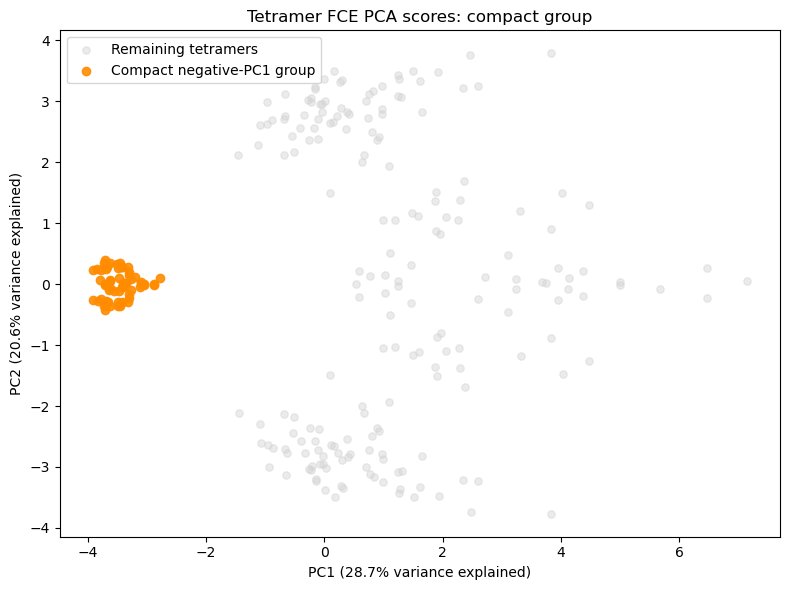

In [117]:
# Tetramer FCE PCA scores with the compact group highlighted
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_tetramer_fce[~tetramer_fce_compact_mask, 0],
    scores_tetramer_fce[~tetramer_fce_compact_mask, 1],
    s=28,
    alpha=0.45,
    color="lightgrey",
    label="Remaining tetramers"
)
ax.scatter(
    scores_tetramer_fce[tetramer_fce_compact_mask, 0],
    scores_tetramer_fce[tetramer_fce_compact_mask, 1],
    s=36,
    alpha=0.9,
    color="darkorange",
    label="Compact negative-PC1 group"
)
ax.set_title("Tetramer FCE PCA scores: compact group")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_fce_scores_compact_group.png", dpi=300, bbox_inches="tight")
plt.show()

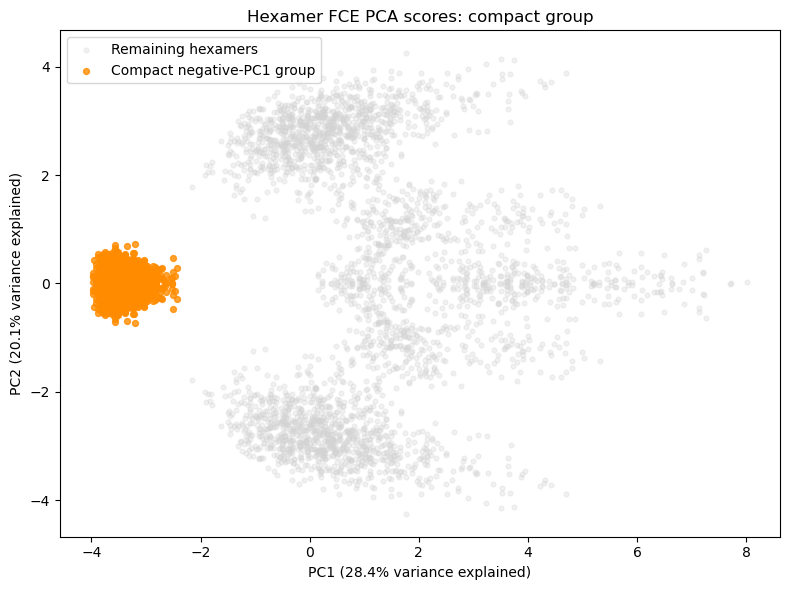

In [118]:
# Hexamer FCE PCA scores with the compact group highlighted
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_hexamer_fce[~hexamer_fce_compact_mask, 0],
    scores_hexamer_fce[~hexamer_fce_compact_mask, 1],
    s=12,
    alpha=0.3,
    color="lightgrey",
    label="Remaining hexamers"
)
ax.scatter(
    scores_hexamer_fce[hexamer_fce_compact_mask, 0],
    scores_hexamer_fce[hexamer_fce_compact_mask, 1],
    s=18,
    alpha=0.8,
    color="darkorange",
    label="Compact negative-PC1 group"
)
ax.set_title("Hexamer FCE PCA scores: compact group")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_fce.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_fce.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_fce_scores_compact_group.png", dpi=300, bbox_inches="tight")
plt.show()

#### Sequence characteristics of compact FCE groups

We compare the existing compact-group masks with the remaining sequences. GC and overall base composition are calculated per sequence; positional nucleotide frequencies and dinucleotide prevalence are compared separately. Dinucleotide prevalence is the percentage of sequences containing each motif at least once.

In [119]:
from itertools import product
from scipy.stats import chi2_contingency, fisher_exact, mannwhitneyu

nucleotides = ["A", "C", "G", "T"]
group_order = ["Compact group", "Remaining"]
dinucleotides = ["".join(pair) for pair in product(nucleotides, repeat=2)]

sequence_records = []
position_frequency_rows = []
dinucleotide_frequency_rows = []
gc_test_rows = []
base_test_rows = []
position_test_rows = []
dinucleotide_test_rows = []

for dataset, sequences, compact_mask in [
    ("Tetramers", input_tetramer["SEQUENCE"], tetramer_fce_compact_mask),
    ("Hexamers", input_hexamer["SEQUENCE"], hexamer_fce_compact_mask)
]:
    sequence_array = sequences.astype(str).to_numpy()
    groups = np.where(compact_mask, "Compact group", "Remaining")
    sequence_length = len(sequence_array[0])

    # Per-sequence GC content and overall nucleotide composition
    for sequence, group in zip(sequence_array, groups):
        record = {
            "Dataset": dataset,
            "Group": group,
            "GC content (%)": 100 * (sequence.count("G") + sequence.count("C")) / sequence_length
        }
        for nucleotide in nucleotides:
            record[f"{nucleotide} (%)"] = 100 * sequence.count(nucleotide) / sequence_length
        sequence_records.append(record)

    sequence_data = pd.DataFrame([
        row for row in sequence_records if row["Dataset"] == dataset
    ])
    compact_data = sequence_data[sequence_data["Group"] == "Compact group"]
    remaining_data = sequence_data[sequence_data["Group"] == "Remaining"]

    # GC-content comparison between groups
    gc_test = mannwhitneyu(
        compact_data["GC content (%)"],
        remaining_data["GC content (%)"],
        alternative="two-sided"
    )
    gc_test_rows.append({
        "Dataset": dataset,
        "Compact mean GC (%)": compact_data["GC content (%)"].mean(),
        "Compact median GC (%)": compact_data["GC content (%)"].median(),
        "Remaining mean GC (%)": remaining_data["GC content (%)"].mean(),
        "Remaining median GC (%)": remaining_data["GC content (%)"].median(),
        "Mann–Whitney p-value": gc_test.pvalue
    })

    # Overall nucleotide composition comparisons, using per-sequence percentages
    for nucleotide in nucleotides:
        column = f"{nucleotide} (%)"
        test = mannwhitneyu(
            compact_data[column], remaining_data[column], alternative="two-sided"
        )
        base_test_rows.append({
            "Dataset": dataset,
            "Nucleotide": nucleotide,
            "Compact mean (%)": compact_data[column].mean(),
            "Remaining mean (%)": remaining_data[column].mean(),
            "Mann–Whitney p-value": test.pvalue
        })

    # Position-specific nucleotide frequencies and group comparisons
    for position in range(sequence_length):
        position_bases = [sequence[position] for sequence in sequence_array]
        contingency = pd.crosstab(pd.Series(groups), pd.Series(position_bases))
        contingency = contingency.reindex(index=group_order, columns=nucleotides, fill_value=0)
        test = chi2_contingency(contingency)
        position_test_rows.append({
            "Dataset": dataset,
            "Position": position + 1,
            "Chi-square p-value": test.pvalue
        })

        for group in group_order:
            bases_in_group = [
                sequence[position]
                for sequence, sequence_group in zip(sequence_array, groups)
                if sequence_group == group
            ]
            for nucleotide in nucleotides:
                position_frequency_rows.append({
                    "Dataset": dataset,
                    "Group": group,
                    "Position": position + 1,
                    "Nucleotide": nucleotide,
                    "Frequency (%)": 100 * bases_in_group.count(nucleotide) / len(bases_in_group)
                })

    # Per-sequence presence/absence of each adjacent dinucleotide
    for dinucleotide in dinucleotides:
        present = np.array([dinucleotide in sequence for sequence in sequence_array])
        compact_present = int(np.sum(present & compact_mask))
        compact_absent = int(np.sum(~present & compact_mask))
        remaining_present = int(np.sum(present & ~compact_mask))
        remaining_absent = int(np.sum(~present & ~compact_mask))
        test = fisher_exact([
            [compact_present, compact_absent],
            [remaining_present, remaining_absent]
        ])
        dinucleotide_test_rows.append({
            "Dataset": dataset,
            "Dinucleotide": dinucleotide,
            "Compact prevalence (%)": 100 * compact_present / int(compact_mask.sum()),
            "Remaining prevalence (%)": 100 * remaining_present / int((~compact_mask).sum()),
            "Fisher exact p-value": test.pvalue
        })
        for group, group_mask in [
            ("Compact group", compact_mask),
            ("Remaining", ~compact_mask)
        ]:
            group_present = int(np.sum(present & group_mask))
            dinucleotide_frequency_rows.append({
                "Dataset": dataset,
                "Group": group,
                "Dinucleotide": dinucleotide,
                "Frequency (%)": 100 * group_present / int(group_mask.sum())
            })

# Benjamini–Hochberg correction within each dataset and comparison family
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order] * len(p_values) / np.arange(1, len(p_values) + 1)
    adjusted = np.minimum.accumulate(ranked[::-1])[::-1]
    result = np.empty(len(p_values))
    result[order] = np.clip(adjusted, 0, 1)
    return result


def add_adjusted_pvalues(table, p_column):
    table = table.copy()
    table["BH-adjusted p-value"] = np.nan
    for dataset in table["Dataset"].unique():
        rows = table["Dataset"] == dataset
        table.loc[rows, "BH-adjusted p-value"] = benjamini_hochberg(
            table.loc[rows, p_column].to_numpy()
        )
    return table

sequence_characteristics = pd.DataFrame(sequence_records)
position_frequencies = pd.DataFrame(position_frequency_rows)
dinucleotide_frequencies = pd.DataFrame(dinucleotide_frequency_rows)
gc_comparison = pd.DataFrame(gc_test_rows)
base_comparison = add_adjusted_pvalues(pd.DataFrame(base_test_rows), "Mann–Whitney p-value")
position_comparison = add_adjusted_pvalues(pd.DataFrame(position_test_rows), "Chi-square p-value")
dinucleotide_comparison = add_adjusted_pvalues(pd.DataFrame(dinucleotide_test_rows), "Fisher exact p-value")

# Display statistical comparisons with small p-values in scientific notation
def display_comparison(table, p_columns):
    shown = table.copy()
    for column in p_columns:
        shown[column] = shown[column].map(lambda value: f"{value:.2e}")
    display(shown.round(3))

print("GC content comparison")
display_comparison(gc_comparison, ["Mann–Whitney p-value"])
print("Overall nucleotide composition: per-sequence percentages")
display_comparison(base_comparison, ["Mann–Whitney p-value", "BH-adjusted p-value"])
print("Position-specific nucleotide composition")
display_comparison(position_comparison, ["Chi-square p-value", "BH-adjusted p-value"])
position_frequency_table = position_frequencies.pivot_table(
    index=["Dataset", "Group", "Position"],
    columns="Nucleotide",
    values="Frequency (%)"
).reindex(columns=nucleotides)
display(position_frequency_table.round(2))
print("Dinucleotide presence by sequence")
display_comparison(dinucleotide_comparison, ["Fisher exact p-value", "BH-adjusted p-value"])


GC content comparison


,Dataset,Compact mean GC (%),Compact median GC (%),Remaining mean GC (%),Remaining median GC (%),Mann–Whitney p-value
0,Tetramers,50.0,50.0,50.0,50.0,1.00e+00
1,Hexamers,50.0,50.0,50.0,50.0,1.00e+00


Overall nucleotide composition: per-sequence percentages


,Dataset,Nucleotide,Compact mean (%),Remaining mean (%),Mann–Whitney p-value,BH-adjusted p-value
0,Tetramers,A,25.0,25.0,8.22e-01,8.22e-01
1,Tetramers,C,25.0,25.0,8.22e-01,8.22e-01
2,Tetramers,G,25.0,25.0,8.22e-01,8.22e-01
3,Tetramers,T,25.0,25.0,8.22e-01,8.22e-01
4,Hexamers,A,25.0,25.0,6.21e-01,6.21e-01
5,Hexamers,C,25.0,25.0,6.21e-01,6.21e-01
6,Hexamers,G,25.0,25.0,6.21e-01,6.21e-01
7,Hexamers,T,25.0,25.0,6.21e-01,6.21e-01


Position-specific nucleotide composition


,Dataset,Position,Chi-square p-value,BH-adjusted p-value
0,Tetramers,1,1.00e+00,1.00e+00
1,Tetramers,2,2.20e-18,4.40e-18
2,Tetramers,3,2.20e-18,4.40e-18
3,Tetramers,4,1.00e+00,1.00e+00
4,Hexamers,1,1.00e+00,1.00e+00
5,Hexamers,2,1.00e+00,1.00e+00
6,Hexamers,3,9.81e-296,2.94e-295
7,Hexamers,4,9.81e-296,2.94e-295
8,Hexamers,5,1.00e+00,1.00e+00
9,Hexamers,6,1.00e+00,1.00e+00


Nucleotide                            A      C      G      T
Dataset   Group         Position                            
Hexamers  Compact group 1         25.00  25.00  25.00  25.00
                        2         25.00  25.00  25.00  25.00
                        3          0.00  50.00   0.00  50.00
                        4         50.00   0.00  50.00   0.00
                        5         25.00  25.00  25.00  25.00
                        6         25.00  25.00  25.00  25.00
          Remaining     1         25.00  25.00  25.00  25.00
                        2         25.00  25.00  25.00  25.00
                        3         33.33  16.67  33.33  16.67
                        4         16.67  33.33  16.67  33.33
                        5         25.00  25.00  25.00  25.00
                        6         25.00  25.00  25.00  25.00
Tetramers Compact group 1         25.00  25.00  25.00  25.00
                        2          0.00  50.00   0.00  50.00
                        3         50.00   0.00  50.00   0.00
                        4         25.00  25.00  25.00  25.00
          Remaining     1         25.00  25.00  25.00  25.00
                        2         33.33  16.67  33.33  16.67
                        3         16.67  33.33  16.67  33.33
                        4         25.00  25.00  25.00  25.00

Dinucleotide presence by sequence


,Dataset,Dinucleotide,Compact prevalence (%),Remaining prevalence (%),Fisher exact p-value,BH-adjusted p-value
0,Tetramers,AA,12.500,16.667,5.52e-01,5.52e-01
1,Tetramers,AC,23.438,16.667,2.63e-01,3.51e-01
2,Tetramers,AG,12.500,20.312,1.94e-01,3.51e-01
3,Tetramers,AT,23.438,16.667,2.63e-01,3.51e-01
4,Tetramers,CA,25.000,16.146,1.36e-01,3.51e-01
5,Tetramers,CC,12.500,16.667,5.52e-01,5.52e-01
6,Tetramers,CG,25.000,16.146,1.36e-01,3.51e-01
7,Tetramers,CT,12.500,20.312,1.94e-01,3.51e-01
8,Tetramers,GA,12.500,20.312,1.94e-01,3.51e-01
9,Tetramers,GC,23.438,16.667,2.63e-01,3.51e-01


/tmp/ipykernel_37088/1820232260.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_37088/1820232260.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


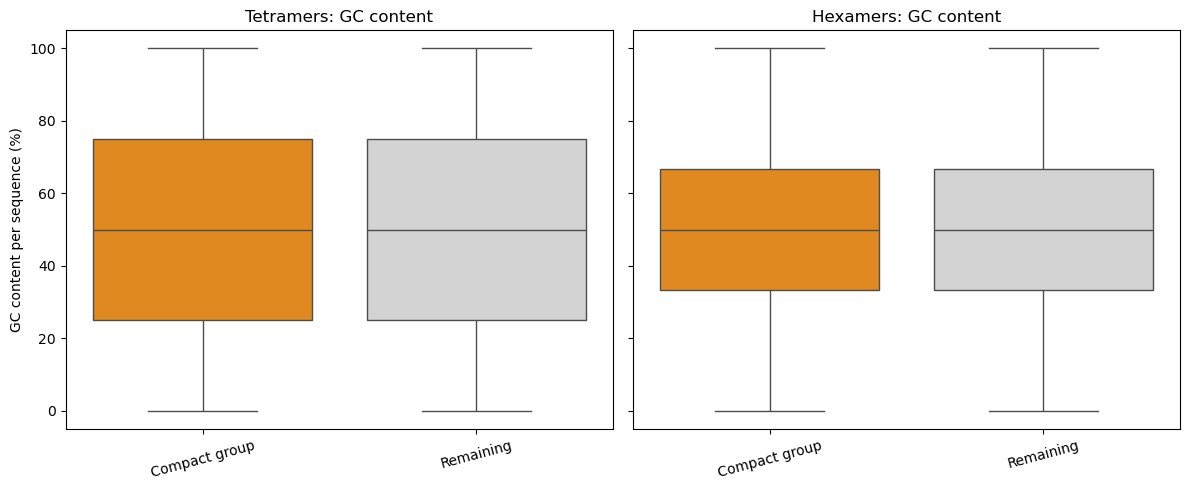

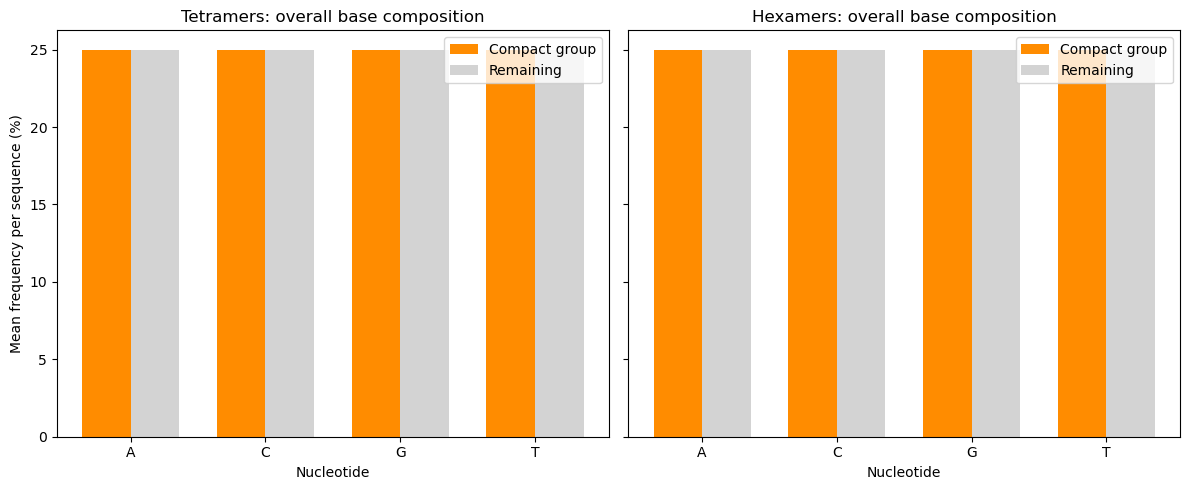

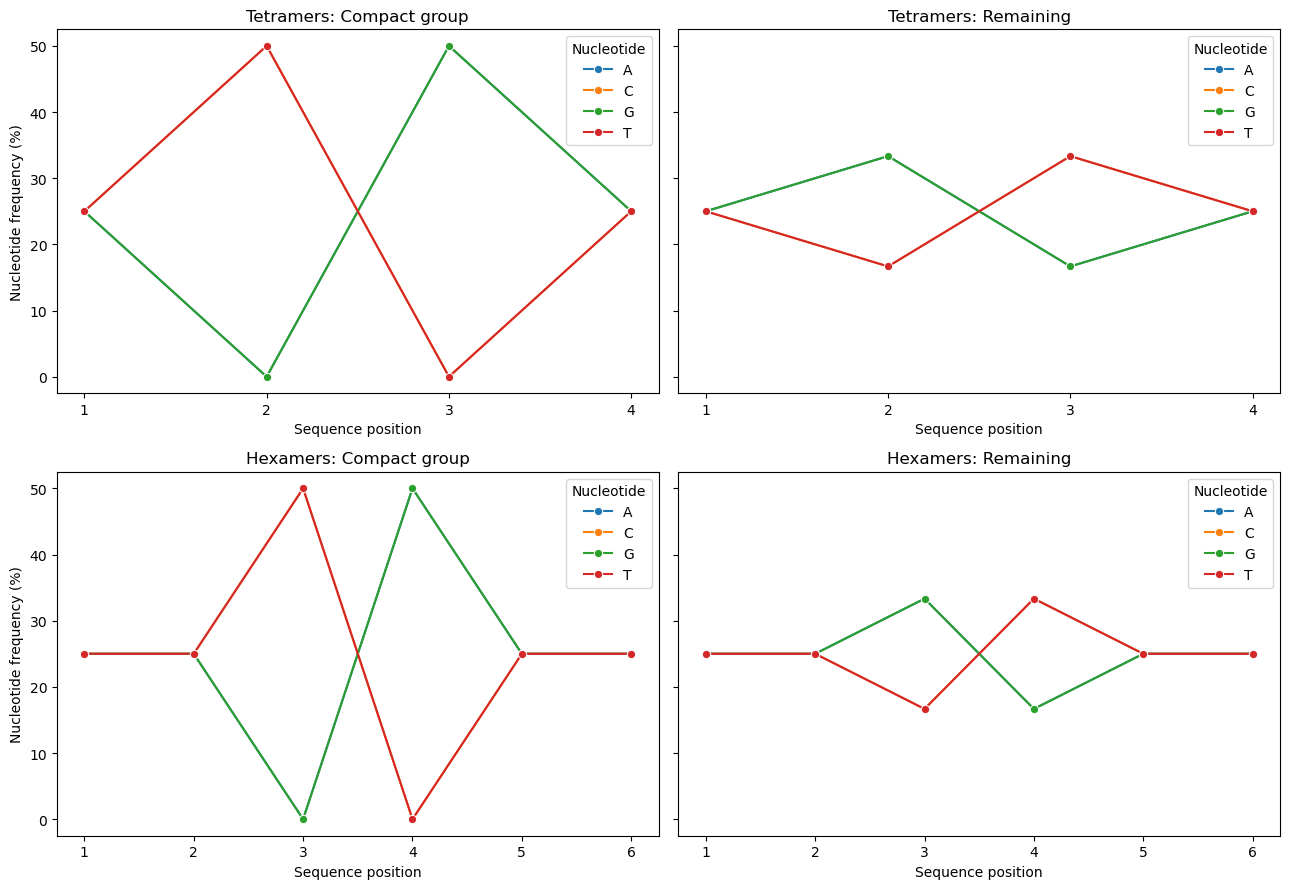

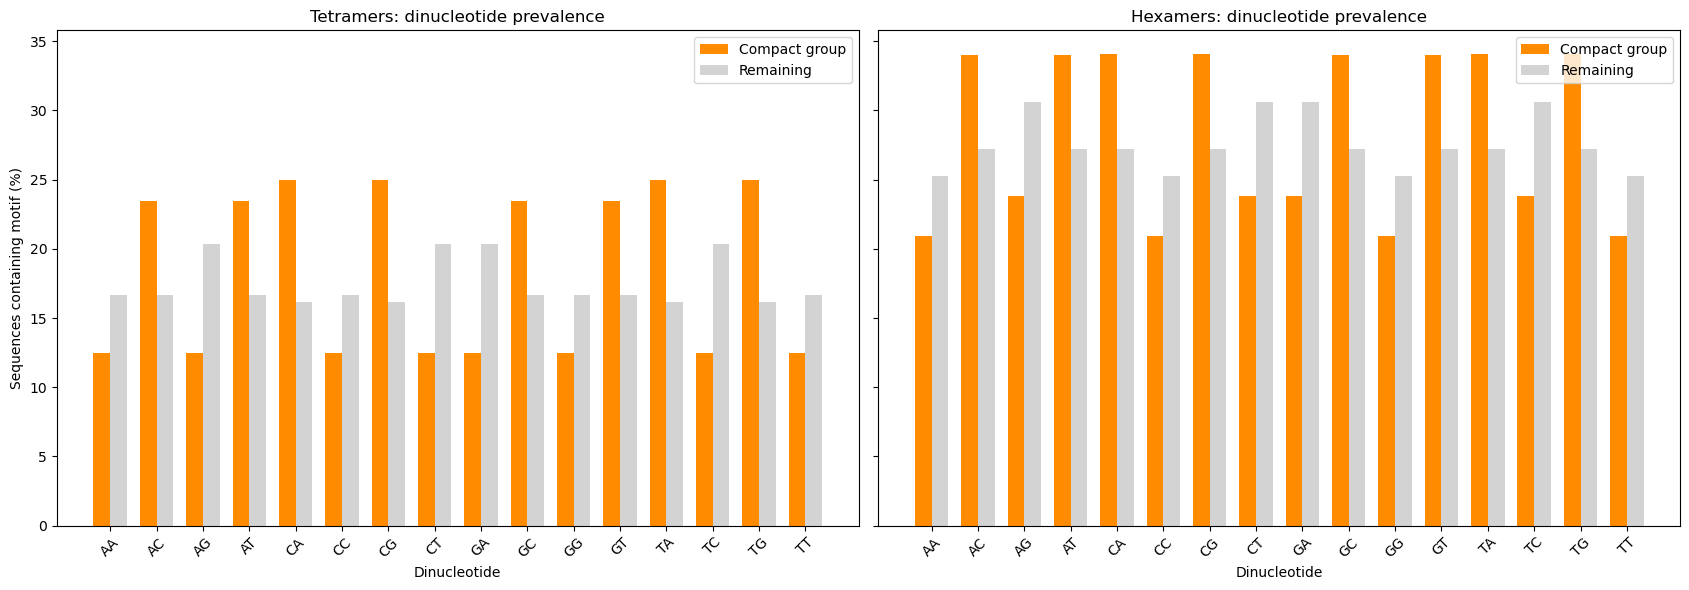

In [120]:
# GC-content distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
group_palette = {"Compact group": "darkorange", "Remaining": "lightgrey"}
for ax, dataset in zip(axes, ["Tetramers", "Hexamers"]):
    subset = sequence_characteristics[sequence_characteristics["Dataset"] == dataset]
    sns.boxplot(
        data=subset,
        x="Group",
        y="GC content (%)",
        order=group_order,
        palette=group_palette,
        showfliers=False,
        ax=ax
    )
    ax.set_title(f"{dataset}: GC content")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("GC content per sequence (%)")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(PLOT_DIR / "fce_compact_group_gc_content.png", dpi=300, bbox_inches="tight")
plt.show()

# Overall nucleotide composition
base_frequency_summary = (
    sequence_characteristics
    .groupby(["Dataset", "Group"])[[f"{base} (%)" for base in nucleotides]]
    .mean()
    .reset_index()
    .melt(id_vars=["Dataset", "Group"], var_name="Nucleotide", value_name="Frequency (%)")
)
base_frequency_summary["Nucleotide"] = base_frequency_summary["Nucleotide"].str.replace(" (%)", "", regex=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
bar_width = 0.36
for ax, dataset in zip(axes, ["Tetramers", "Hexamers"]):
    subset = base_frequency_summary[base_frequency_summary["Dataset"] == dataset]
    for offset, group in [(-bar_width / 2, "Compact group"), (bar_width / 2, "Remaining")]:
        values = (subset[subset["Group"] == group]
                  .set_index("Nucleotide").reindex(nucleotides)["Frequency (%)"])
        ax.bar(np.arange(len(nucleotides)) + offset, values, width=bar_width,
               color=group_palette[group], label=group)
    ax.set_xticks(np.arange(len(nucleotides)), nucleotides)
    ax.set_title(f"{dataset}: overall base composition")
    ax.set_xlabel("Nucleotide")
    ax.legend()
axes[0].set_ylabel("Mean frequency per sequence (%)")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(PLOT_DIR / "fce_compact_group_overall_nucleotide_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

# Nucleotide frequencies at each position
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for row, dataset in enumerate(["Tetramers", "Hexamers"]):
    for col, group in enumerate(group_order):
        ax = axes[row, col]
        subset = position_frequencies[
            (position_frequencies["Dataset"] == dataset)
            & (position_frequencies["Group"] == group)
        ]
        sns.lineplot(
            data=subset,
            x="Position",
            y="Frequency (%)",
            hue="Nucleotide",
            marker="o",
            ax=ax
        )
        ax.set_title(f"{dataset}: {group}")
        ax.set_xlabel("Sequence position")
        ax.set_ylabel("Nucleotide frequency (%)")
        ax.set_xticks(sorted(subset["Position"].unique()))
        ax.legend(title="Nucleotide")
fig.tight_layout()
fig.savefig(PLOT_DIR / "fce_compact_group_position_nucleotide_frequency.png", dpi=300, bbox_inches="tight")
plt.show()

# Per-sequence dinucleotide prevalence
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, dataset in zip(axes, ["Tetramers", "Hexamers"]):
    subset = dinucleotide_frequencies[dinucleotide_frequencies["Dataset"] == dataset]
    prevalence = subset.pivot(index="Dinucleotide", columns="Group", values="Frequency (%)").reindex(dinucleotides)
    x = np.arange(len(dinucleotides))
    ax.bar(x - bar_width / 2, prevalence["Compact group"], width=bar_width,
           color=group_palette["Compact group"], label="Compact group")
    ax.bar(x + bar_width / 2, prevalence["Remaining"], width=bar_width,
           color=group_palette["Remaining"], label="Remaining")
    ax.set_xticks(x, dinucleotides, rotation=45)
    ax.set_title(f"{dataset}: dinucleotide prevalence")
    ax.set_xlabel("Dinucleotide")
    ax.legend()
axes[0].set_ylabel("Sequences containing motif (%)")
axes[1].set_ylabel("")
fig.tight_layout()
fig.savefig(PLOT_DIR / "fce_compact_group_dinucleotide_prevalence.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.5. PCA of tetramer electrostatic descriptors

The five electrostatic descriptors (`e1`–`e5`) are included without filtering. The features are standardised before PCA, which is fitted separately to the 256 tetramers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.5038,0.5038
1,PC2,0.2599,0.7636
2,PC3,0.2364,1.0000
3,PC4,0.0000,1.0000
4,PC5,0.0000,1.0000


,Variance threshold,Number of components
0,80%,3
1,90%,3
2,95%,3


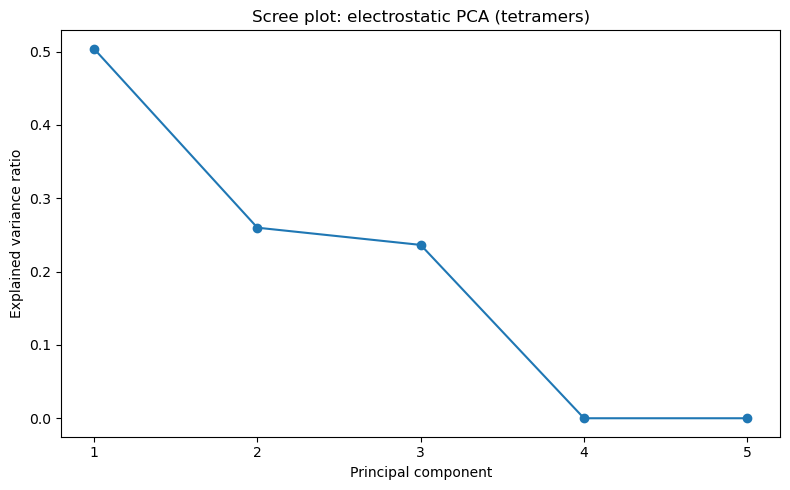

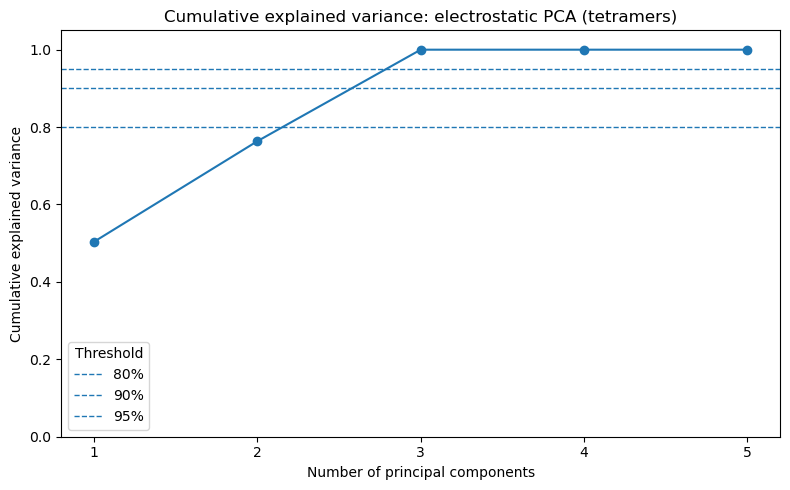

In [121]:
tetramer_electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]
tetramer_electrostatic_data = input_tetramer[tetramer_electrostatic_features]

# Standardise all features before PCA
tetramer_electrostatic_scaled = StandardScaler().fit_transform(tetramer_electrostatic_data)

# Fit PCA and summarise explained variance
pca_tetramer_electrostatic = PCA()
pca_tetramer_electrostatic.fit(tetramer_electrostatic_scaled)

cumulative_variance_tetramer_electrostatic = np.cumsum(pca_tetramer_electrostatic.explained_variance_ratio_)
pca_variance_tetramer_electrostatic = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(tetramer_electrostatic_features) + 1)
    ],
    "Explained variance ratio": pca_tetramer_electrostatic.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_tetramer_electrostatic
})
display(pca_variance_tetramer_electrostatic.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_tetramer_electrostatic = [0.80, 0.90, 0.95]
components_required_tetramer_electrostatic = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_tetramer_electrostatic],
    "Number of components": [
        np.searchsorted(cumulative_variance_tetramer_electrostatic, threshold) + 1
        for threshold in variance_thresholds_tetramer_electrostatic
    ]
})
display(components_required_tetramer_electrostatic)

# Scree plot
components_tetramer_electrostatic = np.arange(1, len(tetramer_electrostatic_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_tetramer_electrostatic,
    pca_tetramer_electrostatic.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: electrostatic PCA (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_tetramer_electrostatic)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_electrostatic_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_tetramer_electrostatic, cumulative_variance_tetramer_electrostatic, marker="o")
for threshold in variance_thresholds_tetramer_electrostatic:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: electrostatic PCA (tetramers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_tetramer_electrostatic)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_electrostatic_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one tetramer (256 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the electrostatic descriptors.

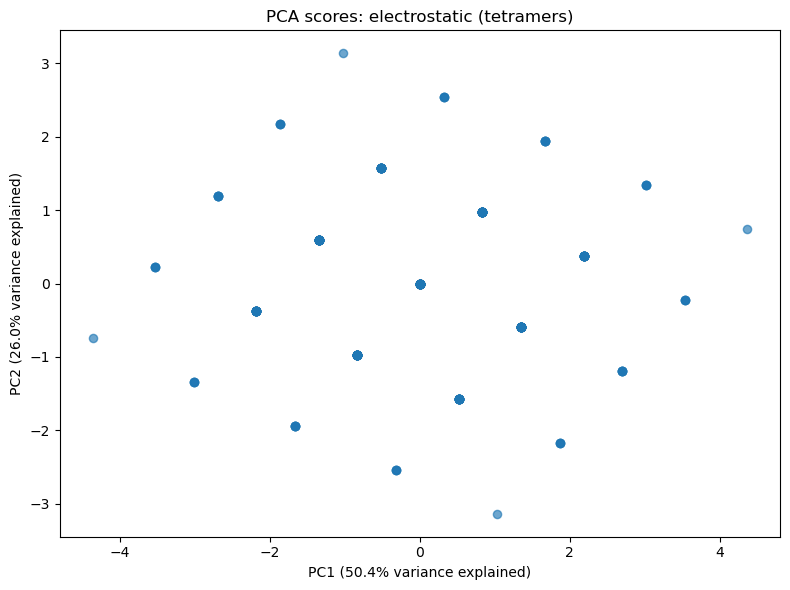

In [122]:
# Project the standardised features onto the fitted principal components
scores_tetramer_electrostatic = pca_tetramer_electrostatic.transform(tetramer_electrostatic_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_tetramer_electrostatic[:, 0],
    scores_tetramer_electrostatic[:, 1],
    s=35,
    alpha=0.65
)
ax.set_title("PCA scores: electrostatic (tetramers)")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_electrostatic.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_electrostatic.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_electrostatic_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original electrostatic descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5
e1,-0.733,-0.612,-0.302,0.0,-0.0
e2,0.852,-0.527,-0.000,0.0,0.0
e3,-0.852,0.527,0.000,0.0,0.0
e4,0.733,0.612,-0.302,0.0,-0.0
e5,-0.000,-0.000,1.002,0.0,-0.0


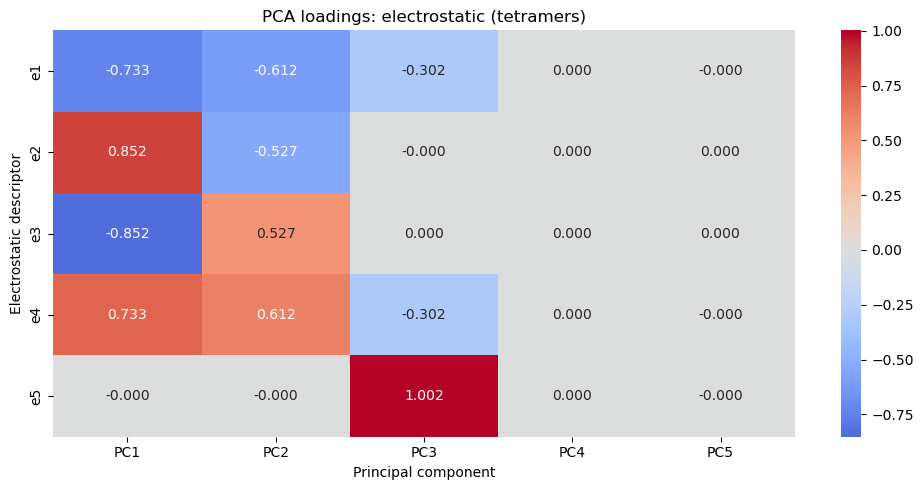

In [123]:
# Calculate loadings from the existing fitted PCA model
loadings_tetramer_electrostatic = pd.DataFrame(
    pca_tetramer_electrostatic.components_.T
    * np.sqrt(pca_tetramer_electrostatic.explained_variance_),
    index=tetramer_electrostatic_features,
    columns=[f"PC{i}" for i in range(1, len(tetramer_electrostatic_features) + 1)]
)
display(loadings_tetramer_electrostatic.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_tetramer_electrostatic,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: electrostatic (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Electrostatic descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_electrostatic_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the tetramer scores with vectors for the electrostatic descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

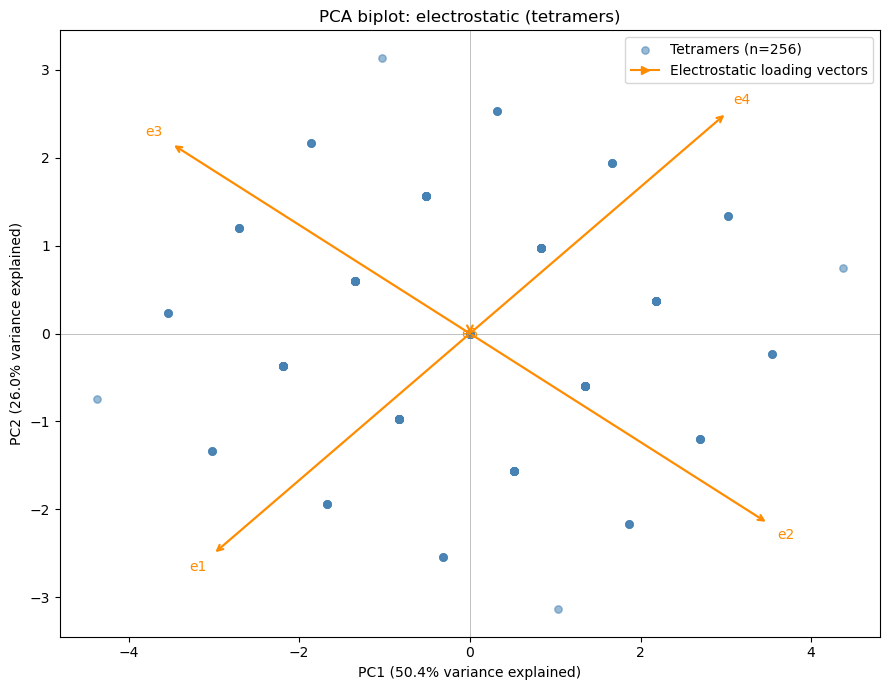

In [124]:
# Use the existing PCA scores and loading matrix
tetramer_electrostatic_scores_pc12 = scores_tetramer_electrostatic[:, :2]
tetramer_electrostatic_loading_coordinates = loadings_tetramer_electrostatic[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
tetramer_electrostatic_score_extent = np.abs(tetramer_electrostatic_scores_pc12).max()
tetramer_electrostatic_loading_extent = np.abs(tetramer_electrostatic_loading_coordinates).max()
tetramer_electrostatic_arrow_scale = 0.8 * tetramer_electrostatic_score_extent / tetramer_electrostatic_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    tetramer_electrostatic_scores_pc12[:, 0],
    tetramer_electrostatic_scores_pc12[:, 1],
    s=28,
    alpha=0.55,
    color="steelblue",
    label=f"Tetramers (n={len(tetramer_electrostatic_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    tetramer_electrostatic_features, tetramer_electrostatic_loading_coordinates
):
    end_x = loading_x * tetramer_electrostatic_arrow_scale
    end_y = loading_y * tetramer_electrostatic_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Electrostatic loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: electrostatic (tetramers)")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_electrostatic.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_electrostatic.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_electrostatic_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.6. PCA of hexamer electrostatic descriptors

The five electrostatic descriptors (`e1`–`e5`) are included without filtering. The features are standardised before PCA, which is fitted separately to the 4,096 hexamers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.5038,0.5038
1,PC2,0.2599,0.7636
2,PC3,0.2364,1.0000
3,PC4,0.0000,1.0000
4,PC5,0.0000,1.0000


,Variance threshold,Number of components
0,80%,3
1,90%,3
2,95%,3


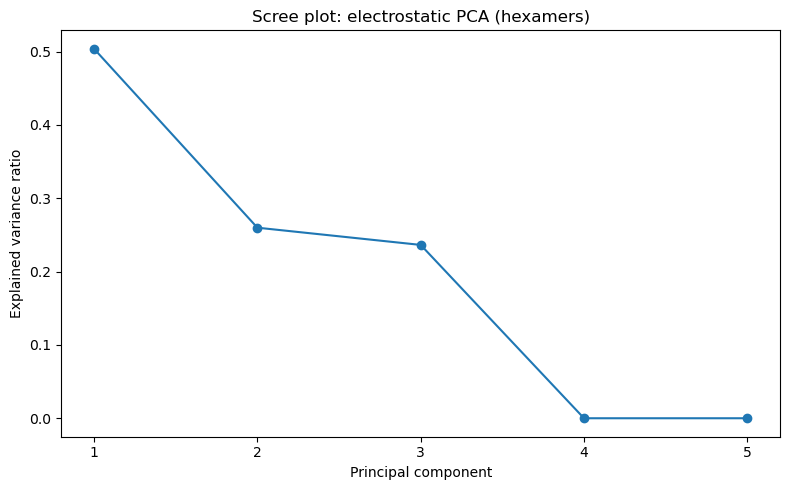

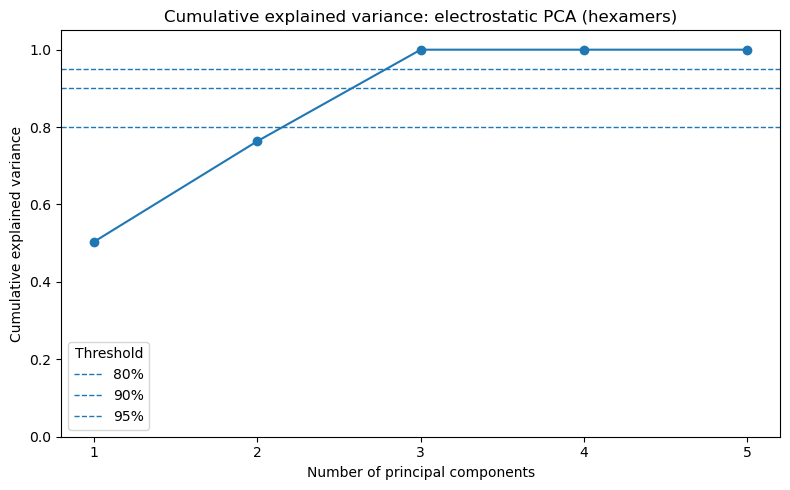

In [125]:
hexamer_electrostatic_features = ["e1", "e2", "e3", "e4", "e5"]
hexamer_electrostatic_data = input_hexamer[hexamer_electrostatic_features]

# Standardise all features before PCA
hexamer_electrostatic_scaled = StandardScaler().fit_transform(hexamer_electrostatic_data)

# Fit PCA and summarise explained variance
pca_hexamer_electrostatic = PCA()
pca_hexamer_electrostatic.fit(hexamer_electrostatic_scaled)

cumulative_variance_hexamer_electrostatic = np.cumsum(pca_hexamer_electrostatic.explained_variance_ratio_)
pca_variance_hexamer_electrostatic = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(hexamer_electrostatic_features) + 1)
    ],
    "Explained variance ratio": pca_hexamer_electrostatic.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_hexamer_electrostatic
})
display(pca_variance_hexamer_electrostatic.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_hexamer_electrostatic = [0.80, 0.90, 0.95]
components_required_hexamer_electrostatic = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_hexamer_electrostatic],
    "Number of components": [
        np.searchsorted(cumulative_variance_hexamer_electrostatic, threshold) + 1
        for threshold in variance_thresholds_hexamer_electrostatic
    ]
})
display(components_required_hexamer_electrostatic)

# Scree plot
components_hexamer_electrostatic = np.arange(1, len(hexamer_electrostatic_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_hexamer_electrostatic,
    pca_hexamer_electrostatic.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: electrostatic PCA (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_hexamer_electrostatic)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_electrostatic_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_hexamer_electrostatic, cumulative_variance_hexamer_electrostatic, marker="o")
for threshold in variance_thresholds_hexamer_electrostatic:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: electrostatic PCA (hexamers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_hexamer_electrostatic)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_electrostatic_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one hexamer (4,096 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the electrostatic descriptors.

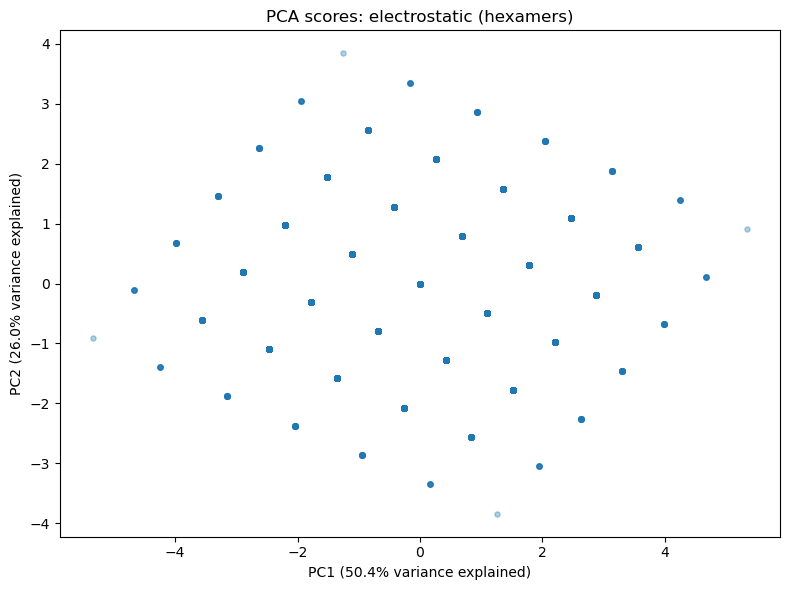

In [126]:
# Project the standardised features onto the fitted principal components
scores_hexamer_electrostatic = pca_hexamer_electrostatic.transform(hexamer_electrostatic_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_hexamer_electrostatic[:, 0],
    scores_hexamer_electrostatic[:, 1],
    s=14,
    alpha=0.35
)
ax.set_title("PCA scores: electrostatic (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_electrostatic.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_electrostatic.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_electrostatic_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original electrostatic descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5
e1,0.732,0.611,-0.302,-0.0,0.0
e2,-0.851,0.526,-0.000,0.0,0.0
e3,0.851,-0.526,0.000,0.0,0.0
e4,-0.732,-0.611,-0.302,-0.0,0.0
e5,-0.000,0.000,1.000,-0.0,0.0


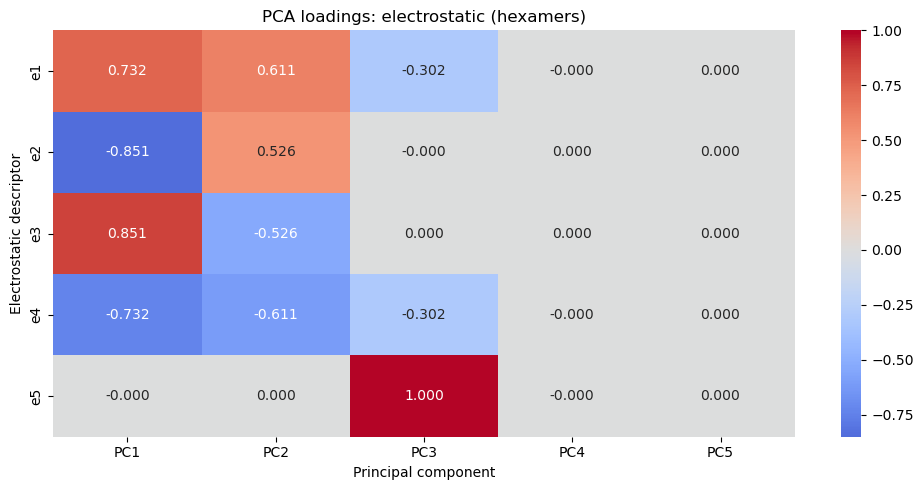

In [127]:
# Calculate loadings from the existing fitted PCA model
loadings_hexamer_electrostatic = pd.DataFrame(
    pca_hexamer_electrostatic.components_.T
    * np.sqrt(pca_hexamer_electrostatic.explained_variance_),
    index=hexamer_electrostatic_features,
    columns=[f"PC{i}" for i in range(1, len(hexamer_electrostatic_features) + 1)]
)
display(loadings_hexamer_electrostatic.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_hexamer_electrostatic,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: electrostatic (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Electrostatic descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_electrostatic_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the hexamer scores with vectors for the electrostatic descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

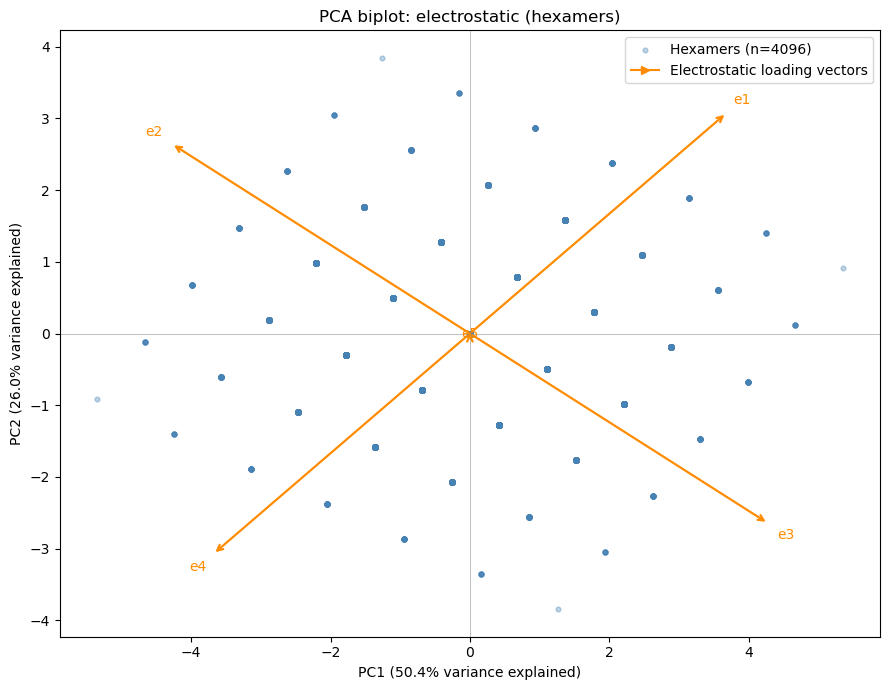

In [128]:
# Use the existing PCA scores and loading matrix
hexamer_electrostatic_scores_pc12 = scores_hexamer_electrostatic[:, :2]
hexamer_electrostatic_loading_coordinates = loadings_hexamer_electrostatic[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
hexamer_electrostatic_score_extent = np.abs(hexamer_electrostatic_scores_pc12).max()
hexamer_electrostatic_loading_extent = np.abs(hexamer_electrostatic_loading_coordinates).max()
hexamer_electrostatic_arrow_scale = 0.8 * hexamer_electrostatic_score_extent / hexamer_electrostatic_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    hexamer_electrostatic_scores_pc12[:, 0],
    hexamer_electrostatic_scores_pc12[:, 1],
    s=12,
    alpha=0.35,
    color="steelblue",
    label=f"Hexamers (n={len(hexamer_electrostatic_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    hexamer_electrostatic_features, hexamer_electrostatic_loading_coordinates
):
    end_x = loading_x * hexamer_electrostatic_arrow_scale
    end_y = loading_y * hexamer_electrostatic_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Electrostatic loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: electrostatic (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_electrostatic.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_electrostatic.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_electrostatic_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.7. PCA of tetramer ion-related descriptors

The six ion-related descriptors available for tetramers (`m1`–`m3` and `j1`–`j3`) are included. The features are standardised before PCA, which is fitted separately to the 256 tetramers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.3636,0.3636
1,PC2,0.2752,0.6387
2,PC3,0.1959,0.8346
3,PC4,0.0741,0.9087
4,PC5,0.0566,0.9654
5,PC6,0.0346,1.0000


,Variance threshold,Number of components
0,80%,3
1,90%,4
2,95%,5


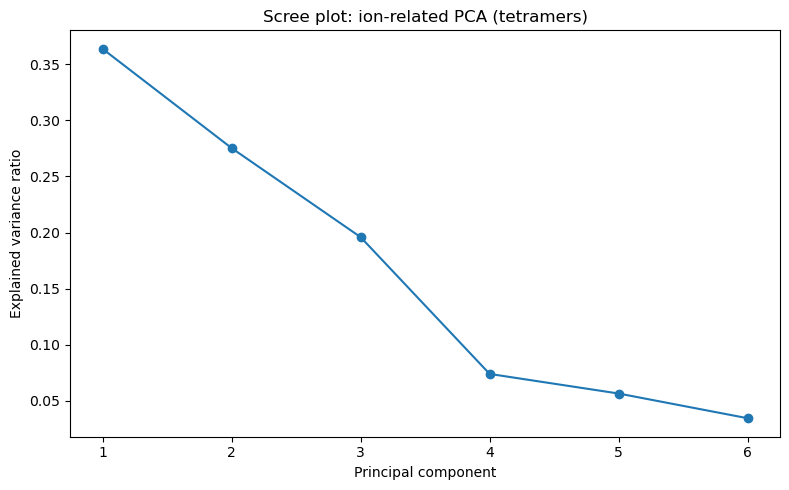

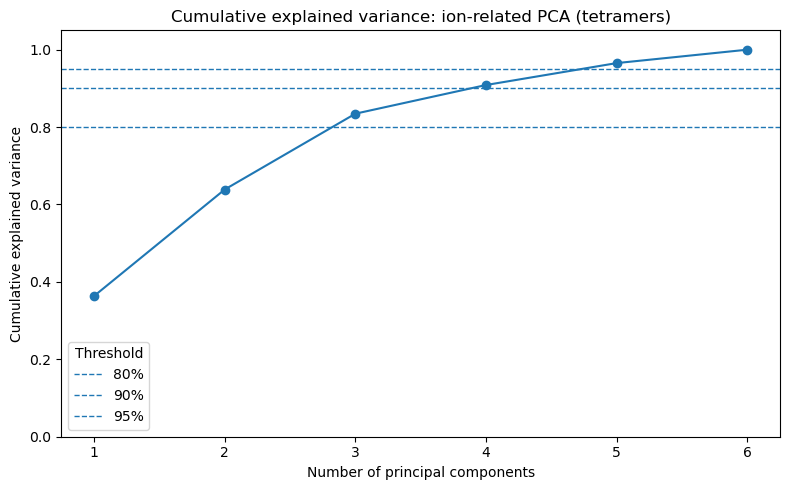

In [129]:
tetramer_ion_features = ["m1", "m2", "m3", "j1", "j2", "j3"]
tetramer_ion_data = input_tetramer[tetramer_ion_features]

# Standardise all features before PCA
tetramer_ion_scaled = StandardScaler().fit_transform(tetramer_ion_data)

# Fit PCA and summarise explained variance
pca_tetramer_ion = PCA()
pca_tetramer_ion.fit(tetramer_ion_scaled)

cumulative_variance_tetramer_ion = np.cumsum(pca_tetramer_ion.explained_variance_ratio_)
pca_variance_tetramer_ion = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(tetramer_ion_features) + 1)
    ],
    "Explained variance ratio": pca_tetramer_ion.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_tetramer_ion
})
display(pca_variance_tetramer_ion.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_tetramer_ion = [0.80, 0.90, 0.95]
components_required_tetramer_ion = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_tetramer_ion],
    "Number of components": [
        np.searchsorted(cumulative_variance_tetramer_ion, threshold) + 1
        for threshold in variance_thresholds_tetramer_ion
    ]
})
display(components_required_tetramer_ion)

# Scree plot
components_tetramer_ion = np.arange(1, len(tetramer_ion_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_tetramer_ion,
    pca_tetramer_ion.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: ion-related PCA (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_tetramer_ion)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_ion_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_tetramer_ion, cumulative_variance_tetramer_ion, marker="o")
for threshold in variance_thresholds_tetramer_ion:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: ion-related PCA (tetramers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_tetramer_ion)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_ion_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one tetramer (256 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the ion-related descriptors.

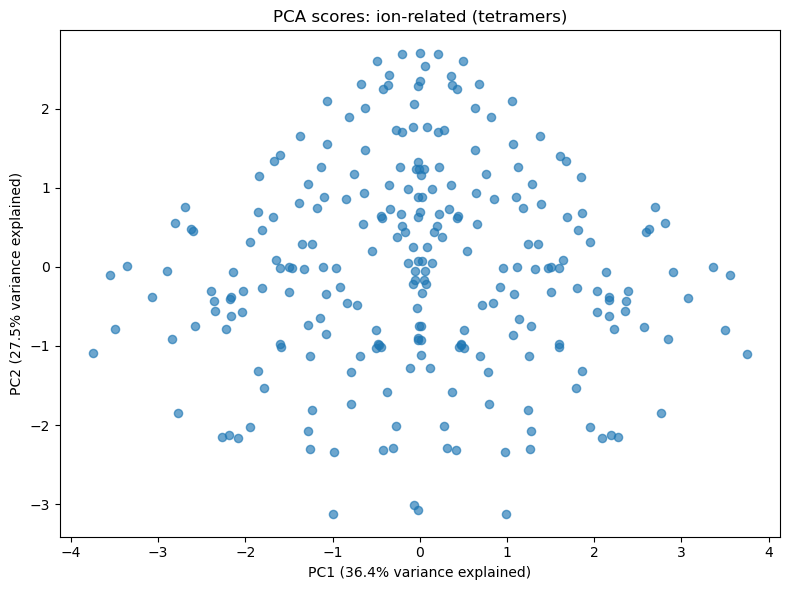

In [130]:
# Project the standardised features onto the fitted principal components
scores_tetramer_ion = pca_tetramer_ion.transform(tetramer_ion_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_tetramer_ion[:, 0],
    scores_tetramer_ion[:, 1],
    s=35,
    alpha=0.65
)
ax.set_title("PCA scores: ion-related (tetramers)")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_ion.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_ion.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_ion_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original ion-related descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5,PC6
m1,0.744,-0.038,0.546,-0.170,0.291,0.194
m2,0.000,0.907,-0.187,0.301,-0.000,0.238
m3,-0.743,-0.036,0.547,-0.171,-0.290,0.194
j1,-0.736,-0.109,-0.518,-0.274,0.294,0.142
j2,-0.001,-0.900,-0.108,0.383,-0.001,0.190
j3,0.737,-0.109,-0.517,-0.275,-0.293,0.142


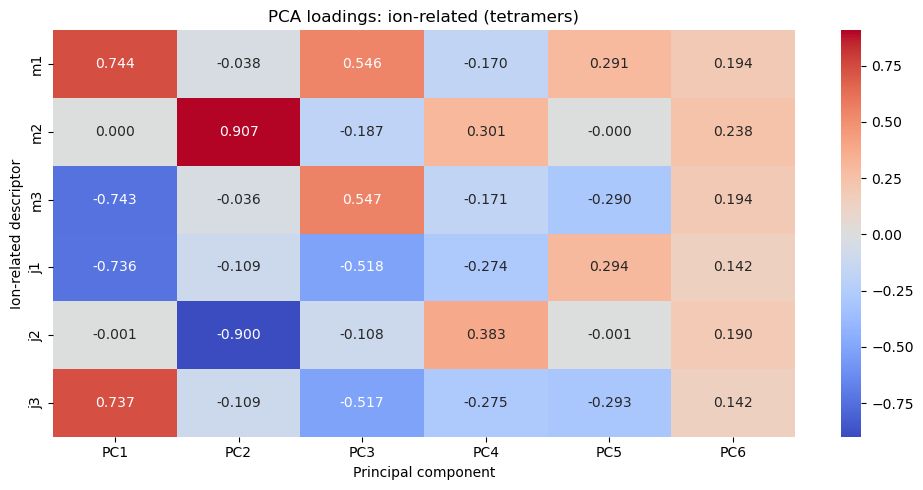

In [131]:
# Calculate loadings from the existing fitted PCA model
loadings_tetramer_ion = pd.DataFrame(
    pca_tetramer_ion.components_.T
    * np.sqrt(pca_tetramer_ion.explained_variance_),
    index=tetramer_ion_features,
    columns=[f"PC{i}" for i in range(1, len(tetramer_ion_features) + 1)]
)
display(loadings_tetramer_ion.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_tetramer_ion,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: ion-related (tetramers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Ion-related descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_ion_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the tetramer scores with vectors for the ion-related descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

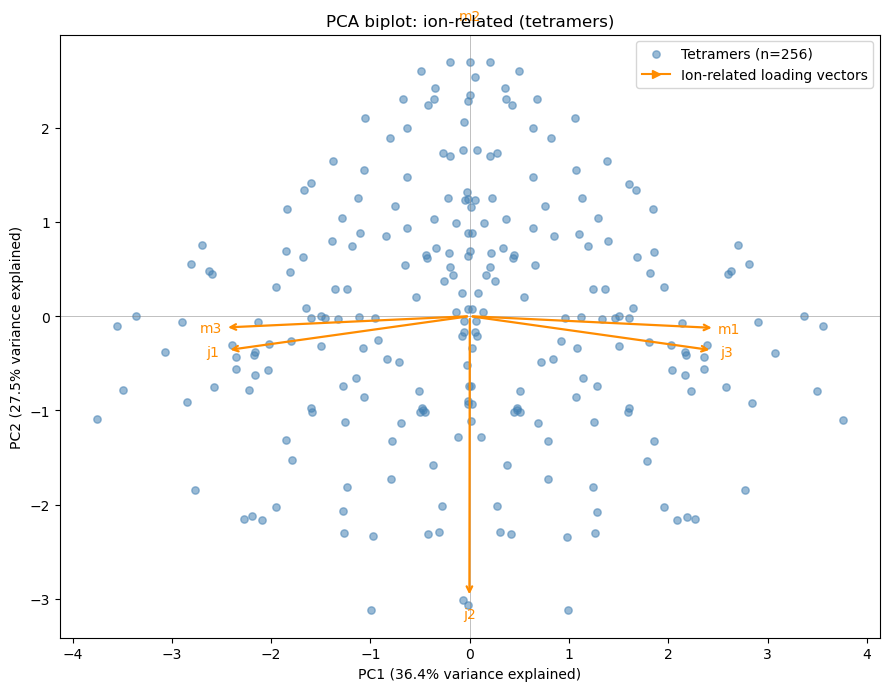

In [132]:
# Use the existing PCA scores and loading matrix
tetramer_ion_scores_pc12 = scores_tetramer_ion[:, :2]
tetramer_ion_loading_coordinates = loadings_tetramer_ion[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
tetramer_ion_score_extent = np.abs(tetramer_ion_scores_pc12).max()
tetramer_ion_loading_extent = np.abs(tetramer_ion_loading_coordinates).max()
tetramer_ion_arrow_scale = 0.8 * tetramer_ion_score_extent / tetramer_ion_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    tetramer_ion_scores_pc12[:, 0],
    tetramer_ion_scores_pc12[:, 1],
    s=28,
    alpha=0.55,
    color="steelblue",
    label=f"Tetramers (n={len(tetramer_ion_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    tetramer_ion_features, tetramer_ion_loading_coordinates
):
    end_x = loading_x * tetramer_ion_arrow_scale
    end_y = loading_y * tetramer_ion_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Ion-related loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: ion-related (tetramers)")
ax.set_xlabel(
    f"PC1 ({pca_tetramer_ion.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_tetramer_ion.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_tetramer_ion_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.8. PCA of hexamer ion-related descriptors

The ten ion-related descriptors available for hexamers (`m0`–`m4` and `j0`–`j4`) are included. The features are standardised before PCA, which is fitted separately to the 4,096 hexamers.

,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2220,0.2220
1,PC2,0.2150,0.4370
2,PC3,0.1493,0.5864
3,PC4,0.1205,0.7069
4,PC5,0.0967,0.8036
5,PC6,0.0500,0.8536
6,PC7,0.0471,0.9007
7,PC8,0.0423,0.9431
8,PC9,0.0340,0.9771
9,PC10,0.0229,1.0000


,Variance threshold,Number of components
0,80%,5
1,90%,7
2,95%,9


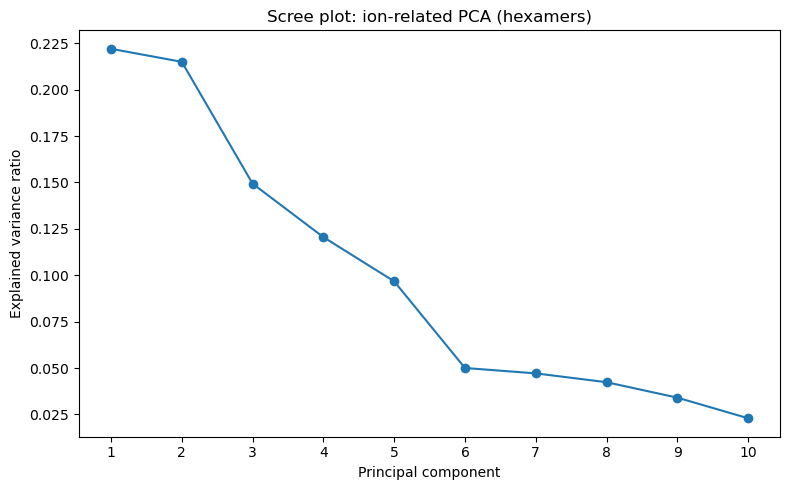

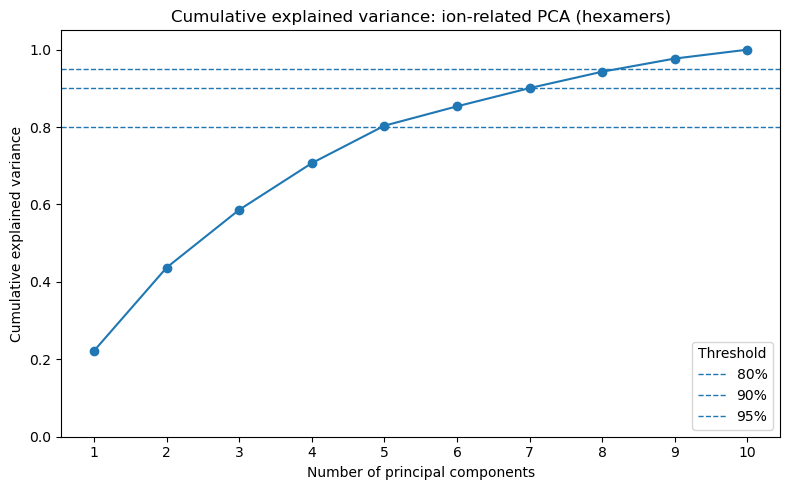

In [133]:
hexamer_ion_features = ["m0", "m1", "m2", "m3", "m4", "j0", "j1", "j2", "j3", "j4"]
hexamer_ion_data = input_hexamer[hexamer_ion_features]

# Standardise all features before PCA
hexamer_ion_scaled = StandardScaler().fit_transform(hexamer_ion_data)

# Fit PCA and summarise explained variance
pca_hexamer_ion = PCA()
pca_hexamer_ion.fit(hexamer_ion_scaled)

cumulative_variance_hexamer_ion = np.cumsum(pca_hexamer_ion.explained_variance_ratio_)
pca_variance_hexamer_ion = pd.DataFrame({
    "Principal component": [
        f"PC{i}" for i in range(1, len(hexamer_ion_features) + 1)
    ],
    "Explained variance ratio": pca_hexamer_ion.explained_variance_ratio_,
    "Cumulative explained variance": cumulative_variance_hexamer_ion
})
display(pca_variance_hexamer_ion.round(4))

# Count the components required to reach each variance threshold
variance_thresholds_hexamer_ion = [0.80, 0.90, 0.95]
components_required_hexamer_ion = pd.DataFrame({
    "Variance threshold": [f"{threshold:.0%}" for threshold in variance_thresholds_hexamer_ion],
    "Number of components": [
        np.searchsorted(cumulative_variance_hexamer_ion, threshold) + 1
        for threshold in variance_thresholds_hexamer_ion
    ]
})
display(components_required_hexamer_ion)

# Scree plot
components_hexamer_ion = np.arange(1, len(hexamer_ion_features) + 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    components_hexamer_ion,
    pca_hexamer_ion.explained_variance_ratio_,
    marker="o"
)
ax.set_title("Scree plot: ion-related PCA (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_xticks(components_hexamer_ion)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_ion_scree.png", dpi=300, bbox_inches="tight")
plt.show()

# Cumulative explained variance plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(components_hexamer_ion, cumulative_variance_hexamer_ion, marker="o")
for threshold in variance_thresholds_hexamer_ion:
    ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
ax.set_title("Cumulative explained variance: ion-related PCA (hexamers)")
ax.set_xlabel("Number of principal components")
ax.set_ylabel("Cumulative explained variance")
ax.set_xticks(components_hexamer_ion)
ax.set_ylim(0, 1.05)
ax.legend(title="Threshold")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_ion_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


#### Scores plot

Each point represents one hexamer (4,096 observations) in the PC1–PC2 score space. Clusters, gradients and outliers can reveal patterns in the ion-related descriptors.

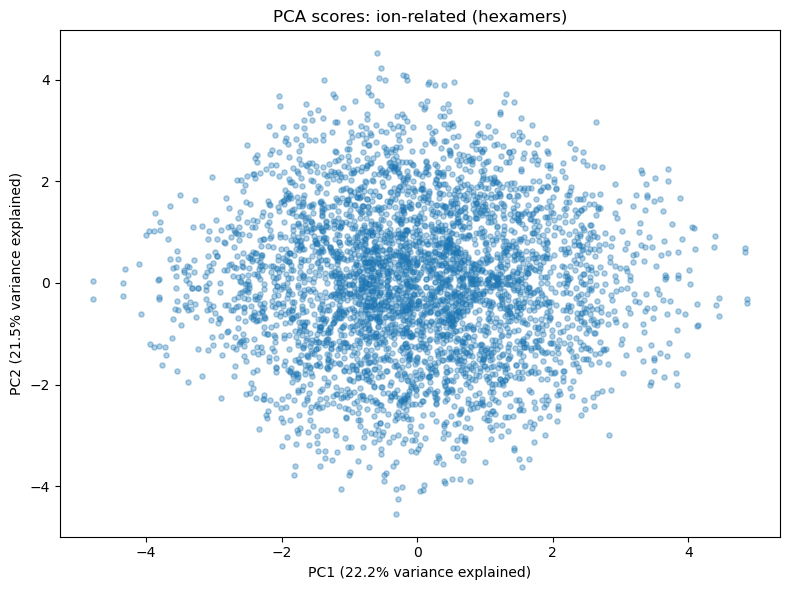

In [134]:
# Project the standardised features onto the fitted principal components
scores_hexamer_ion = pca_hexamer_ion.transform(hexamer_ion_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    scores_hexamer_ion[:, 0],
    scores_hexamer_ion[:, 1],
    s=14,
    alpha=0.35
)
ax.set_title("PCA scores: ion-related (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_ion.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_ion.explained_variance_ratio_[1]:.1%} variance explained)"
)
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_ion_scores.png", dpi=300, bbox_inches="tight")
plt.show()


#### Loadings

Loadings show the direction and strength of the relationship between each original ion-related descriptor and each principal component. Larger absolute values indicate stronger relationships.

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
m0,0.523,0.289,0.571,-0.164,-0.310,0.226,-0.071,0.271,-0.221,0.124
m1,-0.119,0.648,-0.307,0.540,-0.084,-0.239,-0.160,-0.086,-0.209,0.198
m2,-0.729,-0.023,-0.001,-0.407,-0.364,-0.007,0.323,-0.112,-0.001,0.232
m3,-0.080,-0.654,0.305,0.541,-0.085,0.236,-0.155,-0.105,0.207,0.198
m4,0.543,-0.256,-0.569,-0.167,-0.310,-0.214,-0.077,0.268,0.232,0.123
j0,-0.499,-0.357,-0.535,0.040,0.347,0.272,-0.007,0.317,-0.189,0.067
j1,0.137,-0.674,0.206,-0.429,0.308,-0.273,-0.239,-0.140,-0.194,0.130
j2,0.742,0.023,0.001,0.173,0.446,-0.006,0.441,-0.040,0.001,0.155
j3,0.096,0.682,-0.204,-0.429,0.306,0.274,-0.232,-0.159,0.189,0.129
j4,-0.523,0.327,0.535,0.040,0.347,-0.259,-0.013,0.316,0.203,0.066


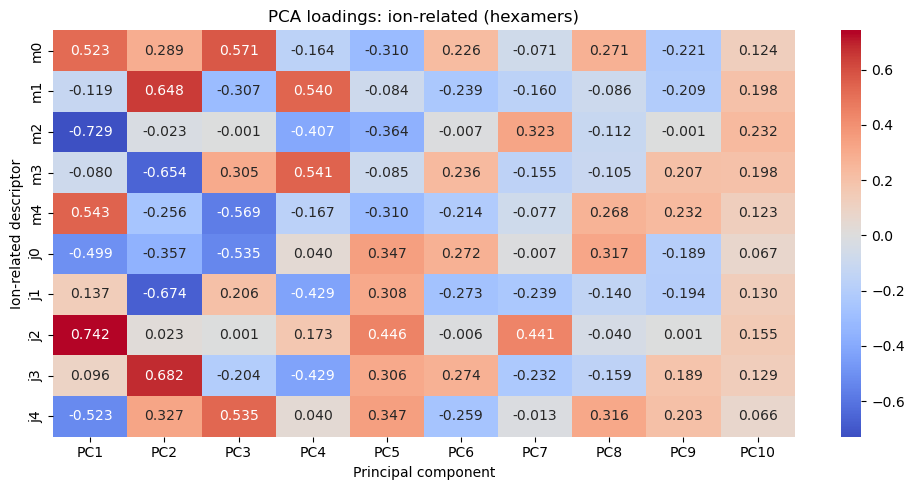

In [135]:
# Calculate loadings from the existing fitted PCA model
loadings_hexamer_ion = pd.DataFrame(
    pca_hexamer_ion.components_.T
    * np.sqrt(pca_hexamer_ion.explained_variance_),
    index=hexamer_ion_features,
    columns=[f"PC{i}" for i in range(1, len(hexamer_ion_features) + 1)]
)
display(loadings_hexamer_ion.round(3))

# Plot the loading matrix
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(
    loadings_hexamer_ion,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    ax=ax
)
ax.set_title("PCA loadings: ion-related (hexamers)")
ax.set_xlabel("Principal component")
ax.set_ylabel("Ion-related descriptor")
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_ion_loadings.png", dpi=300, bbox_inches="tight")
plt.show()


#### Biplot

The biplot overlays the hexamer scores with vectors for the ion-related descriptors. A common scale factor fits the arrows within 80% of the score range while preserving their directions and relative lengths.

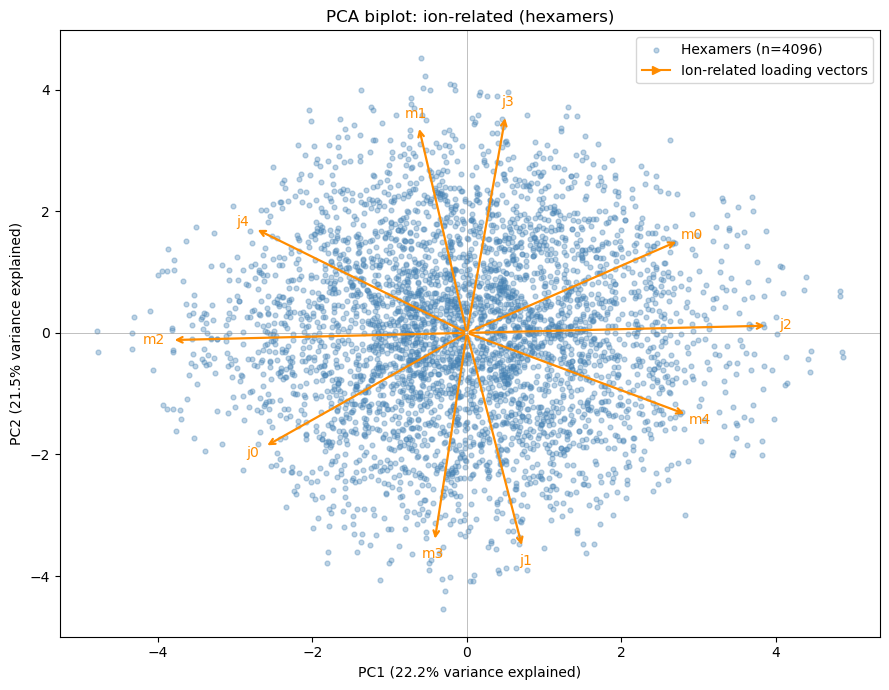

In [136]:
# Use the existing PCA scores and loading matrix
hexamer_ion_scores_pc12 = scores_hexamer_ion[:, :2]
hexamer_ion_loading_coordinates = loadings_hexamer_ion[["PC1", "PC2"]].to_numpy()

# Scale all loading vectors by one common factor for visibility
hexamer_ion_score_extent = np.abs(hexamer_ion_scores_pc12).max()
hexamer_ion_loading_extent = np.abs(hexamer_ion_loading_coordinates).max()
hexamer_ion_arrow_scale = 0.8 * hexamer_ion_score_extent / hexamer_ion_loading_extent

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    hexamer_ion_scores_pc12[:, 0],
    hexamer_ion_scores_pc12[:, 1],
    s=12,
    alpha=0.35,
    color="steelblue",
    label=f"Hexamers (n={len(hexamer_ion_scores_pc12)})"
)

for descriptor, (loading_x, loading_y) in zip(
    hexamer_ion_features, hexamer_ion_loading_coordinates
):
    end_x = loading_x * hexamer_ion_arrow_scale
    end_y = loading_y * hexamer_ion_arrow_scale
    ax.annotate(
        "",
        xy=(end_x, end_y),
        xytext=(0, 0),
        arrowprops={"arrowstyle": "->", "color": "darkorange", "lw": 1.6}
    )
    ax.text(end_x * 1.06, end_y * 1.06, descriptor,
            color="darkorange", fontsize=10, ha="center", va="center")

ax.plot([], [], color="darkorange", marker=">", label="Ion-related loading vectors")
ax.axhline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="grey", linewidth=0.7, alpha=0.5)
ax.set_title("PCA biplot: ion-related (hexamers)")
ax.set_xlabel(
    f"PC1 ({pca_hexamer_ion.explained_variance_ratio_[0]:.1%} variance explained)"
)
ax.set_ylabel(
    f"PC2 ({pca_hexamer_ion.explained_variance_ratio_[1]:.1%} variance explained)"
)
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_hexamer_ion_biplot.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Combined descriptor groups PCA

We combine the existing AVG, FCE, electrostatic and ion-related descriptor groups in three progressively larger feature sets. Tetramer and hexamer analyses are fitted separately. Each feature block is indexed by `SEQUENCE` and aligned before concatenation; sequence identifiers are not included as PCA features. The combined `input_tetramer` and `input_hexamer` tables are used because they contain the descriptor groups with sequence IDs already aligned.

For each configuration, the notebook reports explained and cumulative variance, the number of components needed for 80%, 90% and 95% variance, and the strongest absolute loadings on PC1 and PC2. It also saves a scree plot, cumulative variance plot, loading heatmap and PC1–PC2 scores plot in `notebooks/plots_EDA/`. Loading signs can reverse without changing the PCA, so interpretation focuses on their relative magnitude and pattern. These are statistical summaries, not biological conclusions.

In [137]:
# Reuse the feature lists defined in the individual descriptor PCA sections
tetramer_combined_groups = {
    "AVG": tetramer_avg_features,
    "FCE": tetramer_fce_features,
    "Electrostatic": tetramer_electrostatic_features,
    "Ion-related": tetramer_ion_features,
}
hexamer_combined_groups = {
    "AVG": hexamer_avg_features,
    "FCE": hexamer_fce_features,
    "Electrostatic": hexamer_electrostatic_features,
    "Ion-related": hexamer_ion_features,
}

combined_pca_configurations = {
    "AVG + FCE": ["AVG", "FCE"],
    "AVG + FCE + electrostatic": ["AVG", "FCE", "Electrostatic"],
    "AVG + FCE + electrostatic + ion-related": [
        "AVG", "FCE", "Electrostatic", "Ion-related"
    ],
}
combined_pca_slugs = {
    "AVG + FCE": "avg_fce",
    "AVG + FCE + electrostatic": "avg_fce_electrostatic",
    "AVG + FCE + electrostatic + ion-related": "avg_fce_electrostatic_ion",
}
combined_pca_thresholds = [0.80, 0.90, 0.95]
combined_pca_results = {}


def align_combined_features(data, groups, group_names, expected_features):
    """Select feature blocks by sequence ID and concatenate without changing source data."""
    if "SEQUENCE" not in data.columns:
        raise KeyError("The combined input table must contain a SEQUENCE column.")

    indexed_data = data.set_index("SEQUENCE")
    if not indexed_data.index.is_unique:
        raise ValueError("Sequence identifiers must be unique before alignment.")

    feature_blocks = []
    for group_name in group_names:
        feature_names = groups[group_name]
        missing_features = sorted(set(feature_names) - set(indexed_data.columns))
        if missing_features:
            raise KeyError(f"Missing {group_name} features: {missing_features}")
        feature_blocks.append(indexed_data.loc[:, feature_names].copy())

    combined = pd.concat(feature_blocks, axis=1, join="inner")
    if not combined.index.equals(indexed_data.index):
        raise ValueError("Descriptor groups do not contain the same sequence IDs.")
    if not combined.columns.is_unique:
        raise ValueError("The selected descriptor groups contain duplicate columns.")
    if combined.shape[1] != expected_features:
        raise ValueError(
            f"Expected {expected_features} features, found {combined.shape[1]}."
        )
    if combined.isna().any().any():
        raise ValueError("PCA input contains missing descriptor values.")
    return combined


def run_combined_pca(data, sequence_length, configuration, groups, group_names):
    """Scale, fit PCA, report summaries and save the four exploratory plots."""
    expected_counts = {
        "AVG + FCE": 27,
        "AVG + FCE + electrostatic": 32,
        "AVG + FCE + electrostatic + ion-related": 38 if sequence_length == "tetramer" else 42,
    }
    features = align_combined_features(
        data, groups, group_names, expected_counts[configuration]
    )
    scaled_features = StandardScaler().fit_transform(features)
    pca = PCA()
    scores = pca.fit_transform(scaled_features)

    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)
    component_names = [f"PC{i}" for i in range(1, len(explained_variance) + 1)]
    variance_table = pd.DataFrame({
        "Principal component": component_names,
        "Explained variance ratio": explained_variance,
        "Cumulative explained variance": cumulative_variance,
    })
    threshold_table = pd.DataFrame({
        "Variance threshold": [f"{threshold:.0%}" for threshold in combined_pca_thresholds],
        "Number of components": [
            int(np.searchsorted(cumulative_variance, threshold) + 1)
            for threshold in combined_pca_thresholds
        ],
    })

    loadings = pd.DataFrame(
        pca.components_.T * np.sqrt(pca.explained_variance_),
        index=features.columns,
        columns=component_names,
    )
    key_loading_rows = []
    for component in range(2):
        strongest_features = loadings.iloc[:, component].abs().nlargest(5).index
        for feature_name in strongest_features:
            key_loading_rows.append({
                "Component": f"PC{component + 1}",
                "Descriptor": feature_name,
                "Loading": loadings.loc[feature_name, f"PC{component + 1}"],
            })
    key_loadings = pd.DataFrame(key_loading_rows)

    config_slug = combined_pca_slugs[configuration]
    file_prefix = f"pca_{sequence_length}_{config_slug}"
    component_numbers = np.arange(1, len(component_names) + 1)

    # Scree plot
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(component_numbers, explained_variance, marker="o")
    ax.set_title(f"Scree plot: {configuration} PCA ({sequence_length}s)")
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Explained variance ratio")
    ax.set_xticks(component_numbers)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{file_prefix}_scree.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Cumulative explained variance plot with reference thresholds
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(component_numbers, cumulative_variance, marker="o")
    for threshold in combined_pca_thresholds:
        ax.axhline(threshold, linestyle="--", linewidth=1, label=f"{threshold:.0%}")
    ax.set_title(f"Cumulative explained variance: {configuration} PCA ({sequence_length}s)")
    ax.set_xlabel("Number of principal components")
    ax.set_ylabel("Cumulative explained variance")
    ax.set_xticks(component_numbers)
    ax.set_ylim(0, 1.05)
    ax.legend(title="Threshold")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{file_prefix}_cumulative_variance.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # Loading heatmap (all descriptors and all principal components)
    fig, ax = plt.subplots(
        figsize=(max(12, len(component_names) * 0.32), max(7, len(features.columns) * 0.30))
    )
    sns.heatmap(
        loadings.T,
        cmap="coolwarm",
        center=0,
        ax=ax,
        cbar_kws={"label": "Loading"},
    )
    ax.set_title(f"PCA loadings: {configuration} ({sequence_length}s)")
    ax.set_xlabel("Original descriptor")
    ax.set_ylabel("Principal component")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{file_prefix}_loadings.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    # PC1–PC2 score plot
    fig, ax = plt.subplots(figsize=(8, 6))
    point_size = 30 if sequence_length == "tetramer" else 12
    ax.scatter(scores[:, 0], scores[:, 1], s=point_size, alpha=0.55)
    ax.set_title(f"PCA scores: {configuration} ({sequence_length}s)")
    ax.set_xlabel(f"PC1 ({explained_variance[0]:.1%} variance explained)")
    ax.set_ylabel(f"PC2 ({explained_variance[1]:.1%} variance explained)")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{file_prefix}_scores.png", dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    result = {
        "features": list(features.columns),
        "pca": pca,
        "scores": scores,
        "variance_table": variance_table,
        "threshold_table": threshold_table,
        "loadings": loadings,
        "key_loadings": key_loadings,
    }
    combined_pca_results[(sequence_length, configuration)] = result

    print(f"{sequence_length.title()} | {configuration} | {len(features.columns)} features | {len(features)} sequences")
    display(variance_table.round(4))
    display(threshold_table)
    print("Five largest absolute loadings on PC1 and PC2:")
    display(key_loadings.round(3))
    print(f"Saved four plots with prefix: {file_prefix}")
    return result


### 10.1. AVG + FCE

This configuration combines the six AVG descriptors with the 21 independent upper-triangular FCE elements (27 features). The feature blocks are aligned by sequence ID and standardised together before PCA. Compare the variance thresholds and leading loadings below to assess how many components summarise this combined descriptor space. The score plots show the 256 tetramers and 4,096 hexamers on their first two components; any visible patterns are descriptive and do not establish biological groupings.

**Observed results.** The 80% / 90% / 95% thresholds require 6 / 9 / 12 PCs for tetramers and 7 / 9 / 13 for hexamers. PC1 and PC2 together explain 48.7% and 47.6%, respectively, so the two-dimensional scores plots show less than half of total variance. The largest absolute PC1 loadings are associated with `ROLL.ROLL`, `ROLL`, `TWIST.TWIST` and `SHIFT.SHIFT`; PC2 is strongest for `SHIFT.SLIDE`, `RISE.TILT`, `SHIFT.RISE` and `TILT`. In the scores plots, both lengths show several separated dense regions with points spread between them; these are patterns in the first two components only.


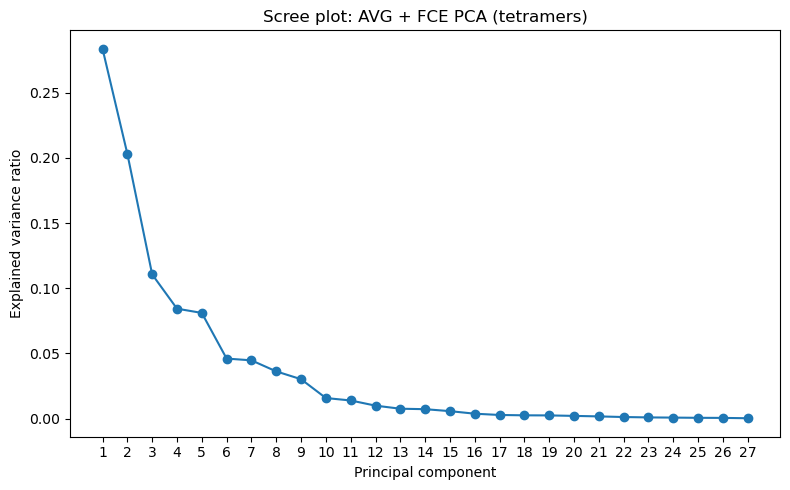

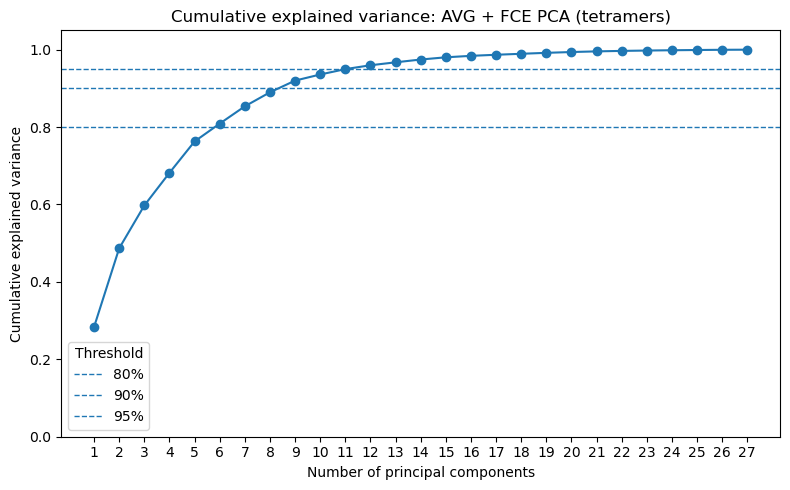

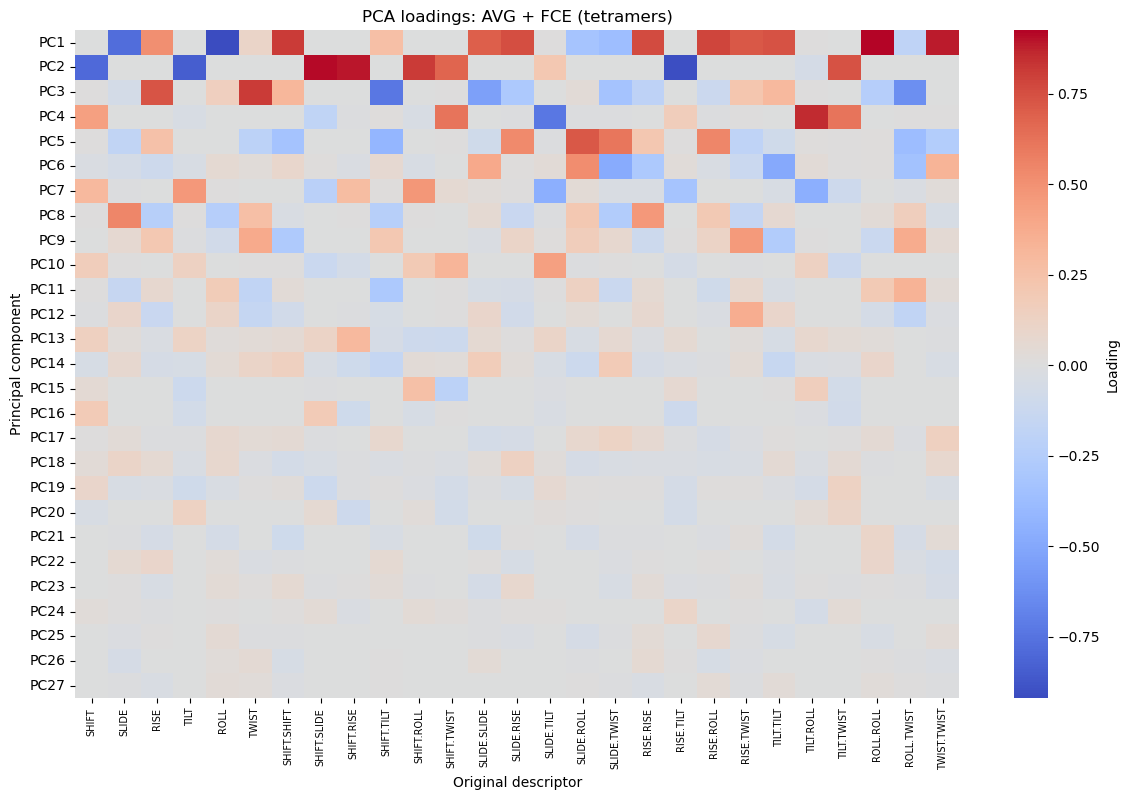

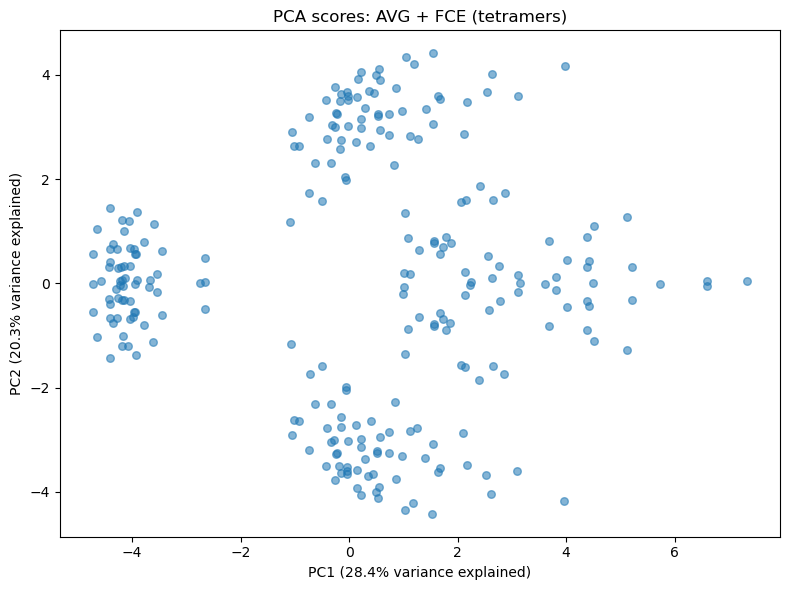

Tetramer | AVG + FCE | 27 features | 256 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2837,0.2837
1,PC2,0.2031,0.4868
2,PC3,0.1106,0.5975
3,PC4,0.0843,0.6818
4,PC5,0.0811,0.7629
5,PC6,0.0461,0.8089
6,PC7,0.0447,0.8537
7,PC8,0.0362,0.8899
8,PC9,0.0302,0.9201
9,PC10,0.0158,0.9359


,Variance threshold,Number of components
0,80%,6
1,90%,9
2,95%,12


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL.ROLL,0.924
1,PC1,ROLL,-0.919
2,PC1,TWIST.TWIST,0.885
3,PC1,SHIFT.SHIFT,0.811
4,PC1,RISE.ROLL,0.783
5,PC2,SHIFT.SLIDE,0.917
6,PC2,RISE.TILT,-0.910
7,PC2,SHIFT.RISE,0.895
8,PC2,TILT,-0.841
9,PC2,SHIFT.ROLL,0.810


Saved four plots with prefix: pca_tetramer_avg_fce


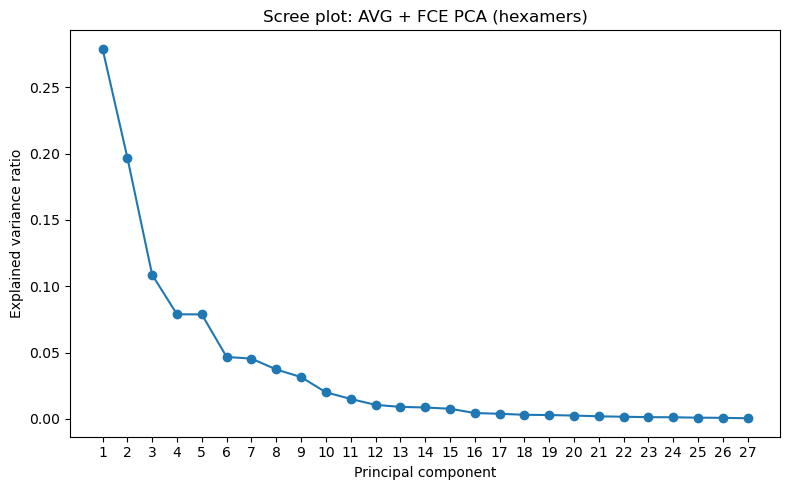

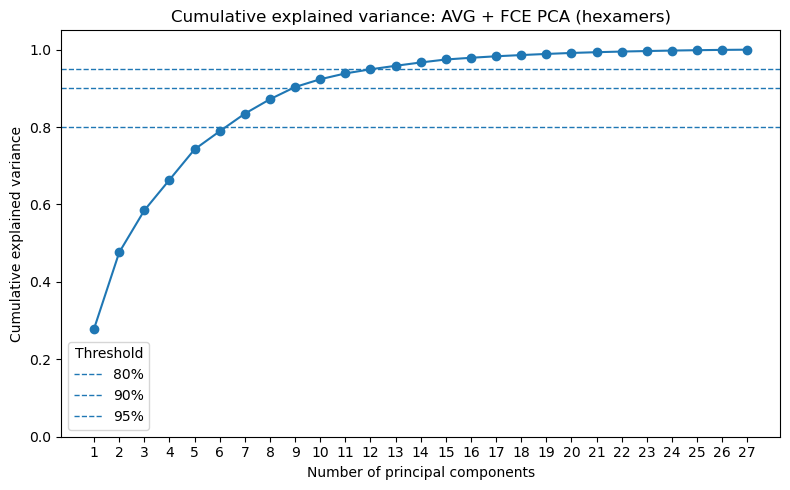

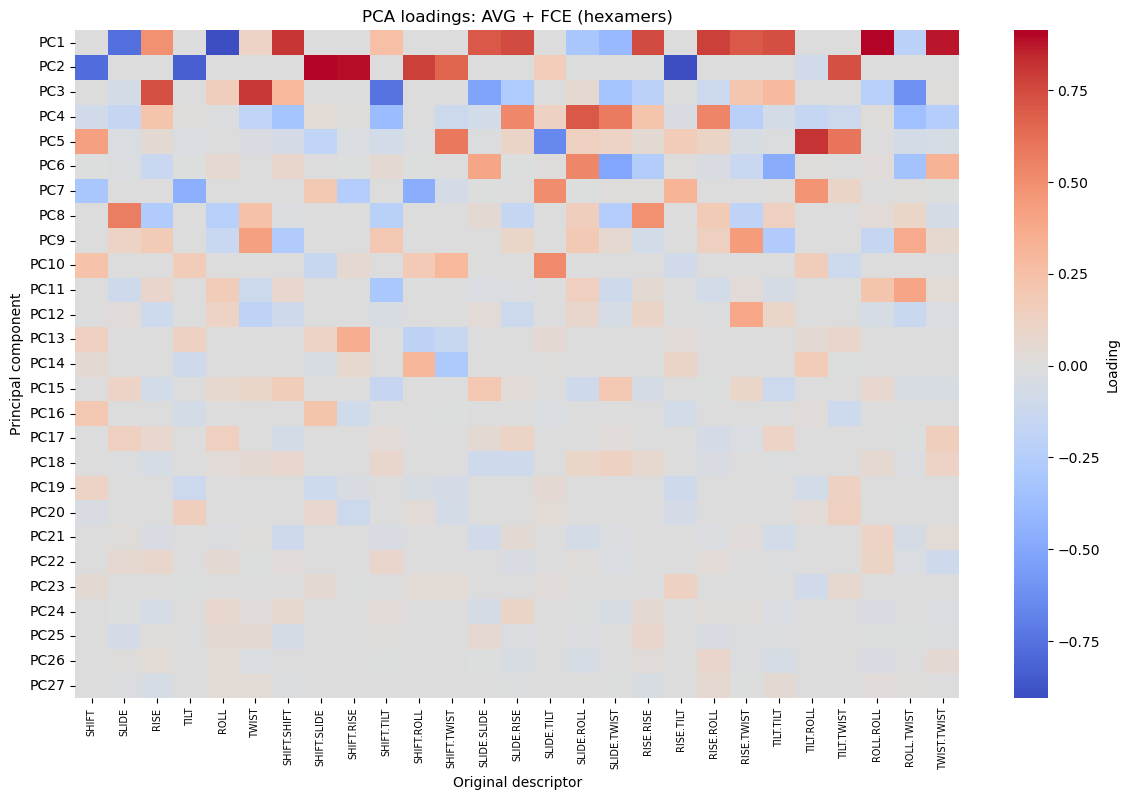

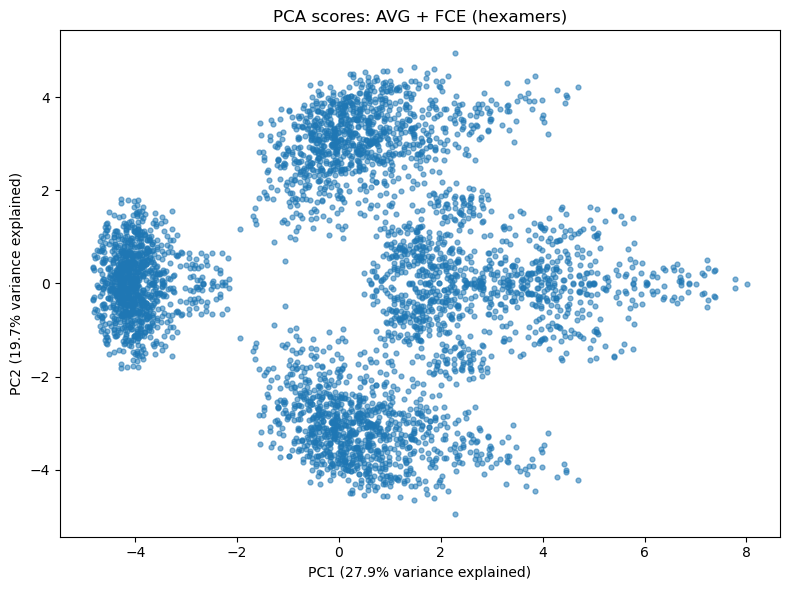

Hexamer | AVG + FCE | 27 features | 4096 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2791,0.2791
1,PC2,0.1971,0.4761
2,PC3,0.1086,0.5848
3,PC4,0.0789,0.6637
4,PC5,0.0788,0.7425
5,PC6,0.0467,0.7892
6,PC7,0.0455,0.8347
7,PC8,0.0373,0.8720
8,PC9,0.0315,0.9035
9,PC10,0.0201,0.9236


,Variance threshold,Number of components
0,80%,7
1,90%,9
2,95%,13


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL.ROLL,0.913
1,PC1,ROLL,-0.905
2,PC1,TWIST.TWIST,0.876
3,PC1,SHIFT.SHIFT,0.807
4,PC1,RISE.ROLL,0.780
5,PC2,SHIFT.SLIDE,0.907
6,PC2,RISE.TILT,-0.902
7,PC2,SHIFT.RISE,0.885
8,PC2,TILT,-0.829
9,PC2,SHIFT.ROLL,0.780


Saved four plots with prefix: pca_hexamer_avg_fce


{'features': ['SHIFT',
  'SLIDE',
  'RISE',
  'TILT',
  'ROLL',
  'TWIST',
  'SHIFT.SHIFT',
  'SHIFT.SLIDE',
  'SHIFT.RISE',
  'SHIFT.TILT',
  'SHIFT.ROLL',
  'SHIFT.TWIST',
  'SLIDE.SLIDE',
  'SLIDE.RISE',
  'SLIDE.TILT',
  'SLIDE.ROLL',
  'SLIDE.TWIST',
  'RISE.RISE',
  'RISE.TILT',
  'RISE.ROLL',
  'RISE.TWIST',
  'TILT.TILT',
  'TILT.ROLL',
  'TILT.TWIST',
  'ROLL.ROLL',
  'ROLL.TWIST',
  'TWIST.TWIST'],
 'pca': PCA(),
 'scores': array([[ 3.08729970e+00,  3.85175305e+00,  1.53468127e+00, ...,
         -5.01536247e-01, -1.54962829e-01, -1.50862655e-01],
        [ 2.62947450e+00,  3.34746171e+00,  9.12132594e-01, ...,
         -4.76855422e-01, -1.67573900e-01, -2.24817311e-01],
        [ 2.27390174e+00,  3.61384027e+00,  9.22565404e-01, ...,
         -3.40047425e-01, -1.91270450e-01, -1.32587919e-01],
        ...,
        [ 1.74517191e+00, -3.63625572e+00,  9.42627013e-01, ...,
         -3.44995069e-01,  1.13914095e-03, -1.25420895e-01],
        [ 1.79735893e+00, -3.36546208e+00,  8.

In [138]:
# Fit separate combined PCA models for tetramers and hexamers: AVG + FCE
run_combined_pca(
    input_tetramer,
    "tetramer",
    'AVG + FCE',
    tetramer_combined_groups,
    combined_pca_configurations['AVG + FCE'],
)
run_combined_pca(
    input_hexamer,
    "hexamer",
    'AVG + FCE',
    hexamer_combined_groups,
    combined_pca_configurations['AVG + FCE'],
)


### 10.2. AVG + FCE + electrostatic

This configuration adds the five electrostatic descriptors to AVG and FCE (32 features). It allows a statistical comparison with the 27-feature PCA above. The variance tables report the effective dimensionality at the requested thresholds, while the heatmaps and leading-loading tables show which descriptors contribute most strongly to individual components. PC1–PC2 plots show the sequence distributions in this reduced view.

**Observed results.** The 80% / 90% / 95% thresholds require 7 / 10 / 13 PCs for tetramers and 8 / 11 / 14 for hexamers. PC1 and PC2 explain 44.0% and 42.6%. The largest absolute loadings on PC1 and PC2 remain primarily among AVG and FCE features: PC1 includes `ROLL.ROLL`, `ROLL`, `TWIST.TWIST` and `SHIFT.SHIFT`, while PC2 includes `SHIFT.RISE`, `RISE.TILT`, `SHIFT.SLIDE` and `TILT.TWIST`. The electrostatic features do not enter the five largest absolute loadings on these first two PCs; this statement applies only to PC1–PC2. The score plots retain multiple dense regions, with their positions and spread changing after refitting the larger feature set.


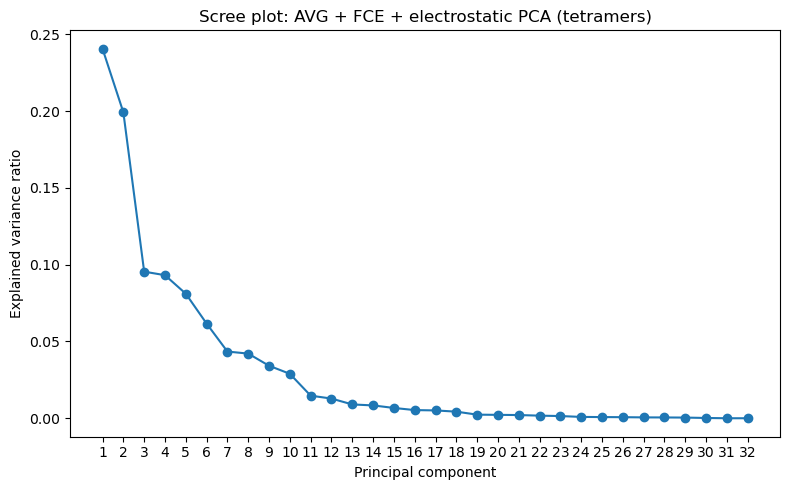

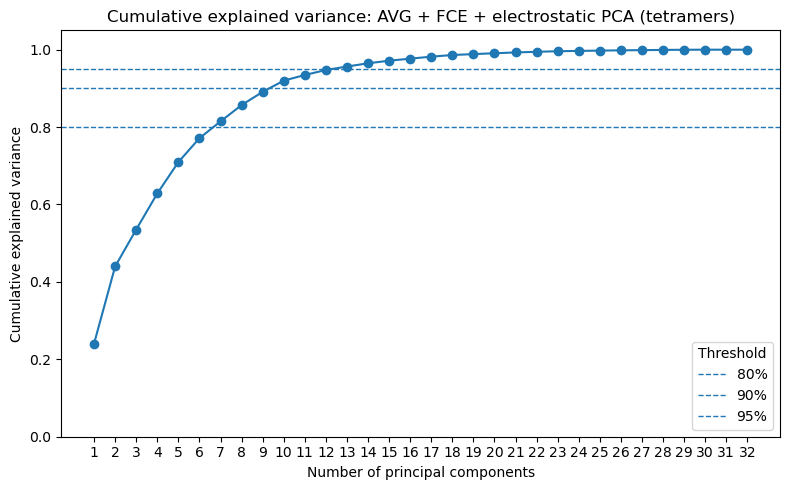

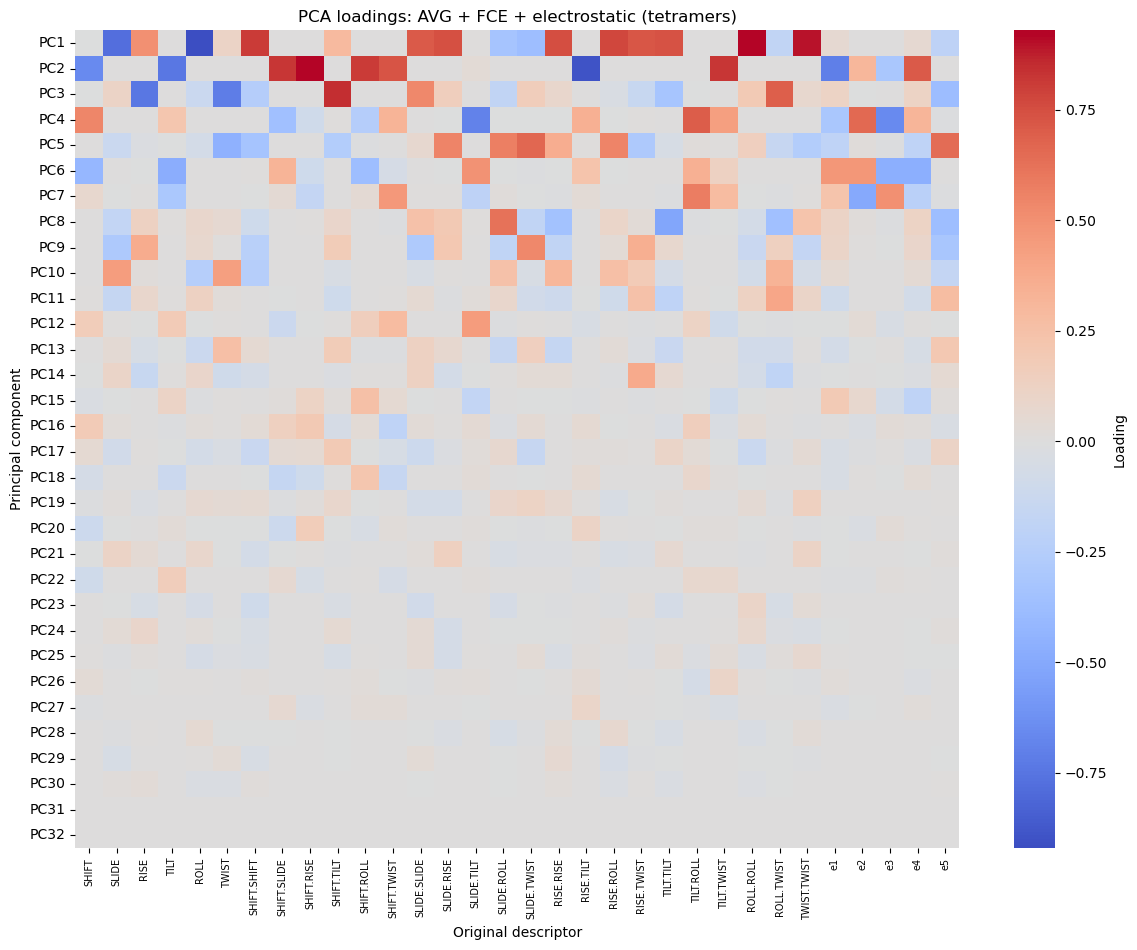

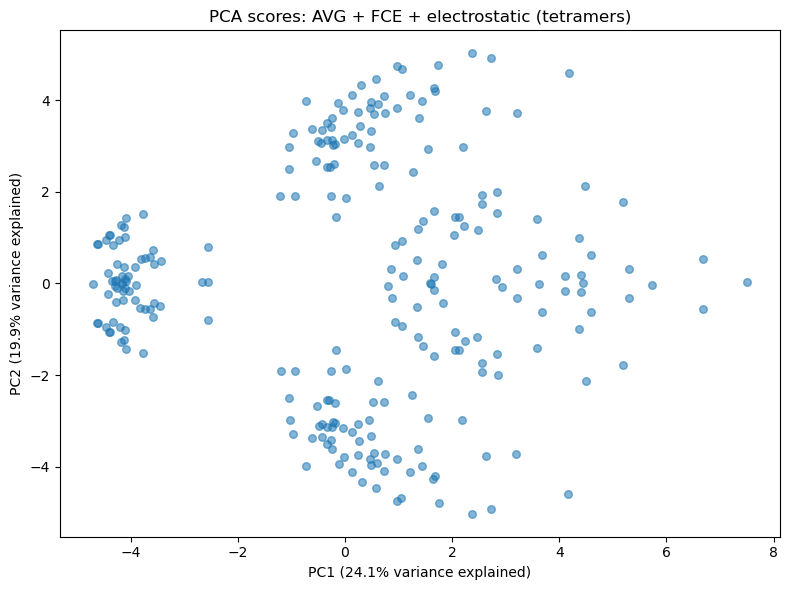

Tetramer | AVG + FCE + electrostatic | 32 features | 256 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2406,0.2406
1,PC2,0.1993,0.4399
2,PC3,0.0955,0.5353
3,PC4,0.0932,0.6285
4,PC5,0.0811,0.7096
5,PC6,0.0617,0.7713
6,PC7,0.0434,0.8147
7,PC8,0.0421,0.8568
8,PC9,0.0342,0.8910
9,PC10,0.0289,0.9199


,Variance threshold,Number of components
0,80%,7
1,90%,10
2,95%,13


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL.ROLL,0.922
1,PC1,ROLL,-0.920
2,PC1,TWIST.TWIST,0.893
3,PC1,SHIFT.SHIFT,0.812
4,PC1,SLIDE,-0.778
5,PC2,SHIFT.RISE,0.929
6,PC2,RISE.TILT,-0.892
7,PC2,SHIFT.SLIDE,0.828
8,PC2,TILT.TWIST,0.824
9,PC2,SHIFT.ROLL,0.812


Saved four plots with prefix: pca_tetramer_avg_fce_electrostatic


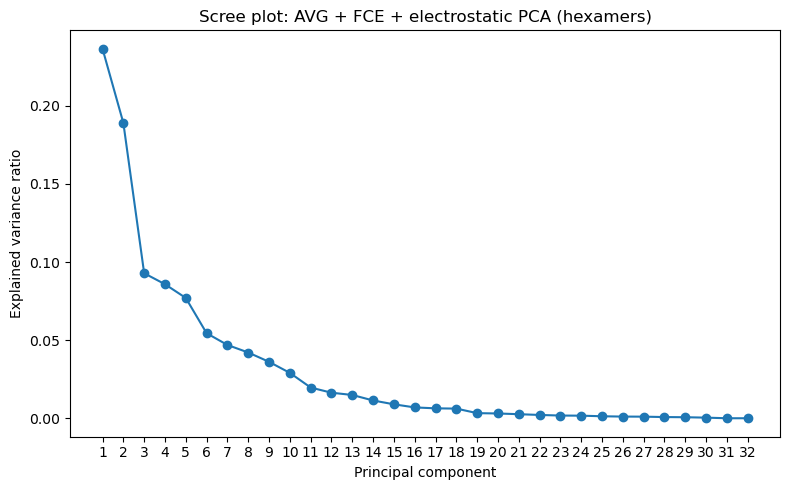

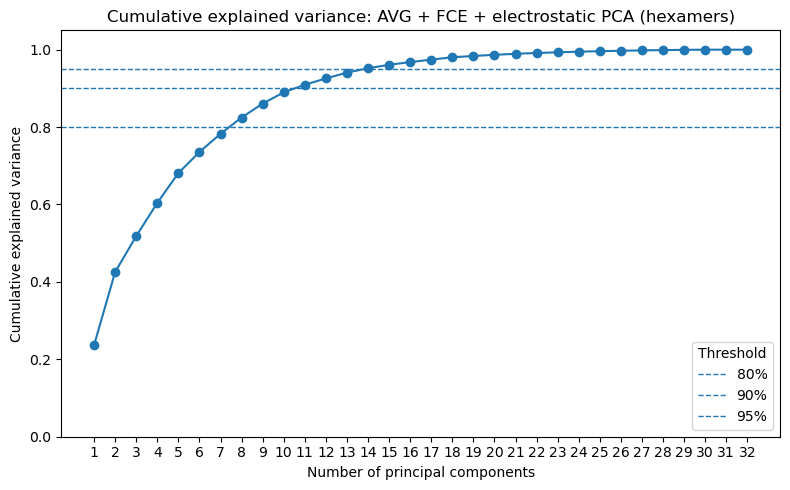

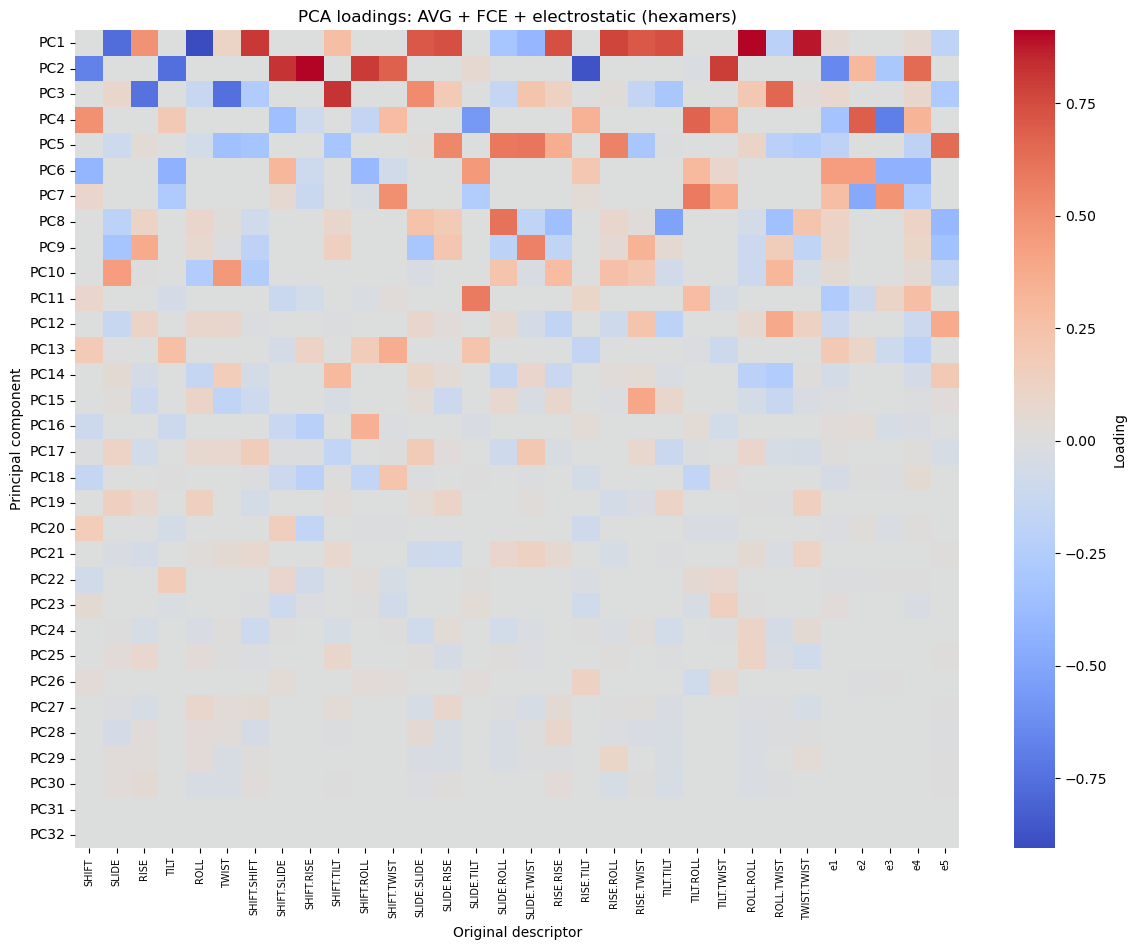

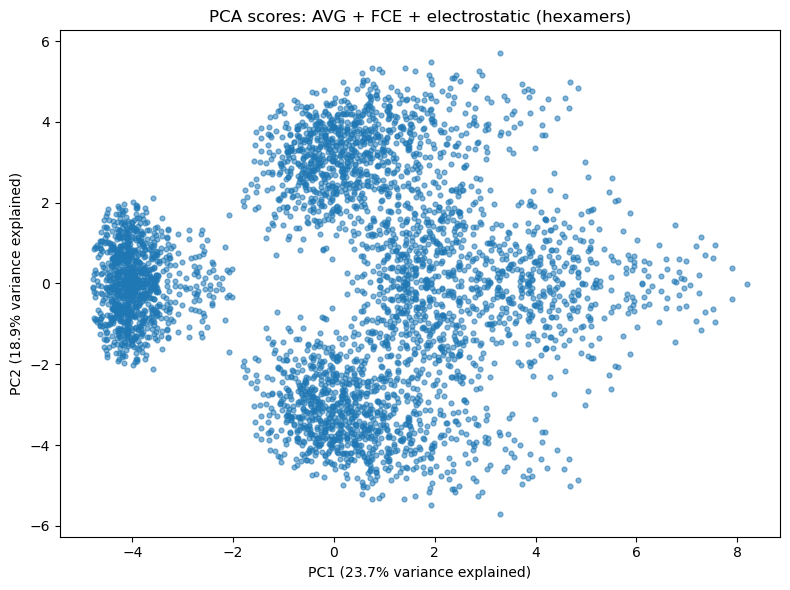

Hexamer | AVG + FCE + electrostatic | 32 features | 4096 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2365,0.2365
1,PC2,0.1890,0.4255
2,PC3,0.0928,0.5184
3,PC4,0.0858,0.6042
4,PC5,0.0770,0.6812
5,PC6,0.0544,0.7356
6,PC7,0.0469,0.7825
7,PC8,0.0421,0.8246
8,PC9,0.0361,0.8607
9,PC10,0.0290,0.8898


,Variance threshold,Number of components
0,80%,8
1,90%,11
2,95%,14


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL.ROLL,0.912
1,PC1,ROLL,-0.905
2,PC1,TWIST.TWIST,0.882
3,PC1,SHIFT.SHIFT,0.809
4,PC1,RISE.ROLL,0.771
5,PC2,SHIFT.RISE,0.905
6,PC2,RISE.TILT,-0.873
7,PC2,SHIFT.SLIDE,0.826
8,PC2,SHIFT.ROLL,0.800
9,PC2,TILT.TWIST,0.795


Saved four plots with prefix: pca_hexamer_avg_fce_electrostatic


{'features': ['SHIFT',
  'SLIDE',
  'RISE',
  'TILT',
  'ROLL',
  'TWIST',
  'SHIFT.SHIFT',
  'SHIFT.SLIDE',
  'SHIFT.RISE',
  'SHIFT.TILT',
  'SHIFT.ROLL',
  'SHIFT.TWIST',
  'SLIDE.SLIDE',
  'SLIDE.RISE',
  'SLIDE.TILT',
  'SLIDE.ROLL',
  'SLIDE.TWIST',
  'RISE.RISE',
  'RISE.TILT',
  'RISE.ROLL',
  'RISE.TWIST',
  'TILT.TILT',
  'TILT.ROLL',
  'TILT.TWIST',
  'ROLL.ROLL',
  'ROLL.TWIST',
  'TWIST.TWIST',
  'e1',
  'e2',
  'e3',
  'e4',
  'e5'],
 'pca': PCA(),
 'scores': array([[ 3.29183126e+00,  5.69456256e+00, -7.16889819e-01, ...,
          1.04401532e-01, -5.36103651e-15,  5.75468839e-14],
        [ 2.77083629e+00,  4.81618889e+00, -2.85103624e-01, ...,
          2.16204007e-01, -8.81759200e-16, -3.05088003e-14],
        [ 2.41431588e+00,  5.16071846e+00, -3.12907768e-01, ...,
          9.17538635e-02, -1.63007554e-15,  3.79709112e-15],
        ...,
        [ 1.88564013e+00, -5.15045333e+00, -3.46139922e-01, ...,
          1.03549867e-01,  6.71251992e-16, -6.23722011e-14],
      

In [139]:
# Fit separate combined PCA models for tetramers and hexamers: AVG + FCE + electrostatic
run_combined_pca(
    input_tetramer,
    "tetramer",
    'AVG + FCE + electrostatic',
    tetramer_combined_groups,
    combined_pca_configurations['AVG + FCE + electrostatic'],
)
run_combined_pca(
    input_hexamer,
    "hexamer",
    'AVG + FCE + electrostatic',
    hexamer_combined_groups,
    combined_pca_configurations['AVG + FCE + electrostatic'],
)


### 10.3. AVG + FCE + electrostatic + ion-related

This configuration adds the ion-related descriptors to the preceding 32-feature set: six for tetramers (38 features total) and ten for hexamers (42 total). The two sequence lengths use their own feature lists and separately fitted scalers and PCA models. Compare threshold counts, leading loading magnitudes and score distributions with the smaller configurations. These comparisons describe covariance structure only and do not assign biological meaning to individual descriptors.

**Observed results.** The 80% / 90% / 95% thresholds require 8 / 11 / 15 PCs for tetramers and 10 / 15 / 20 for hexamers. PC1 and PC2 explain 40.9% and 36.1%. Their five largest absolute loadings are still AVG/FCE descriptors: PC1 is strongest for `ROLL`, `ROLL.ROLL`, `TWIST.TWIST` and `SHIFT.SHIFT`; PC2 for `RISE.TILT`, `SHIFT.RISE`, `SHIFT.SLIDE` and `SHIFT.ROLL`. The score plots show multiple dense regions and broader connecting spreads, especially for hexamers. Since the first two PCs represent a smaller share of variance in this configuration, the plots are a limited view of the full descriptor space.


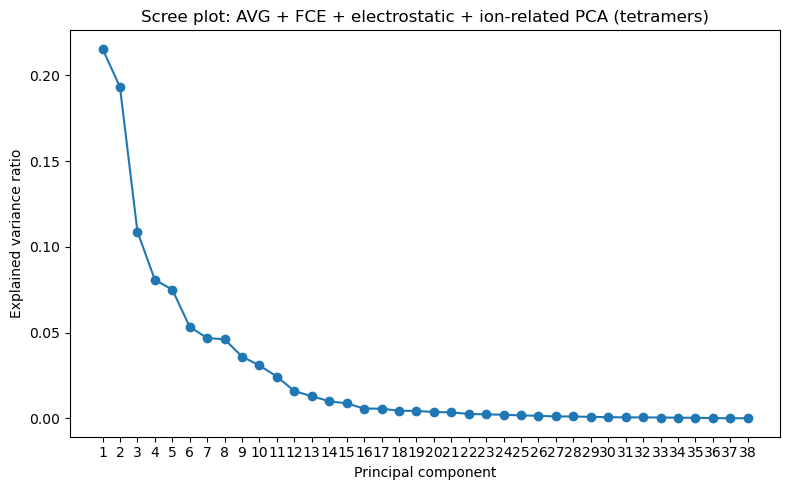

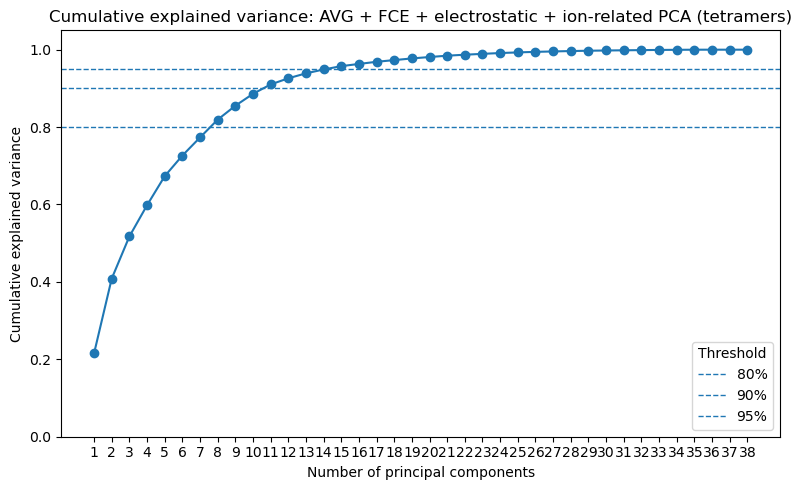

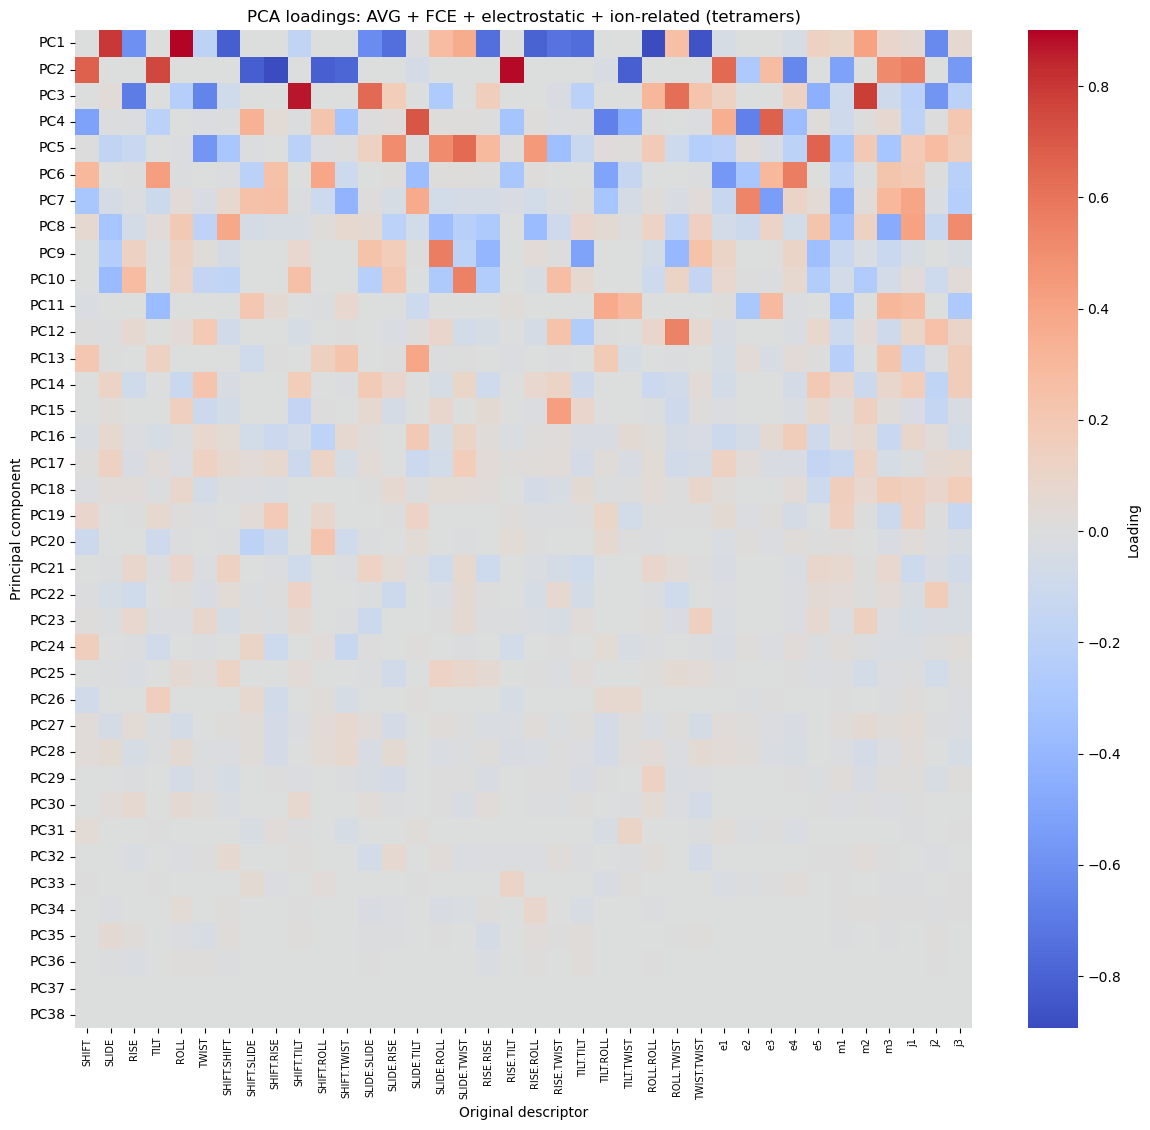

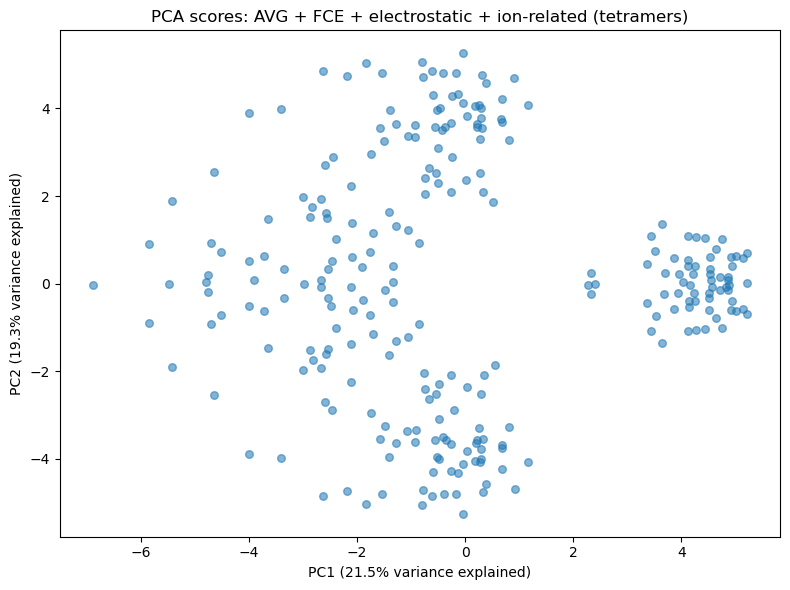

Tetramer | AVG + FCE + electrostatic + ion-related | 38 features | 256 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.2154,0.2154
1,PC2,0.1931,0.4085
2,PC3,0.1089,0.5174
3,PC4,0.0807,0.5981
4,PC5,0.0750,0.6731
5,PC6,0.0533,0.7264
6,PC7,0.0468,0.7731
7,PC8,0.0460,0.8192
8,PC9,0.0359,0.8551
9,PC10,0.0308,0.8859


,Variance threshold,Number of components
0,80%,8
1,90%,11
2,95%,15


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL,0.900
1,PC1,ROLL.ROLL,-0.893
2,PC1,TWIST.TWIST,-0.862
3,PC1,SHIFT.SHIFT,-0.817
4,PC1,RISE.ROLL,-0.796
5,PC2,RISE.TILT,0.892
6,PC2,SHIFT.RISE,-0.887
7,PC2,SHIFT.SLIDE,-0.821
8,PC2,SHIFT.ROLL,-0.813
9,PC2,TILT.TWIST,-0.813


Saved four plots with prefix: pca_tetramer_avg_fce_electrostatic_ion


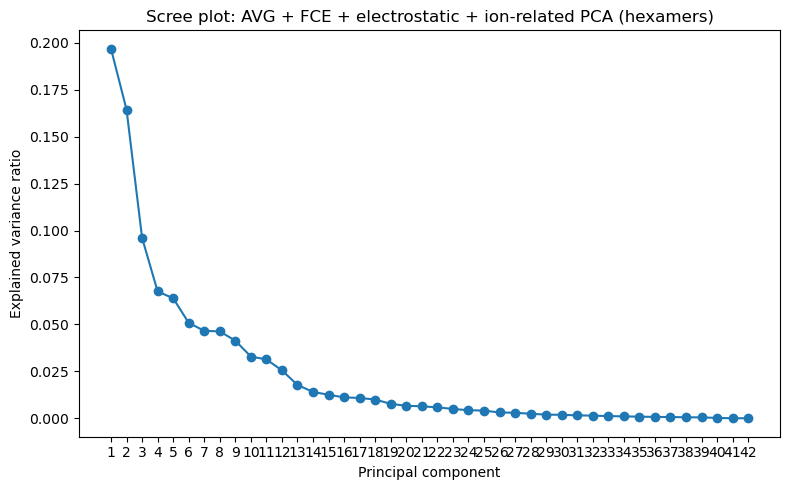

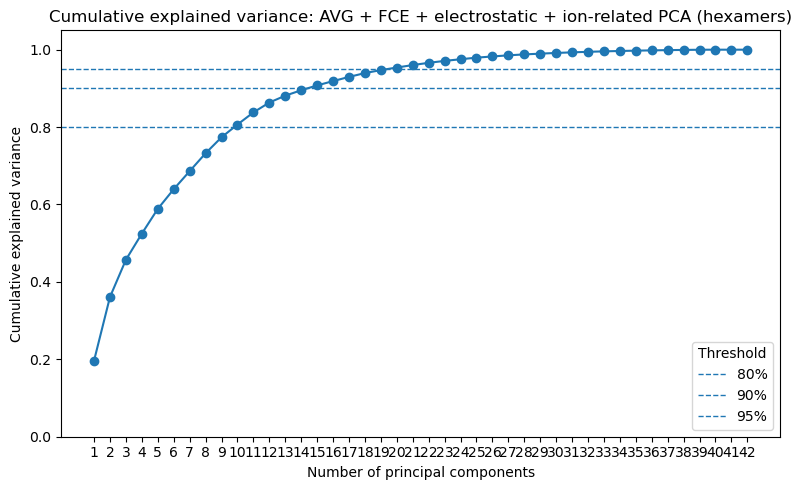

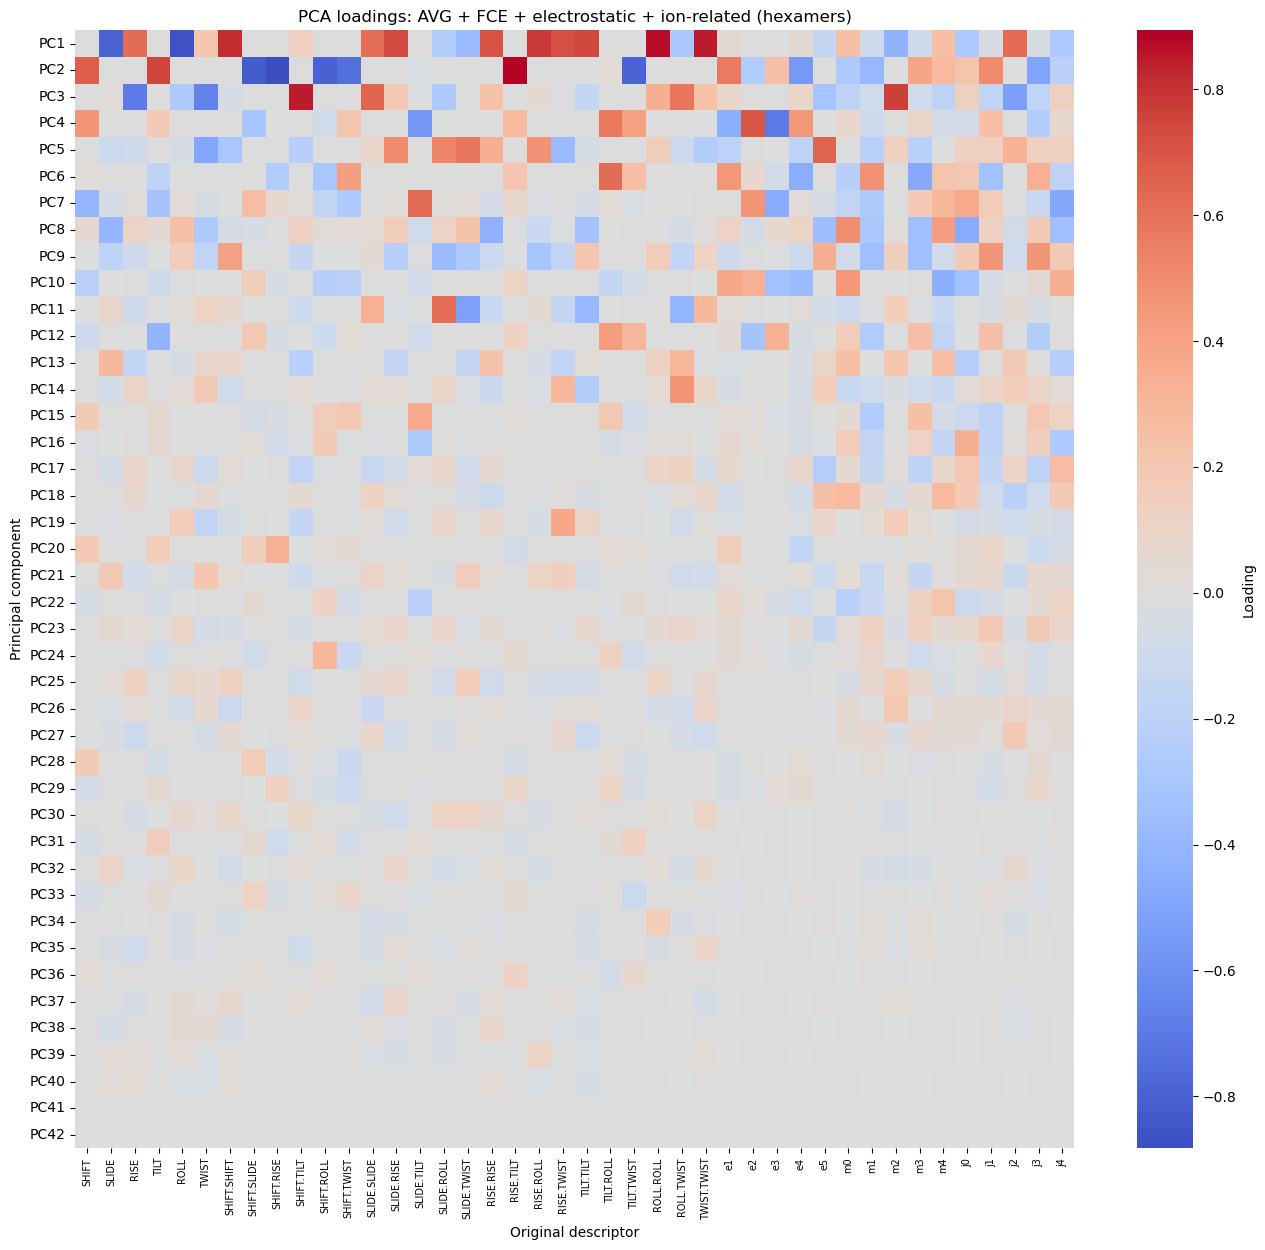

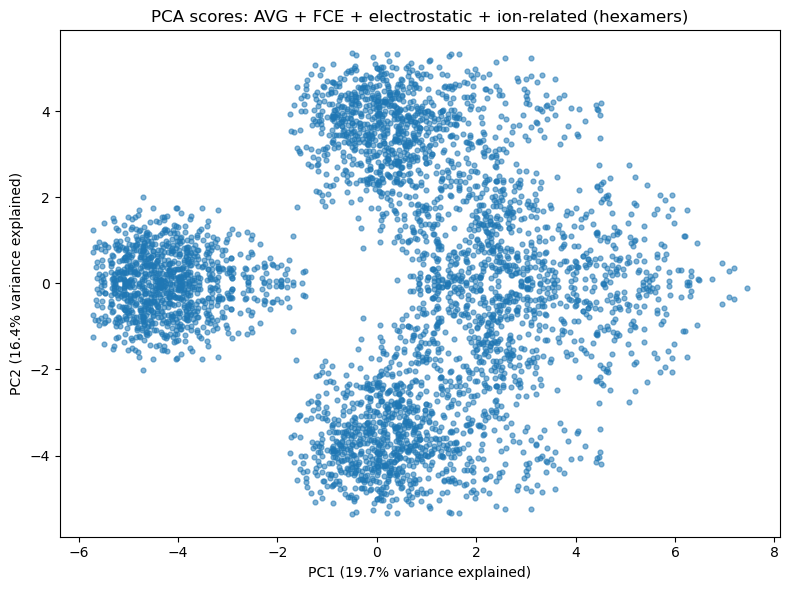

Hexamer | AVG + FCE + electrostatic + ion-related | 42 features | 4096 sequences


,Principal component,Explained variance ratio,Cumulative explained variance
0,PC1,0.1968,0.1968
1,PC2,0.1644,0.3612
2,PC3,0.0961,0.4573
3,PC4,0.0675,0.5248
4,PC5,0.0639,0.5888
5,PC6,0.0508,0.6396
6,PC7,0.0466,0.6861
7,PC8,0.0463,0.7324
8,PC9,0.0413,0.7737
9,PC10,0.0329,0.8066


,Variance threshold,Number of components
0,80%,10
1,90%,15
2,95%,20


Five largest absolute loadings on PC1 and PC2:


,Component,Descriptor,Loading
0,PC1,ROLL.ROLL,0.870
1,PC1,ROLL,-0.868
2,PC1,TWIST.TWIST,0.847
3,PC1,SHIFT.SHIFT,0.811
4,PC1,SLIDE,-0.796
5,PC2,RISE.TILT,0.894
6,PC2,SHIFT.RISE,-0.882
7,PC2,SHIFT.SLIDE,-0.825
8,PC2,SHIFT.ROLL,-0.802
9,PC2,TILT.TWIST,-0.788


Saved four plots with prefix: pca_hexamer_avg_fce_electrostatic_ion


{'features': ['SHIFT',
  'SLIDE',
  'RISE',
  'TILT',
  'ROLL',
  'TWIST',
  'SHIFT.SHIFT',
  'SHIFT.SLIDE',
  'SHIFT.RISE',
  'SHIFT.TILT',
  'SHIFT.ROLL',
  'SHIFT.TWIST',
  'SLIDE.SLIDE',
  'SLIDE.RISE',
  'SLIDE.TILT',
  'SLIDE.ROLL',
  'SLIDE.TWIST',
  'RISE.RISE',
  'RISE.TILT',
  'RISE.ROLL',
  'RISE.TWIST',
  'TILT.TILT',
  'TILT.ROLL',
  'TILT.TWIST',
  'ROLL.ROLL',
  'ROLL.TWIST',
  'TWIST.TWIST',
  'e1',
  'e2',
  'e3',
  'e4',
  'e5',
  'm0',
  'm1',
  'm2',
  'm3',
  'm4',
  'j0',
  'j1',
  'j2',
  'j3',
  'j4'],
 'pca': PCA(),
 'scores': array([[ 3.09441297e+00, -5.24154927e+00,  7.51527114e-01, ...,
          3.32912005e-02,  1.63506755e-15, -5.91428841e-15],
        [ 2.46149537e+00, -4.50056627e+00,  8.65105363e-01, ...,
          1.29117663e-01,  1.34517368e-15, -8.46494833e-15],
        [ 2.26128273e+00, -4.87867699e+00,  7.54535610e-01, ...,
          2.56965285e-02,  7.84922993e-16, -5.34840940e-15],
        ...,
        [ 1.54558278e+00,  4.56837248e+00,  7.113003

In [140]:
# Fit separate combined PCA models for tetramers and hexamers: AVG + FCE + electrostatic + ion-related
run_combined_pca(
    input_tetramer,
    "tetramer",
    'AVG + FCE + electrostatic + ion-related',
    tetramer_combined_groups,
    combined_pca_configurations['AVG + FCE + electrostatic + ion-related'],
)
run_combined_pca(
    input_hexamer,
    "hexamer",
    'AVG + FCE + electrostatic + ion-related',
    hexamer_combined_groups,
    combined_pca_configurations['AVG + FCE + electrostatic + ion-related'],
)


## 11. Cross-feature Correlation Analysis

We examine Pearson and Spearman correlations across AVG, FCE, electrostatic and ion-related descriptors, separately for tetramers and hexamers. The existing combined input tables are indexed by `SEQUENCE` for validation, while only numeric descriptor columns are passed to correlation calculations. The sequence identifier is excluded. FCE contributes its 21 unique upper-triangular elements; mirrored lower-triangle columns are omitted so each symmetric matrix element appears once. Original data tables are not changed.

Full and cross-group heatmaps are generated for both correlation methods with a common scale from −1 to +1. Strong cross-group pairs are reported using the Pearson threshold `|r| ≥ 0.7`. Pearson describes linear association; Spearman provides a rank-based measure of monotonic association. Neither high nor low correlation alone establishes redundancy or biological independence.

### 11.1. Correlation matrices and strong cross-group pairs

Feature order follows the descriptor groups: AVG, FCE, electrostatic and ion-related. The full heatmaps mark group boundaries; cross-group heatmaps compare each of the six group pairs. Figures are saved in `notebooks/plots_EDA/` using filenames that identify sequence length, method and feature groups.

In [ ]:
# Reuse the feature lists defined in the preceding descriptor analyses
cross_corr_groups = {
    "tetramer": tetramer_combined_groups,
    "hexamer": hexamer_combined_groups,
}
cross_corr_data = {
    "tetramer": input_tetramer,
    "hexamer": input_hexamer,
}
cross_corr_group_order = ["AVG", "FCE", "Electrostatic", "Ion-related"]
cross_corr_group_pairs = [
    ("AVG", "FCE"),
    ("AVG", "Electrostatic"),
    ("AVG", "Ion-related"),
    ("FCE", "Electrostatic"),
    ("FCE", "Ion-related"),
    ("Electrostatic", "Ion-related"),
]
cross_corr_methods = ["pearson", "spearman"]
cross_corr_results = {}


def prepare_cross_correlation_data(data, groups, sequence_length):
    """Validate and order each numeric descriptor exactly once by group."""
    if "SEQUENCE" not in data.columns:
        raise KeyError(f"{sequence_length} input is missing SEQUENCE.")
    if data["SEQUENCE"].duplicated().any():
        raise ValueError(f"{sequence_length} sequence identifiers are not unique.")

    numeric_columns = set(data.select_dtypes(include=np.number).columns)
    ordered_features = []
    feature_groups = {}
    for group_name in cross_corr_group_order:
        feature_names = list(groups[group_name])
        missing = sorted(set(feature_names) - set(data.columns))
        if missing:
            raise KeyError(f"Missing {group_name} columns for {sequence_length}: {missing}")
        non_numeric = [
            name for name in feature_names
            if not pd.api.types.is_numeric_dtype(data[name])
        ]
        if non_numeric:
            raise TypeError(f"Non-numeric {group_name} descriptors: {non_numeric}")
        if len(feature_names) != len(set(feature_names)):
            raise ValueError(f"Repeated descriptor names in {group_name}.")
        feature_groups[group_name] = feature_names
        ordered_features.extend(feature_names)

    if len(ordered_features) != len(set(ordered_features)):
        raise ValueError("A descriptor appears in more than one feature group.")
    if not set(ordered_features).issubset(numeric_columns):
        raise TypeError("All selected descriptors must be numeric.")

    # The input tables also contain the mirrored lower triangle of the symmetric FCE matrix.
    # Confirm that these are the only numeric columns omitted from the unique feature list.
    degrees = ["SHIFT", "SLIDE", "RISE", "TILT", "ROLL", "TWIST"]
    all_fce_columns = {f"{first}.{second}" for first in degrees for second in degrees}
    unique_fce_columns = set(feature_groups["FCE"])
    mirrored_fce_columns = all_fce_columns - unique_fce_columns
    unselected_numeric = numeric_columns - set(ordered_features)
    if unselected_numeric != mirrored_fce_columns:
        raise ValueError(
            f"Unexpected numeric columns outside the descriptor groups: "
            f"{sorted(unselected_numeric - mirrored_fce_columns)}"
        )

    numeric_data = data.loc[:, ordered_features].copy()
    if numeric_data.isna().any().any():
        raise ValueError(f"Missing numeric descriptors in {sequence_length} data.")
    return numeric_data, feature_groups


def plot_full_correlation(correlation, feature_groups, method, sequence_length):
    """Save a full feature-ordered correlation matrix with group labels."""
    feature_count = len(correlation.columns)
    fig, ax = plt.subplots(
        figsize=(max(14, feature_count * 0.34), max(12, feature_count * 0.31))
    )
    sns.heatmap(
        correlation,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax,
        cbar_kws={"label": f"{method.title()} correlation"},
    )
    boundary = 0
    for group_name in cross_corr_group_order:
        group_size = len(feature_groups[group_name])
        if boundary:
            ax.axhline(boundary, color="black", linewidth=1.2)
            ax.axvline(boundary, color="black", linewidth=1.2)
        center = boundary + group_size / 2
        ax.text(
            center, 1.035, group_name,
            transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9, fontweight="bold",
        )
        boundary += group_size

    ax.set_title(f"{method.title()} correlation: all {sequence_length} descriptors", pad=34)
    ax.set_xlabel("Descriptors (ordered by group)")
    ax.set_ylabel("Descriptors (ordered by group)")
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.tick_params(axis="y", labelrotation=0, labelsize=7)
    fig.subplots_adjust(top=0.88, bottom=0.20, left=0.20, right=0.92)
    fig.savefig(
        PLOT_DIR / f"correlation_{sequence_length}_{method}_all_features.png",
        dpi=300, bbox_inches="tight",
    )
    plt.close(fig)


def plot_cross_group_correlation(correlation, feature_groups, method, sequence_length, group_1, group_2):
    """Save one cross-group block with both group names on the axes."""
    group_1_features = feature_groups[group_1]
    group_2_features = feature_groups[group_2]
    correlation_block = correlation.loc[group_1_features, group_2_features]
    fig, ax = plt.subplots(
        figsize=(max(8, len(group_2_features) * 0.48), max(5, len(group_1_features) * 0.43))
    )
    sns.heatmap(
        correlation_block,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax,
        cbar_kws={"label": f"{method.title()} correlation"},
    )
    ax.set_title(f"{method.title()} correlation: {group_1} vs {group_2} ({sequence_length}s)")
    ax.set_xlabel(f"{group_2} descriptors")
    ax.set_ylabel(f"{group_1} descriptors")
    ax.tick_params(axis="x", labelrotation=90, labelsize=8)
    ax.tick_params(axis="y", labelrotation=0, labelsize=8)
    fig.tight_layout()
    group_slug = f"{group_1.lower().replace('-', '')}_{group_2.lower().replace('-', '')}"
    fig.savefig(
        PLOT_DIR / f"correlation_{sequence_length}_{method}_{group_slug}.png",
        dpi=300, bbox_inches="tight",
    )
    plt.close(fig)


def strong_cross_group_pairs(correlation, feature_groups, threshold=0.7):
    """Return Pearson pairs meeting the absolute-correlation threshold."""
    rows = []
    group_pairs = []
    for group_1, group_2 in cross_corr_group_pairs:
        block = correlation.loc[feature_groups[group_1], feature_groups[group_2]]
        pair_count = 0
        for descriptor_1 in block.index:
            for descriptor_2 in block.columns:
                value = block.loc[descriptor_1, descriptor_2]
                if abs(value) >= threshold:
                    rows.append({
                        "Descriptor 1": descriptor_1,
                        "Descriptor 2": descriptor_2,
                        "Group 1": group_1,
                        "Group 2": group_2,
                        "Pearson correlation": value,
                        "Absolute correlation": abs(value),
                    })
                    pair_count += 1
        group_pairs.append({
            "Group 1": group_1,
            "Group 2": group_2,
            "Strong pair count (|r| ≥ 0.7)": pair_count,
        })

    pair_table = pd.DataFrame(rows, columns=[
        "Descriptor 1", "Descriptor 2", "Group 1", "Group 2",
        "Pearson correlation", "Absolute correlation",
    ]).sort_values("Absolute correlation", ascending=False, ignore_index=True)
    return pair_table, pd.DataFrame(group_pairs)


# Calculate the two correlation matrices and save full and cross-group heatmaps
for sequence_length, data in cross_corr_data.items():
    numeric_data, feature_groups = prepare_cross_correlation_data(
        data, cross_corr_groups[sequence_length], sequence_length
    )
    print(
        f"{sequence_length.title()}: {len(numeric_data)} sequences, "
        f"{numeric_data.shape[1]} unique numeric descriptors "
        f"(excluding SEQUENCE and mirrored FCE entries)."
    )

    correlations = {}
    for method in cross_corr_methods:
        correlations[method] = numeric_data.corr(method=method)
        plot_full_correlation(
            correlations[method], feature_groups, method, sequence_length
        )
        for group_1, group_2 in cross_corr_group_pairs:
            plot_cross_group_correlation(
                correlations[method], feature_groups, method,
                sequence_length, group_1, group_2,
            )

    pearson_pairs, group_pair_counts = strong_cross_group_pairs(
        correlations["pearson"], feature_groups
    )
    cross_corr_results[sequence_length] = {
        "features": numeric_data.columns.tolist(),
        "feature_groups": feature_groups,
        "pearson": correlations["pearson"],
        "spearman": correlations["spearman"],
        "strong_pearson_pairs": pearson_pairs,
        "strong_pair_counts": group_pair_counts,
    }

    print(f"\n{sequence_length.title()} strong cross-group Pearson pairs (|r| ≥ 0.7):")
    display(pearson_pairs.round({"Pearson correlation": 4, "Absolute correlation": 4}))
    print("Strong pair count by descriptor-group combination:")
    display(group_pair_counts)
    print("Saved 14 full and cross-group heatmaps for Pearson and Spearman correlations.")


### 11.2. Tetramer results

**Observed results.** The strongest Pearson relationships occur between AVG and FCE (9 pairs at `|r| ≥ 0.7`), followed by AVG and ion-related descriptors (3 pairs). No cross-group pairs involving electrostatic descriptors reach the threshold. The largest individual association is `RISE`–`m2` (`r = −0.8747`); several strong AVG–FCE pairs include `TILT`–`SHIFT.SLIDE` (`r = −0.8570`) and `ROLL`–`ROLL.ROLL` (`r = −0.8468`). The Spearman heatmap shows a similar concentration of strong patterns, with rank associations also present for these pairs.

These results indicate shared variation between some AVG and FCE measurements, and between selected AVG and ion-related measurements. Other descriptors may contribute additional variation, but low correlations do not establish independence and high correlations do not establish complete redundancy.

### 11.3. Hexamer results and comparison

**Observed results.** The same group ordering is evident: AVG–FCE has the most strong Pearson pairs (6), AVG–ion-related has 1, and the remaining four group combinations have none at the threshold. The strongest pair is again `RISE`–`m2` (`r = −0.8478`), followed by AVG–FCE pairs such as `TILT`–`SHIFT.SLIDE` (`r = −0.8368`) and `SHIFT`–`SHIFT.SLIDE` (`r = −0.8301`). The Spearman heatmap preserves these main patterns.

Seven strong Pearson pairs are common to both sequence lengths: six AVG–FCE pairs and `RISE`–`m2`. Tetramers have five additional pairs above the threshold. This suggests broadly similar cross-group relationships, with some differences in which pairs exceed the chosen cutoff. These correlations describe the observed descriptor data; they do not establish biological independence or complete redundancy.